# Comparative Analysis of Semantic, Sparse, and Graph-Based Retrieval in RAG Pipelines

**A hands-on tutorial — from raw records to grounded, citation-backed answers**

| | |
|---|---|
| **Format** | 60-minute hands-on lab (run every cell live) |
| **Domain** | Synthetic e-commerce electronics catalogue ("Zephyr Electronics") |
| **Stack** | `sentence-transformers` · `ChromaDB` · custom BM25 · `NetworkX` |
| **Runtime** | ~2–3 minutes of compute for the whole notebook (CPU only) |

---

### What you will be able to do after this session

1. Explain *what* each retrieval family actually indexes, in one sentence each.
2. Predict which retriever will win for a given user query — before running it.
3. Build all three from scratch, then fuse them with Reciprocal Rank Fusion.
4. Measure retrieval quality with Hit@k, MRR and nDCG instead of eyeballing results.
5. Build an answering layer that **cannot** hallucinate, because every claim is
   traceable to a retrieved span — and that **abstains** when evidence is missing.

### Agenda (60 minutes)

| Time | Section | What happens |
|---|---|---|
| 0–05 | **1. Why retrieval decides RAG quality** | Architecture, failure surfaces, family comparison |
| 05–15 | **2. Synthetic data** | Generate a realistic catalogue, reviews, policies, relations |
| 15–18 | **3. Records → retrieval units** | Chunking, metadata, token budgets |
| 18–33 | **4. Semantic (dense) retrieval** | Embeddings, cosine similarity, ChromaDB + HNSW |
| 33–43 | **5. Sparse (lexical) retrieval** | Inverted index, TF-IDF, BM25 from scratch |
| 43–53 | **6. Graph-based retrieval** | Knowledge graph, multi-hop traversal, GraphRAG |
| 53–56 | **7. Hybrid retrieval** | RRF fusion + graph neighbourhood boost |
| 56–60 | **8. Evaluation & grounded answering** | Metrics, per-intent wins, zero-hallucination answers |

> **Instructor tip:** sections 4–6 each end with a *deliberate failure* demo.
> Do not skip them — the failures are what motivate the hybrid in section 7.

### Prerequisites

The notebook was validated end-to-end on **Python 3.14 / Windows 11** in a
dedicated virtual environment. To reproduce it:

```bash
python -m venv --system-site-packages .venv
.venv\Scripts\python.exe -m pip install -r requirements.txt
.venv\Scripts\python.exe -m ipykernel install --user --name rag-seminar
.venv\Scripts\python.exe -m jupyterlab
```

Everything runs on CPU. The embedding model (`all-MiniLM-L6-v2`, 22M parameters,
384 dimensions) is downloaded once (~90 MB) and cached by Hugging Face, so a
re-run works offline.

In [1]:
# ---------------------------------------------------------------------------
# 0.1  Environment, imports, and global configuration
# ---------------------------------------------------------------------------
import os

# Must be set BEFORE importing transformers / chromadb.
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["ANONYMIZED_TELEMETRY"] = "False"

import hashlib
import json
import logging
import math
import random
import re
import textwrap
import time
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

# Keep the notebook output clean during a live session.
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("sentence_transformers").setLevel(logging.ERROR)
logging.getLogger("chromadb").setLevel(logging.ERROR)

SEED = 20261114
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 95)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "font.size": 10,
})

PALETTE = {
    "semantic": "#2563eb",
    "sparse": "#ea580c",
    "graph": "#059669",
    "hybrid": "#7c3aed",
    "muted": "#64748b",
}

print(f"Working directory : {BASE_DIR}")
print(f"Data directory    : {DATA_DIR}")
print(f"Random seed       : {SEED}")

Working directory : D:\Seminar_RAG_10Nov2026
Data directory    : D:\Seminar_RAG_10Nov2026\data
Random seed       : 20261114


In [2]:
# ---------------------------------------------------------------------------
# 0.2  Small display helpers so every cell prints consistently
# ---------------------------------------------------------------------------
def show(obj, n: int = 8):
    """Display a DataFrame (truncated) or any other object."""
    if isinstance(obj, pd.DataFrame):
        display(obj.head(n) if len(obj) > n else obj)
    elif isinstance(obj, pd.Series):
        display(obj.head(n) if len(obj) > n else obj)
    else:
        display(obj)


def section(title: str, subtitle: str = "") -> None:
    """Print a visual divider between demo steps."""
    print("\n" + "=" * 78)
    print(title.upper())
    if subtitle:
        print(subtitle)
    print("=" * 78)

In [3]:
# ---------------------------------------------------------------------------
# 0.3  Dependency check — names what is missing, never crashes
# ---------------------------------------------------------------------------
import importlib

REQUIRED = {
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "networkx": "networkx",
    "rank_bm25": "rank-bm25",
    "sentence_transformers": "sentence-transformers",
    "chromadb": "chromadb",
    "torch": "torch",
}

missing, versions = [], {}
for mod_name, pip_name in REQUIRED.items():
    try:
        mod = importlib.import_module(mod_name)
        versions[pip_name] = getattr(mod, "__version__", "installed")
    except Exception:
        missing.append(pip_name)

if missing:
    print("Missing packages:", ", ".join(missing))
    print("Install with:\n  pip install " + " ".join(missing))
else:
    print("All dependencies present.\n")
    for name, ver in versions.items():
        print(f"  {name:<22} {ver}")

All dependencies present.

  numpy                  2.5.0
  pandas                 3.0.3
  scikit-learn           1.9.0
  matplotlib             3.11.0
  networkx               3.7
  rank-bm25              installed
  sentence-transformers  6.2.0
  chromadb               1.5.9
  torch                  2.15.0+cpu


---
# 1. Why retrieval decides RAG quality

A RAG pipeline has four moving parts:

```
  user query ──► RETRIEVER ──► CONTEXT PACKER ──► GENERATOR ──► answer
                    ▲
             sparse / dense / graph indexes
```

The generator can only reason over what the retriever hands it. If the right
passage never enters the context window, the model has two options: **say "I
don't know"** (rare in practice) or **invent something plausible** (common).
Retrieval quality is therefore the single largest lever on both *accuracy* and
*hallucination rate*.

### The three families, in one sentence each

| Family | Indexes | Wins when | Blind spot |
|---|---|---|---|
| **Sparse / lexical** (BM25) | Exact terms + statistics (TF, IDF) | Query contains rare tokens: SKUs, model numbers, error codes, `IP68`, `65W` | No synonymy — "inexpensive" never matches "budget" |
| **Semantic / dense** | Learned 384-d vectors of meaning | Paraphrase, intent, vague descriptions | Numbers and identifiers get blurred into "similar-looking" text |
| **Graph** | Entities + typed relations | Multi-hop and constraint questions: *compatible with*, *replaced by*, *applies to* | Coverage — a missing edge means a missing answer |

These are **complementary failure modes**, which is exactly why production
systems run hybrids.

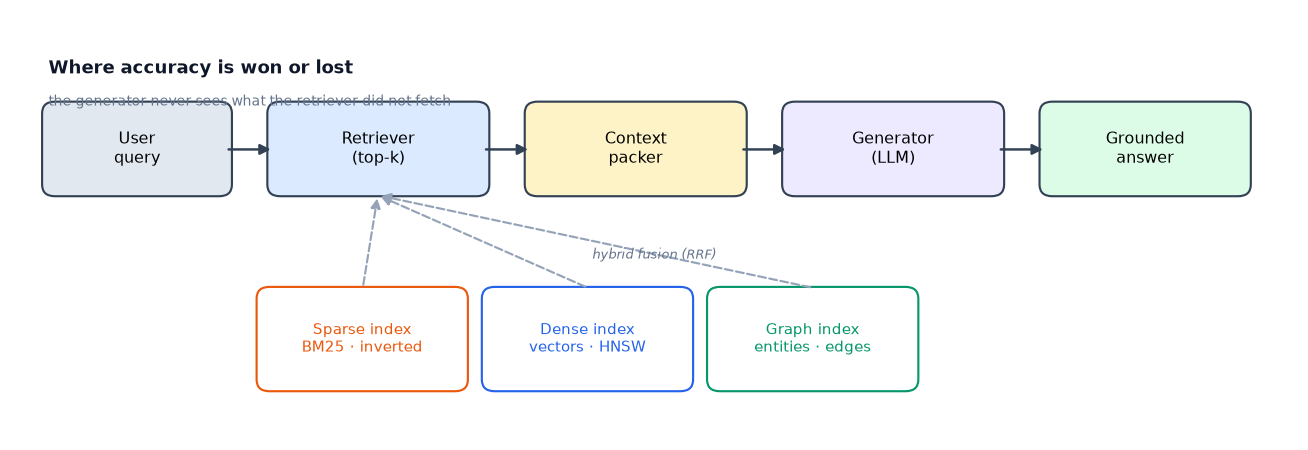

In [4]:
# ---------------------------------------------------------------------------
# 1.1  Draw the RAG pipeline
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.set_xlim(0, 12)
ax.set_ylim(0, 4.4)
ax.axis("off")

boxes = [
    (0.35, 2.55, 1.65, 0.85, "User\nquery", "#e2e8f0"),
    (2.45, 2.55, 1.95, 0.85, "Retriever\n(top-k)", "#dbeafe"),
    (4.85, 2.55, 1.95, 0.85, "Context\npacker", "#fef3c7"),
    (7.25, 2.55, 1.95, 0.85, "Generator\n(LLM)", "#ede9fe"),
    (9.65, 2.55, 1.85, 0.85, "Grounded\nanswer", "#dcfce7"),
]
for x, y, w, h, label, color in boxes:
    ax.add_patch(FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0.06,rounding_size=0.12",
        linewidth=1.4, edgecolor="#334155", facecolor=color))
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center", fontsize=10.5)

for x0, x1 in [(2.0, 2.45), (4.4, 4.85), (6.8, 7.25), (9.2, 9.65)]:
    ax.add_patch(FancyArrowPatch((x0, 2.97), (x1, 2.97), arrowstyle="-|>",
                                 mutation_scale=14, linewidth=1.6, color="#334155"))

index_boxes = [
    (2.35, 0.55, 1.85, 0.95, "Sparse index\nBM25 · inverted", PALETTE["sparse"]),
    (4.45, 0.55, 1.85, 0.95, "Dense index\nvectors · HNSW", PALETTE["semantic"]),
    (6.55, 0.55, 1.85, 0.95, "Graph index\nentities · edges", PALETTE["graph"]),
]
for x, y, w, h, label, color in index_boxes:
    ax.add_patch(FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0.06,rounding_size=0.12",
        linewidth=1.4, edgecolor=color, facecolor="white"))
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center",
            fontsize=9.5, color=color)

for x in (3.28, 5.38, 7.48):
    ax.add_patch(FancyArrowPatch((x, 1.55), (3.42, 2.5), arrowstyle="-|>",
                                 mutation_scale=13, linewidth=1.4,
                                 color="#94a3b8", linestyle="--"))

ax.text(6.0, 1.85, "hybrid fusion (RRF)", ha="center", fontsize=8.5,
        color=PALETTE["muted"], style="italic")
ax.text(0.35, 3.75, "Where accuracy is won or lost", fontsize=12,
        fontweight="bold", color="#0f172a")
ax.text(0.35, 3.42, "the generator never sees what the retriever did not fetch",
        fontsize=9, color=PALETTE["muted"])
plt.tight_layout()
plt.show()

---
# 2. Manufacturing a realistic dataset

Public product datasets are either tiny, or clean in ways real catalogues never
are. We need **controlled difficulty**: near-duplicate model names, inconsistent
casing, synonyms, numeric constraints, and long-tail specs. So we generate our
own â€” deterministic, fully labelled, and free of licensing issues.

### What we build

| Table | Rows | Purpose |
|---|---|---|
| `products` | ~200 | The corpus: title, brand, category, price, specs, warranty |
| `reviews` | ~700 | Realistic opinions, including negative ones and Hinglish |
| `policies` | 25 | Return/warranty/EMI/shipping documents â€” abstract queries |
| `relations` | ~500 | Typed edges that become the knowledge graph |

### Schema (products)

| Column | Type | Notes |
|---|---|---|
| `product_id` | str | `ZP0001` â€¦ stable primary key |
| `sku` | str | `SONY-WH1000XM5-BLK` â€” the exact-match target for BM25 |
| `title` | str | Marketing title, sometimes with casing noise |
| `brand`, `category`, `subcategory` | str | Facets for metadata filtering |
| `price_inr`, `mrp_inr` | int | Price is always â‰¤ MRP |
| `rating`, `rating_count` | float/int | Long-tailed popularity |
| `warranty_months` | int | 6 / 12 / 24 / 36 |
| `specs` | dict | Category-specific; rendered into a spec chunk |
| `description` | str | 3â€“5 sentences, generated from the specs |

The catalogue deliberately contains **near-duplicates** such as
`Sony WH-1000XM4`, `WH-1000XM5` and `WH-1000XM6`, plus numeric specs like
`65W`, `IP68`, `RTX 4060`. These are precisely the tokens that dense models
blur and sparse models nail.

In [5]:
# ---------------------------------------------------------------------------
# 2.1  The product families (hand-curated for realism)
# ---------------------------------------------------------------------------
# Row format: (brand, model, price_inr, specs-overrides)
CATALOG = {
    "Headphones": [
        ("Sony", "WH-1000XM4", 24990, {"anc": True, "battery_hrs": 30, "driver_mm": 40, "weight_g": 254}),
        ("Sony", "WH-1000XM5", 29990, {"anc": True, "battery_hrs": 30, "driver_mm": 30, "weight_g": 250}),
        ("Sony", "WH-1000XM6", 34990, {"anc": True, "battery_hrs": 32, "driver_mm": 30, "weight_g": 248}),
        ("Bose", "QuietComfort 45", 27900, {"anc": True, "battery_hrs": 24, "driver_mm": 40, "weight_g": 238}),
        ("Bose", "QuietComfort Ultra", 35900, {"anc": True, "battery_hrs": 24, "driver_mm": 35, "weight_g": 250}),
        ("Sennheiser", "Momentum 4", 29990, {"anc": True, "battery_hrs": 60, "driver_mm": 42, "weight_g": 293}),
        ("JBL", "Tune 770NC", 6999, {"anc": True, "battery_hrs": 70, "driver_mm": 40, "weight_g": 232}),
        ("JBL", "Live 770NC", 12999, {"anc": True, "battery_hrs": 65, "driver_mm": 40, "weight_g": 253}),
        ("boAt", "Rockerz 550", 2499, {"anc": False, "battery_hrs": 20, "driver_mm": 50, "weight_g": 245}),
        ("boAt", "Nirvana 751", 1999, {"anc": True, "battery_hrs": 50, "driver_mm": 40, "weight_g": 218}),
        ("Noise", "Halo 2", 4499, {"anc": True, "battery_hrs": 60, "driver_mm": 40, "weight_g": 240}),
        ("Audio-Technica", "ATH-M50xBT2", 19990, {"anc": False, "battery_hrs": 50, "driver_mm": 45, "weight_g": 307}),
        ("Apple", "AirPods Max", 59900, {"anc": True, "battery_hrs": 20, "driver_mm": 40, "weight_g": 385}),
        ("Marshall", "Major V", 12999, {"anc": False, "battery_hrs": 100, "driver_mm": 40, "weight_g": 186}),
    ],
    "Earbuds": [
        ("Apple", "AirPods Pro 2", 22900, {"anc": True, "battery_hrs": 6, "ip_rating": "IP54", "wireless_charging": True}),
        ("Apple", "AirPods 4", 12900, {"anc": True, "battery_hrs": 5, "ip_rating": "IP54", "wireless_charging": False}),
        ("Sony", "WF-1000XM4", 16990, {"anc": True, "battery_hrs": 8, "ip_rating": "IPX4", "wireless_charging": True}),
        ("Sony", "WF-1000XM5", 21990, {"anc": True, "battery_hrs": 8, "ip_rating": "IPX4", "wireless_charging": True}),
        ("Sony", "WF-C700N", 8990, {"anc": True, "battery_hrs": 7, "ip_rating": "IPX4", "wireless_charging": False}),
        ("Samsung", "Galaxy Buds3 Pro", 19999, {"anc": True, "battery_hrs": 6, "ip_rating": "IP57", "wireless_charging": True}),
        ("Samsung", "Galaxy Buds FE", 4999, {"anc": True, "battery_hrs": 6, "ip_rating": "IPX2", "wireless_charging": False}),
        ("boAt", "Airdopes 141", 1299, {"anc": False, "battery_hrs": 6, "ip_rating": "IPX4", "wireless_charging": False}),
        ("boAt", "Airdopes 311 Pro", 1799, {"anc": True, "battery_hrs": 5, "ip_rating": "IP68", "wireless_charging": False}),
        ("boAt", "Airdopes 800", 2999, {"anc": True, "battery_hrs": 7, "ip_rating": "IPX5", "wireless_charging": False}),
        ("Noise", "Buds VS104", 1199, {"anc": False, "battery_hrs": 5, "ip_rating": "IPX4", "wireless_charging": False}),
        ("Noise", "Buds Xero", 1999, {"anc": True, "battery_hrs": 6, "ip_rating": "IP68", "wireless_charging": False}),
        ("OnePlus", "Buds Pro 3", 11999, {"anc": True, "battery_hrs": 7, "ip_rating": "IP55", "wireless_charging": True}),
        ("OnePlus", "Nord Buds 3", 2799, {"anc": True, "battery_hrs": 8, "ip_rating": "IP55", "wireless_charging": False}),
        ("JBL", "Tune Buds", 5999, {"anc": True, "battery_hrs": 7, "ip_rating": "IP54", "wireless_charging": False}),
        ("JBL", "Live Pro 2", 11999, {"anc": True, "battery_hrs": 8, "ip_rating": "IPX5", "wireless_charging": True}),
        ("Realme", "Buds Air 6 Pro", 4999, {"anc": True, "battery_hrs": 6, "ip_rating": "IP55", "wireless_charging": False}),
        ("Nothing", "Ear (a)", 7999, {"anc": True, "battery_hrs": 8, "ip_rating": "IP54", "wireless_charging": False}),
        ("Nothing", "Ear (2)", 9999, {"anc": True, "battery_hrs": 7, "ip_rating": "IP54", "wireless_charging": True}),
        ("Oppo", "Enco Air 4 Pro", 4999, {"anc": True, "battery_hrs": 7, "ip_rating": "IP55", "wireless_charging": False}),
        ("Sennheiser", "CX Plus", 9990, {"anc": True, "battery_hrs": 8, "ip_rating": "IPX4", "wireless_charging": False}),
        ("Google", "Pixel Buds Pro 2", 22900, {"anc": True, "battery_hrs": 8, "ip_rating": "IP54", "wireless_charging": True}),
        ("Anker", "Soundcore Liberty 4 NC", 7999, {"anc": True, "battery_hrs": 10, "ip_rating": "IPX4", "wireless_charging": True}),
    ],
    "Smartphones": [
        ("Apple", "iPhone 14", 59900, {"ram_gb": 6, "storage_gb": 128, "battery_mah": 3279, "camera_mp": 12, "5g": True}),
        ("Apple", "iPhone 15", 69900, {"ram_gb": 6, "storage_gb": 128, "battery_mah": 3349, "camera_mp": 48, "5g": True}),
        ("Apple", "iPhone 15 Pro", 129900, {"ram_gb": 8, "storage_gb": 256, "battery_mah": 3274, "camera_mp": 48, "5g": True}),
        ("Apple", "iPhone 16", 79900, {"ram_gb": 8, "storage_gb": 128, "battery_mah": 3561, "camera_mp": 48, "5g": True}),
        ("Samsung", "Galaxy S24", 74999, {"ram_gb": 8, "storage_gb": 256, "battery_mah": 4000, "camera_mp": 50, "5g": True}),
        ("Samsung", "Galaxy S23 FE", 49999, {"ram_gb": 8, "storage_gb": 128, "battery_mah": 4500, "camera_mp": 50, "5g": True}),
        ("Samsung", "Galaxy M35 5G", 16999, {"ram_gb": 6, "storage_gb": 128, "battery_mah": 6000, "camera_mp": 50, "5g": True}),
        ("Samsung", "Galaxy A55 5G", 27999, {"ram_gb": 8, "storage_gb": 128, "battery_mah": 5000, "camera_mp": 50, "5g": True}),
        ("OnePlus", "12R", 39999, {"ram_gb": 8, "storage_gb": 128, "battery_mah": 5500, "camera_mp": 50, "5g": True}),
        ("OnePlus", "Nord CE4", 24999, {"ram_gb": 8, "storage_gb": 128, "battery_mah": 5500, "camera_mp": 50, "5g": True}),
        ("OnePlus", "13", 69999, {"ram_gb": 12, "storage_gb": 256, "battery_mah": 6000, "camera_mp": 50, "5g": True}),
        ("Google", "Pixel 8a", 49999, {"ram_gb": 8, "storage_gb": 128, "battery_mah": 4492, "camera_mp": 64, "5g": True}),
        ("Google", "Pixel 9", 79999, {"ram_gb": 12, "storage_gb": 256, "battery_mah": 4700, "camera_mp": 50, "5g": True}),
        ("Xiaomi", "Redmi Note 13 Pro", 23999, {"ram_gb": 8, "storage_gb": 256, "battery_mah": 5100, "camera_mp": 200, "5g": True}),
        ("Xiaomi", "Xiaomi 14", 69999, {"ram_gb": 12, "storage_gb": 256, "battery_mah": 4610, "camera_mp": 50, "5g": True}),
        ("Realme", "12 Pro+", 29999, {"ram_gb": 8, "storage_gb": 256, "battery_mah": 5000, "camera_mp": 50, "5g": True}),
        ("Realme", "GT 6", 40999, {"ram_gb": 12, "storage_gb": 256, "battery_mah": 5500, "camera_mp": 50, "5g": True}),
        ("Nothing", "Phone (2a)", 23999, {"ram_gb": 8, "storage_gb": 128, "battery_mah": 5000, "camera_mp": 50, "5g": True}),
        ("Vivo", "V30 Pro", 41999, {"ram_gb": 8, "storage_gb": 256, "battery_mah": 5000, "camera_mp": 50, "5g": True}),
        ("iQOO", "Z9", 19999, {"ram_gb": 8, "storage_gb": 128, "battery_mah": 6000, "camera_mp": 50, "5g": True}),
        ("Motorola", "Edge 50 Pro", 31999, {"ram_gb": 8, "storage_gb": 256, "battery_mah": 4500, "camera_mp": 50, "5g": True}),
        ("Motorola", "Moto G84", 19999, {"ram_gb": 8, "storage_gb": 256, "battery_mah": 5000, "camera_mp": 50, "5g": True}),
        ("Oppo", "Reno 12 Pro", 36999, {"ram_gb": 12, "storage_gb": 256, "battery_mah": 5000, "camera_mp": 50, "5g": True}),
        ("Poco", "X6 Pro", 23999, {"ram_gb": 8, "storage_gb": 256, "battery_mah": 5000, "camera_mp": 64, "5g": True}),
    ],
    "Laptops": [
        ("Apple", "MacBook Air M3 13", 114900, {"ram_gb": 8, "storage_gb": 256, "processor": "Apple M3", "gpu": "Integrated", "screen_inch": 13.6, "weight_kg": 1.24}),
        ("Apple", "MacBook Pro 14 M3 Pro", 199900, {"ram_gb": 18, "storage_gb": 512, "processor": "Apple M3 Pro", "gpu": "Integrated", "screen_inch": 14.2, "weight_kg": 1.61}),
        ("Dell", "XPS 15 9530", 159990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core i7-13700H", "gpu": "NVIDIA RTX 4050", "screen_inch": 15.6, "weight_kg": 1.86}),
        ("Dell", "Inspiron 14 5430", 62990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core i5-1340P", "gpu": "Integrated", "screen_inch": 14.0, "weight_kg": 1.55}),
        ("Dell", "Latitude 5440", 89990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core i5-1345U", "gpu": "Integrated", "screen_inch": 14.0, "weight_kg": 1.37}),
        ("HP", "Pavilion 15", 54990, {"ram_gb": 16, "storage_gb": 512, "processor": "AMD Ryzen 5 7530U", "gpu": "Integrated", "screen_inch": 15.6, "weight_kg": 1.75}),
        ("HP", "Envy x360", 84990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core i5-1335U", "gpu": "Integrated", "screen_inch": 14.0, "weight_kg": 1.39}),
        ("HP", "Omen 16", 129990, {"ram_gb": 16, "storage_gb": 1024, "processor": "Intel Core i7-13700HX", "gpu": "NVIDIA RTX 4060", "screen_inch": 16.1, "weight_kg": 2.37}),
        ("Lenovo", "ThinkPad X1 Carbon Gen 12", 169990, {"ram_gb": 32, "storage_gb": 1024, "processor": "Intel Core Ultra 7 155U", "gpu": "Integrated", "screen_inch": 14.0, "weight_kg": 1.09}),
        ("Lenovo", "IdeaPad Slim 5", 57990, {"ram_gb": 16, "storage_gb": 512, "processor": "AMD Ryzen 5 7530U", "gpu": "Integrated", "screen_inch": 15.6, "weight_kg": 1.66}),
        ("Lenovo", "Legion 5 Pro", 139990, {"ram_gb": 16, "storage_gb": 1024, "processor": "AMD Ryzen 7 7745HX", "gpu": "NVIDIA RTX 4060", "screen_inch": 16.0, "weight_kg": 2.49}),
        ("Lenovo", "LOQ 15", 72990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core i5-12450HX", "gpu": "NVIDIA RTX 3050", "screen_inch": 15.6, "weight_kg": 2.38}),
        ("Asus", "ROG Strix G16", 149990, {"ram_gb": 16, "storage_gb": 1024, "processor": "Intel Core i7-13650HX", "gpu": "NVIDIA RTX 4070", "screen_inch": 16.0, "weight_kg": 2.50}),
        ("Asus", "VivoBook 15", 46990, {"ram_gb": 8, "storage_gb": 512, "processor": "Intel Core i3-1215U", "gpu": "Integrated", "screen_inch": 15.6, "weight_kg": 1.70}),
        ("Asus", "Zenbook 14 OLED", 99990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core Ultra 7 155H", "gpu": "Integrated", "screen_inch": 14.0, "weight_kg": 1.22}),
        ("Asus", "TUF A15", 79990, {"ram_gb": 16, "storage_gb": 512, "processor": "AMD Ryzen 7 7435HS", "gpu": "NVIDIA RTX 4050", "screen_inch": 15.6, "weight_kg": 2.30}),
        ("Acer", "Aspire 5", 42990, {"ram_gb": 8, "storage_gb": 512, "processor": "Intel Core i5-1235U", "gpu": "Integrated", "screen_inch": 15.6, "weight_kg": 1.77}),
        ("Acer", "Nitro V 15", 69990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core i5-13420H", "gpu": "NVIDIA RTX 4050", "screen_inch": 15.6, "weight_kg": 2.10}),
        ("MSI", "Katana 15", 89990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core i7-13620H", "gpu": "NVIDIA RTX 4060", "screen_inch": 15.6, "weight_kg": 2.25}),
        ("Samsung", "Galaxy Book4 Pro", 129990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core Ultra 7 155H", "gpu": "Integrated", "screen_inch": 14.0, "weight_kg": 1.23}),
        ("Microsoft", "Surface Laptop 6", 139990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core Ultra 7 165H", "gpu": "Integrated", "screen_inch": 13.5, "weight_kg": 1.38}),
        ("Xiaomi", "RedmiBook Pro 15", 59990, {"ram_gb": 16, "storage_gb": 512, "processor": "Intel Core i5-12450H", "gpu": "Integrated", "screen_inch": 15.6, "weight_kg": 1.80}),
    ],
    "Smartwatches": [
        ("Apple", "Watch Series 9", 41900, {"display_inch": 1.9, "battery_hrs": 18, "gps": True, "amoled": True}),
        ("Apple", "Watch SE 2", 29900, {"display_inch": 1.78, "battery_hrs": 18, "gps": True, "amoled": True}),
        ("Apple", "Watch Ultra 2", 89900, {"display_inch": 1.99, "battery_hrs": 36, "gps": True, "amoled": True}),
        ("Samsung", "Galaxy Watch6", 29999, {"display_inch": 1.3, "battery_hrs": 40, "gps": True, "amoled": True}),
        ("Samsung", "Galaxy Watch7", 32999, {"display_inch": 1.3, "battery_hrs": 30, "gps": True, "amoled": True}),
        ("Samsung", "Galaxy Fit3", 3999, {"display_inch": 1.6, "battery_hrs": 312, "gps": False, "amoled": True}),
        ("Noise", "ColorFit Pro 5", 4499, {"display_inch": 1.85, "battery_hrs": 168, "gps": False, "amoled": True}),
        ("Noise", "ColorFit Ultra 3", 3999, {"display_inch": 1.96, "battery_hrs": 168, "gps": False, "amoled": True}),
        ("boAt", "Lunar Call Pro", 2999, {"display_inch": 1.39, "battery_hrs": 168, "gps": False, "amoled": True}),
        ("boAt", "Storm Plus", 3499, {"display_inch": 1.96, "battery_hrs": 120, "gps": False, "amoled": True}),
        ("Amazfit", "GTR 4", 14999, {"display_inch": 1.43, "battery_hrs": 336, "gps": True, "amoled": True}),
        ("Amazfit", "Bip 5", 4999, {"display_inch": 1.91, "battery_hrs": 240, "gps": True, "amoled": False}),
        ("OnePlus", "Watch 2", 24999, {"display_inch": 1.43, "battery_hrs": 100, "gps": True, "amoled": True}),
        ("Google", "Pixel Watch 2", 29900, {"display_inch": 1.2, "battery_hrs": 24, "gps": True, "amoled": True}),
        ("Fire-Boltt", "Phoenix Ultra", 1799, {"display_inch": 1.96, "battery_hrs": 120, "gps": False, "amoled": True}),
        ("Fastrack", "Reflex Vox", 2999, {"display_inch": 1.85, "battery_hrs": 168, "gps": False, "amoled": True}),
    ],
    "Cameras": [
        ("Canon", "EOS R50", 69990, {"sensor_mp": 24.2, "sensor": "APS-C CMOS", "mount": "Canon RF", "video": "4K30"}),
        ("Canon", "EOS R6 Mark II", 199990, {"sensor_mp": 24.2, "sensor": "Full-frame CMOS", "mount": "Canon RF", "video": "4K60"}),
        ("Canon", "EOS 1500D", 34990, {"sensor_mp": 24.1, "sensor": "APS-C CMOS", "mount": "Canon EF", "video": "1080p30"}),
        ("Nikon", "Z50", 79990, {"sensor_mp": 20.9, "sensor": "APS-C CMOS", "mount": "Nikon Z", "video": "4K30"}),
        ("Nikon", "Z6 II", 169990, {"sensor_mp": 24.5, "sensor": "Full-frame CMOS", "mount": "Nikon Z", "video": "4K60"}),
        ("Nikon", "D5600", 44990, {"sensor_mp": 24.2, "sensor": "APS-C CMOS", "mount": "Nikon F", "video": "1080p60"}),
        ("Sony", "Alpha A6700", 129990, {"sensor_mp": 26.0, "sensor": "APS-C CMOS", "mount": "Sony E", "video": "4K120"}),
        ("Sony", "Alpha A7 IV", 219990, {"sensor_mp": 33.0, "sensor": "Full-frame CMOS", "mount": "Sony E", "video": "4K60"}),
        ("Sony", "ZV-E10", 69990, {"sensor_mp": 24.2, "sensor": "APS-C CMOS", "mount": "Sony E", "video": "4K30"}),
        ("Fujifilm", "X-T5", 159990, {"sensor_mp": 40.2, "sensor": "APS-C X-Trans", "mount": "Fujifilm X", "video": "6K30"}),
        ("Fujifilm", "X-S20", 129990, {"sensor_mp": 26.1, "sensor": "APS-C X-Trans", "mount": "Fujifilm X", "video": "6K30"}),
        ("Panasonic", "Lumix G7", 49990, {"sensor_mp": 16.0, "sensor": "Micro Four Thirds", "mount": "Micro Four Thirds", "video": "4K30"}),
        ("GoPro", "Hero 12 Black", 39990, {"sensor_mp": 27.0, "sensor": "1/1.9 inch CMOS", "mount": "GoPro", "video": "5.3K60"}),
        ("DJI", "Osmo Action 4", 28990, {"sensor_mp": 10.0, "sensor": "1/1.3 inch CMOS", "mount": "DJI", "video": "4K120"}),
    ],
    "Speakers": [
        ("JBL", "Flip 6", 9999, {"battery_hrs": 12, "ip_rating": "IP67", "watts": 30, "party_mode": True}),
        ("JBL", "Charge 5", 14999, {"battery_hrs": 20, "ip_rating": "IP67", "watts": 40, "party_mode": True}),
        ("JBL", "Go 4", 3999, {"battery_hrs": 7, "ip_rating": "IP67", "watts": 4.2, "party_mode": False}),
        ("JBL", "PartyBox 110", 29999, {"battery_hrs": 12, "ip_rating": "IPX4", "watts": 160, "party_mode": True}),
        ("Sony", "SRS-XB13", 3999, {"battery_hrs": 16, "ip_rating": "IP67", "watts": 5, "party_mode": False}),
        ("Sony", "SRS-XG300", 24990, {"battery_hrs": 25, "ip_rating": "IP67", "watts": 100, "party_mode": True}),
        ("Sony", "ULT Field 1", 9990, {"battery_hrs": 12, "ip_rating": "IP67", "watts": 30, "party_mode": True}),
        ("boAt", "Stone 350", 1499, {"battery_hrs": 12, "ip_rating": "IPX7", "watts": 10, "party_mode": False}),
        ("boAt", "Stone 1200", 3499, {"battery_hrs": 9, "ip_rating": "IPX5", "watts": 14, "party_mode": False}),
        ("Marshall", "Emberton II", 13999, {"battery_hrs": 30, "ip_rating": "IP67", "watts": 20, "party_mode": True}),
        ("Marshall", "Willen", 9999, {"battery_hrs": 15, "ip_rating": "IP67", "watts": 10, "party_mode": False}),
        ("Anker", "Soundcore Motion 300", 7999, {"battery_hrs": 13, "ip_rating": "IPX7", "watts": 30, "party_mode": True}),
        ("Anker", "Soundcore Boom 2", 11999, {"battery_hrs": 24, "ip_rating": "IPX7", "watts": 60, "party_mode": True}),
        ("Xiaomi", "Mi Portable Speaker", 1499, {"battery_hrs": 13, "ip_rating": "IP55", "watts": 16, "party_mode": False}),
    ],
    "Power Banks": [
        ("Anker", "737 PowerCore 24000", 12999, {"capacity_mah": 24000, "watts": 140, "ports": 3, "passthrough": True}),
        ("Anker", "PowerCore 20000", 3999, {"capacity_mah": 20000, "watts": 20, "ports": 2, "passthrough": False}),
        ("Anker", "Nano 10000", 2499, {"capacity_mah": 10000, "watts": 30, "ports": 2, "passthrough": True}),
        ("Xiaomi", "Power Bank 3i 20000", 1999, {"capacity_mah": 20000, "watts": 18, "ports": 2, "passthrough": False}),
        ("Xiaomi", "Power Bank 4i 10000", 1299, {"capacity_mah": 10000, "watts": 22.5, "ports": 2, "passthrough": False}),
        ("boAt", "EnergyShroom 20000", 1799, {"capacity_mah": 20000, "watts": 22.5, "ports": 2, "passthrough": False}),
        ("boAt", "Power Bank 10000", 999, {"capacity_mah": 10000, "watts": 18, "ports": 2, "passthrough": False}),
        ("Realme", "Power Bank 20000", 1999, {"capacity_mah": 20000, "watts": 33, "ports": 2, "passthrough": True}),
        ("Ambrane", "Power Bank 20000", 1599, {"capacity_mah": 20000, "watts": 22.5, "ports": 2, "passthrough": False}),
        ("Samsung", "Power Bank 10000", 2499, {"capacity_mah": 10000, "watts": 25, "ports": 2, "passthrough": True}),
        ("OnePlus", "Power Bank 10000", 2999, {"capacity_mah": 10000, "watts": 80, "ports": 2, "passthrough": True}),
        ("Portronics", "Power Bank 20000", 1499, {"capacity_mah": 20000, "watts": 22.5, "ports": 3, "passthrough": False}),
        ("Zebronics", "Power Bank 20000", 1299, {"capacity_mah": 20000, "watts": 20, "ports": 2, "passthrough": False}),
        ("Baseus", "Power Bank 20000 65W", 3999, {"capacity_mah": 20000, "watts": 65, "ports": 3, "passthrough": True}),
        ("Spigen", "Power Bank 10000", 2999, {"capacity_mah": 10000, "watts": 30, "ports": 2, "passthrough": True}),
    ],
    "Chargers": [
        ("Anker", "65W GaN Charger", 3499, {"watts": 65, "ports": 2, "gan": True, "usb_c": True}),
        ("Anker", "45W GaN Charger", 2499, {"watts": 45, "ports": 2, "gan": True, "usb_c": True}),
        ("Anker", "Nano 30W Charger", 1799, {"watts": 30, "ports": 1, "gan": True, "usb_c": True}),
        ("Anker", "120W GaN Charger", 5999, {"watts": 120, "ports": 3, "gan": True, "usb_c": True}),
        ("Apple", "20W USB-C Adapter", 1900, {"watts": 20, "ports": 1, "gan": False, "usb_c": True}),
        ("Apple", "35W Dual USB-C Adapter", 5900, {"watts": 35, "ports": 2, "gan": True, "usb_c": True}),
        ("Samsung", "45W Travel Adapter", 2999, {"watts": 45, "ports": 1, "gan": False, "usb_c": True}),
        ("Samsung", "25W Travel Adapter", 1799, {"watts": 25, "ports": 1, "gan": False, "usb_c": True}),
        ("CMF", "65W GaN Charger", 2999, {"watts": 65, "ports": 2, "gan": True, "usb_c": True}),
        ("boAt", "65W GaN Charger", 1999, {"watts": 65, "ports": 2, "gan": True, "usb_c": True}),
        ("Portronics", "67W GaN Charger", 2299, {"watts": 67, "ports": 3, "gan": True, "usb_c": True}),
        ("Ambrane", "33W Charger", 999, {"watts": 33, "ports": 1, "gan": False, "usb_c": True}),
        ("Belkin", "30W Charger", 2499, {"watts": 30, "ports": 1, "gan": False, "usb_c": True}),
        ("Xiaomi", "33W Charger", 1299, {"watts": 33, "ports": 1, "gan": False, "usb_c": True}),
        ("Lenovo", "65W USB-C Charger", 2499, {"watts": 65, "ports": 1, "gan": False, "usb_c": True}),
    ],
    "Monitors": [
        ("Dell", "UltraSharp U2723QE", 54990, {"screen_inch": 27, "resolution": "4K UHD", "refresh_hz": 60, "panel": "IPS Black"}),
        ("Dell", "S2421HN", 12990, {"screen_inch": 24, "resolution": "Full HD", "refresh_hz": 75, "panel": "IPS"}),
        ("LG", "UltraGear 27GP850", 34990, {"screen_inch": 27, "resolution": "QHD", "refresh_hz": 165, "panel": "Nano IPS"}),
        ("LG", "24MP88HV", 14990, {"screen_inch": 24, "resolution": "Full HD", "refresh_hz": 60, "panel": "IPS"}),
        ("Samsung", "Odyssey G5 32", 27990, {"screen_inch": 32, "resolution": "QHD", "refresh_hz": 165, "panel": "VA"}),
        ("Samsung", "Smart Monitor M7 32", 39990, {"screen_inch": 32, "resolution": "4K UHD", "refresh_hz": 60, "panel": "VA"}),
        ("BenQ", "MOBIUZ EX2710Q", 29990, {"screen_inch": 27, "resolution": "QHD", "refresh_hz": 165, "panel": "IPS"}),
        ("BenQ", "GW2780", 11990, {"screen_inch": 27, "resolution": "Full HD", "refresh_hz": 60, "panel": "IPS"}),
        ("Asus", "TUF VG27AQ", 32990, {"screen_inch": 27, "resolution": "QHD", "refresh_hz": 165, "panel": "IPS"}),
        ("Asus", "ProArt PA278CV", 34990, {"screen_inch": 27, "resolution": "QHD", "refresh_hz": 75, "panel": "IPS"}),
        ("Acer", "Nitro VG240Y", 10990, {"screen_inch": 24, "resolution": "Full HD", "refresh_hz": 165, "panel": "IPS"}),
        ("HP", "X27q", 24990, {"screen_inch": 27, "resolution": "QHD", "refresh_hz": 165, "panel": "IPS"}),
        ("MSI", "Optix G272", 19990, {"screen_inch": 27, "resolution": "Full HD", "refresh_hz": 144, "panel": "IPS"}),
        ("ViewSonic", "VX2428", 11990, {"screen_inch": 24, "resolution": "Full HD", "refresh_hz": 165, "panel": "IPS"}),
    ],
    "Keyboards & Mice": [
        ("Logitech", "MX Master 3S", 9495, {"type": "Mouse", "wireless": True, "bluetooth": True, "rgb": False}),
        ("Logitech", "MX Keys S", 11995, {"type": "Keyboard", "wireless": True, "bluetooth": True, "rgb": False}),
        ("Logitech", "K380", 2495, {"type": "Keyboard", "wireless": True, "bluetooth": True, "rgb": False}),
        ("Logitech", "G502 Hero", 3995, {"type": "Mouse", "wireless": False, "bluetooth": False, "rgb": True}),
        ("Logitech", "Pebble Mouse 2", 1495, {"type": "Mouse", "wireless": True, "bluetooth": True, "rgb": False}),
        ("Razer", "BlackWidow V4", 12999, {"type": "Keyboard", "wireless": False, "bluetooth": False, "rgb": True}),
        ("Razer", "DeathAdder V3", 7999, {"type": "Mouse", "wireless": False, "bluetooth": False, "rgb": True}),
        ("Razer", "Ornata V3", 3999, {"type": "Keyboard", "wireless": False, "bluetooth": False, "rgb": True}),
        ("Keychron", "K2 V2", 7999, {"type": "Keyboard", "wireless": True, "bluetooth": True, "rgb": False}),
        ("Keychron", "K8 Pro", 9999, {"type": "Keyboard", "wireless": True, "bluetooth": True, "rgb": False}),
        ("Corsair", "K70 RGB", 13999, {"type": "Keyboard", "wireless": False, "bluetooth": False, "rgb": True}),
        ("Corsair", "Harpoon RGB", 2499, {"type": "Mouse", "wireless": False, "bluetooth": False, "rgb": True}),
        ("HP", "Wireless Keyboard Mouse Combo", 999, {"type": "Combo", "wireless": True, "bluetooth": False, "rgb": False}),
        ("Dell", "KM3322W Combo", 1799, {"type": "Combo", "wireless": True, "bluetooth": False, "rgb": False}),
        ("Zebronics", "Zeb-Transformer", 799, {"type": "Combo", "wireless": True, "bluetooth": False, "rgb": False}),
        ("Redragon", "Kumara K552", 2499, {"type": "Keyboard", "wireless": False, "bluetooth": False, "rgb": True}),
        ("Apple", "Magic Keyboard", 9500, {"type": "Keyboard", "wireless": True, "bluetooth": True, "rgb": False}),
        ("Microsoft", "Designer Compact", 6999, {"type": "Keyboard", "wireless": True, "bluetooth": True, "rgb": False}),
    ],
    "Home Appliances": [
        ("LG", "1.5 Ton 5 Star Split AC", 38990, {"type": "Air Conditioner", "capacity": "1.5 Ton", "star_rating": 5, "inverter": True}),
        ("LG", "8kg Front Load Washing Machine", 21990, {"type": "Washing Machine", "capacity": "8 kg", "star_rating": 5, "inverter": False}),
        ("Samsung", "253L Double Door Refrigerator", 24990, {"type": "Refrigerator", "capacity": "253 L", "star_rating": 3, "inverter": True}),
        ("Samsung", "6.5kg Top Load Washing Machine", 18990, {"type": "Washing Machine", "capacity": "6.5 kg", "star_rating": 4, "inverter": True}),
        ("Whirlpool", "7kg Semi-Automatic Washing Machine", 9990, {"type": "Washing Machine", "capacity": "7 kg", "star_rating": 3, "inverter": False}),
        ("Panasonic", "1.5 Ton Inverter Split AC", 36990, {"type": "Air Conditioner", "capacity": "1.5 Ton", "star_rating": 4, "inverter": True}),
        ("Bajaj", "750W Mixer Grinder", 3299, {"type": "Mixer Grinder", "capacity": "750 W", "star_rating": 4, "inverter": False}),
        ("Bajaj", "1000W Dry Iron", 999, {"type": "Iron", "capacity": "1000 W", "star_rating": 3, "inverter": False}),
        ("Philips", "Air Fryer 4.1L", 8999, {"type": "Air Fryer", "capacity": "4.1 L", "star_rating": 4, "inverter": False}),
        ("Philips", "Vacuum Cleaner 1400W", 7499, {"type": "Vacuum Cleaner", "capacity": "1400 W", "star_rating": 4, "inverter": False}),
        ("Havells", "1200mm Ceiling Fan", 2499, {"type": "Ceiling Fan", "capacity": "1200 mm", "star_rating": 5, "inverter": False}),
        ("Havells", "15L Storage Water Heater", 6999, {"type": "Water Heater", "capacity": "15 L", "star_rating": 5, "inverter": False}),
        ("Preethi", "Zodiac Mixer Grinder", 6499, {"type": "Mixer Grinder", "capacity": "750 W", "star_rating": 4, "inverter": False}),
        ("IFB", "7kg Front Load Washing Machine", 25990, {"type": "Washing Machine", "capacity": "7 kg", "star_rating": 5, "inverter": True}),
        ("Voltas", "1 Ton Inverter Split AC", 29990, {"type": "Air Conditioner", "capacity": "1 Ton", "star_rating": 5, "inverter": True}),
        ("Godrej", "190L Single Door Refrigerator", 14990, {"type": "Refrigerator", "capacity": "190 L", "star_rating": 3, "inverter": False}),
        ("Dyson", "V8 Absolute Vacuum", 29900, {"type": "Vacuum Cleaner", "capacity": "115 AW", "star_rating": 4, "inverter": False}),
        ("Eureka Forbes", "Rapid Clean Vacuum", 8999, {"type": "Vacuum Cleaner", "capacity": "1200 W", "star_rating": 4, "inverter": False}),
    ],
}

CATEGORY_GROUP = {
    "Headphones": "Audio", "Earbuds": "Audio", "Speakers": "Audio",
    "Smartphones": "Mobility", "Smartwatches": "Mobility", "Power Banks": "Mobility",
    "Laptops": "Computing", "Monitors": "Computing", "Keyboards & Mice": "Computing",
    "Cameras": "Imaging", "Chargers": "Accessories", "Home Appliances": "Home",
}

print(f"Categories: {len(CATALOG)}   product families: {sum(len(v) for v in CATALOG.values())}")
for cat, rows in CATALOG.items():
    print(f"  {cat:<18} {len(rows):>2} families   ({CATEGORY_GROUP[cat]})")

Categories: 12   product families: 207
  Headphones         14 families   (Audio)
  Earbuds            23 families   (Audio)
  Smartphones        24 families   (Mobility)
  Laptops            22 families   (Computing)
  Smartwatches       16 families   (Mobility)
  Cameras            14 families   (Imaging)
  Speakers           14 families   (Audio)
  Power Banks        15 families   (Mobility)
  Chargers           15 families   (Accessories)
  Monitors           14 families   (Computing)
  Keyboards & Mice   18 families   (Computing)
  Home Appliances    18 families   (Home)


In [6]:
# ---------------------------------------------------------------------------
# 2.2  Generator helpers: identifiers, descriptions, spec rendering
# ---------------------------------------------------------------------------
BRAND_PREFIX = {
    "Sony": "SONY", "Bose": "BOSE", "Sennheiser": "SENN", "JBL": "JBL",
    "boAt": "BOAT", "Noise": "NOISE", "Apple": "APPL", "Marshall": "MRSH",
    "Audio-Technica": "AT", "Samsung": "SAM", "OnePlus": "ONEP", "Google": "GOOG",
    "Xiaomi": "MI", "Realme": "REAL", "Nothing": "NOTH", "Oppo": "OPPO",
    "Vivo": "VIVO", "iQOO": "IQOO", "Motorola": "MOTO", "Poco": "POCO",
    "Dell": "DELL", "HP": "HP", "Lenovo": "LEN", "Asus": "ASUS", "Acer": "ACER",
    "MSI": "MSI", "Microsoft": "MSFT", "Amazfit": "AMZF", "Fire-Boltt": "FIRE",
    "Fastrack": "FAST", "Canon": "CANON", "Nikon": "NIKON", "Fujifilm": "FUJI",
    "Panasonic": "PANA", "GoPro": "GOPRO", "DJI": "DJI", "Anker": "ANKR",
    "Portronics": "PORT", "Zebronics": "ZEB", "Baseus": "BASE", "Spigen": "SPGN",
    "Ambrane": "AMBR", "Belkin": "BELK", "CMF": "CMF", "Logitech": "LOGI",
    "Razer": "RAZR", "Keychron": "KEYC", "Corsair": "CORS", "Redragon": "REDR",
    "LG": "LG", "Whirlpool": "WHIRL", "Bajaj": "BAJAJ", "Philips": "PHIL",
    "Havells": "HAVL", "Preethi": "PREET", "IFB": "IFB", "Voltas": "VOLT",
    "Godrej": "GODR", "Dyson": "DYSN", "Eureka Forbes": "EUREKA",
}

COLORS = ["BLK", "WHT", "BLU", "GRY", "SLV", "RED"]

DESC_TEMPLATES = {
    "Audio": [
        "{brand} {model} is built for people who take their sound seriously. "
        "It pairs {feature_a} with {feature_b}, and a single charge keeps the music going for {battery_hrs} hours.",
        "Meet the {brand} {model} - {feature_a} in a compact body. "
        "Expect {feature_b} and up to {battery_hrs} hours of playback between charges.",
        "If you want {feature_a} without paying flagship money, the {brand} {model} is the obvious pick. "
        "It offers {feature_b} and runs for {battery_hrs} hours.",
    ],
    "Mobility": [
        "The {brand} {model} pairs a capable chipset with {ram_gb} GB of RAM and {storage_gb} GB of storage. "
        "A {battery_mah} mAh battery keeps it alive through a long day.",
        "{brand} {model} is aimed at users who want {feature_a} without compromise. "
        "You get {ram_gb} GB RAM, {storage_gb} GB storage and a {battery_mah} mAh cell.",
        "With {feature_a} and {feature_b}, the {brand} {model} is a solid daily driver. "
        "Storage starts at {storage_gb} GB and the battery is rated at {battery_mah} mAh.",
    ],
    "Computing": [
        "The {brand} {model} runs on a {processor} with {ram_gb} GB RAM and {storage_gb} GB SSD. "
        "The {screen_inch}-inch display and {weight_kg} kg chassis make it easy to carry.",
        "{brand} {model} is configured with {processor}, {ram_gb} GB of memory and a {storage_gb} GB SSD. "
        "It weighs {weight_kg} kg and ships with a {screen_inch}-inch screen.",
        "For work and play, the {brand} {model} combines a {processor} with {gpu} graphics. "
        "Expect {ram_gb} GB RAM, {storage_gb} GB storage and a {screen_inch}-inch panel.",
    ],
    "Imaging": [
        "The {brand} {model} uses a {sensor_mp} MP {sensor} sensor on the {mount} mount. "
        "Video tops out at {video}.",
        "{brand} {model} puts a {sensor_mp} MP {sensor} sensor behind the {mount} mount, "
        "with {video} recording and a body designed for long shoots.",
        "A {sensor_mp} MP {sensor} sensor and {video} video make the {brand} {model} "
        "a dependable choice for the {mount} system.",
    ],
    "Accessories": [
        "The {brand} {model} delivers {watts} W over {ports} port(s) with {gan_text}. "
        "It is small enough to live in a laptop sleeve.",
        "{brand} {model} is a {watts} W charger with {ports} port(s) and {gan_text}. "
        "Works with phones, tablets and USB-C laptops.",
        "Charge everything with the {brand} {model}: {watts} W total output, {ports} port(s), {gan_text}.",
    ],
    "Home": [
        "The {brand} {model} is a {type} rated at {capacity} with a {star_rating}-star energy rating. "
        "Installation is included in metro cities.",
        "{brand} {model} brings {capacity} of capacity to your home with a {star_rating}-star rating. "
        "It ships with a standard installation voucher.",
        "Designed for Indian households, the {brand} {model} is a {type} ({capacity}) "
        "with a {star_rating}-star BEE rating.",
    ],
}

FEATURE_PHRASES = {
    "Audio": ["active noise cancellation", "deep bass tuning", "a balanced sound signature",
              "fast charging", "a comfortable over-ear fit", "an IPX5 splash-resistant build"],
    "Mobility": ["a high refresh-rate display", "fast wired charging", "a clean software experience",
                 "5G connectivity", "a capable multi-camera setup"],
    "Computing": ["a backlit keyboard", "fast SSD storage", "a colour-accurate panel",
                  "all-day battery life", "a thin-and-light design"],
    "Imaging": ["in-body stabilisation", "a flip-out screen", "fast hybrid autofocus",
                "weather sealing", "dual card slots"],
    "Accessories": ["GaN internals", "foldable pins", "wide voltage support",
                    "a compact travel-friendly body"],
    "Home": ["a copper condenser", "an inverter compressor", "a child-lock mode",
             "a 5-year motor warranty", "anti-bacterial coating"],
}

# Group-level phrases can be wrong for a specific category ("over-ear fit" on
# earbuds, "fast SSD storage" on a mouse). Override where it matters.
FEATURE_OVERRIDE = {
    "Earbuds": ["fast charging", "a secure in-ear fit", "IPX5 splash resistance",
                "active noise cancellation", "a compact charging case"],
    "Speakers": ["IP67 water resistance", "stereo pairing", "a built-in power bank",
                 "deep bass radiators"],
    "Smartwatches": ["an AMOLED always-on display", "multi-day battery life",
                     "built-in GPS", "SpO2 and heart-rate tracking"],
    "Monitors": ["a 165 Hz refresh rate", "an IPS panel", "a height-adjustable stand",
                 "99% sRGB coverage"],
    "Keyboards & Mice": ["low-latency wireless", "hot-swappable switches",
                         "multi-device Bluetooth", "a programmable sensor"],
    "Power Banks": ["pass-through charging", "22.5W fast output",
                    "a digital charge display", "airline-safe capacity"],
    "Chargers": ["GaN internals", "foldable pins", "wide voltage support",
                 "a compact travel-friendly body"],
    "Cameras": ["in-body stabilisation", "a flip-out screen", "fast hybrid autofocus",
                "weather sealing", "dual card slots"],
    "Home Appliances": ["a copper condenser", "an inverter compressor",
                        "a child-lock mode", "a 5-year motor warranty"],
}


def feature_phrases(category: str, group: str) -> list[str]:
    return FEATURE_OVERRIDE.get(category, FEATURE_PHRASES[group])


def spec_highlights(specs: dict, category: str) -> str:
    """A short, grounded 'highlights' sentence derived from the specs.

    Real product pages summarise key specs. Including them makes the corpus
    realistic and gives dense retrieval something to work with.
    """
    parts = []
    if specs.get("anc"):
        parts.append("active noise cancellation")
    if "battery_hrs" in specs:
        parts.append(f"{specs['battery_hrs']} hours of playback")
    if "battery_mah" in specs:
        parts.append(f"a {specs['battery_mah']} mAh battery")
    if "capacity_mah" in specs:
        parts.append(f"{specs['capacity_mah']} mAh capacity")
    if "ip_rating" in specs:
        parts.append(f"{specs['ip_rating']} water and dust resistance")
    if "gpu" in specs and "RTX" in str(specs["gpu"]):
        parts.append(f"{specs['gpu']} graphics")
    if "ram_gb" in specs and "storage_gb" in specs:
        parts.append(f"{specs['ram_gb']} GB RAM and {specs['storage_gb']} GB storage")
    if "watts" in specs:
        parts.append(f"{specs['watts']} W output")
    if "sensor_mp" in specs:
        parts.append(f"a {specs['sensor_mp']} MP sensor")
    if "capacity" in specs and category == "Home Appliances":
        parts.append(f"{specs['capacity']} capacity")
    if category == "Power Banks":
        parts.append("keeps your phone charged while travelling")
    if category == "Laptops" and "RTX" in str(specs.get("gpu", "")):
        parts.append("built for gaming and creator workloads")
    if category == "Monitors" and str(specs.get("resolution", "")) in {"4K UHD", "QHD"}:
        parts.append("ideal for photo and video editing")
    if not parts:
        return ""
    return "Key highlights: " + ", ".join(parts) + "."

NOISE_SUFFIX = ["", "", "", "", "", " (2026 Edition)", " - Latest Model", " | with Fast Charge"]


def slugify_model(model: str) -> str:
    """WH-1000XM5 -> WH1000XM5 ; compact, stable identifier fragment."""
    return re.sub(r"[^A-Za-z0-9]+", "", model).upper()[:14]


def make_sku(brand: str, model: str, color: str, variant: str = "") -> str:
    parts = [BRAND_PREFIX.get(brand, brand[:4].upper()), slugify_model(model)]
    if variant:
        parts.append(re.sub(r"[^A-Za-z0-9]+", "", variant).upper()[:6])
    parts.append(color)
    return "-".join(parts)


def render_specs(specs: dict) -> str:
    lines = []
    for key, val in specs.items():
        label = key.replace("_", " ").title()
        if isinstance(val, bool):
            val = "Yes" if val else "No"
        lines.append(f"{label}: {val}")
    return " | ".join(lines)


def build_description(rng, brand, model, category, specs) -> str:
    group = CATEGORY_GROUP[category]
    template = rng.choice(DESC_TEMPLATES[group])
    phrases = feature_phrases(category, group)
    feats = rng.sample(phrases, k=2) if len(phrases) >= 2 else phrases * 2
    fill = defaultdict(lambda: "the essentials")
    fill.update({k: v for k, v in specs.items() if not isinstance(v, bool)})
    fill.update({
        "brand": brand, "model": model,
        "feature_a": feats[0], "feature_b": feats[1],
        "gan_text": "GaN technology" if specs.get("gan") else "standard silicon internals",
    })
    try:
        text = template.format_map(fill)
    except (KeyError, IndexError):
        text = f"{brand} {model} is a popular choice in the {category} category."
    highlights = spec_highlights(specs, category)
    use_case = ""
    ip = str(specs.get("ip_rating", ""))
    if category == "Earbuds" and ip in {"IPX5", "IP55", "IP57", "IP68"}:
        use_case = "The secure in-ear fit stays put during runs, workouts and commutes."
    elif category == "Power Banks" and specs.get("capacity_mah", 0) >= 20000:
        use_case = "Built for long journeys and treks, it keeps your phone alive when there is no socket nearby."
    elif category == "Laptops" and "RTX" in str(specs.get("gpu", "")):
        use_case = "It handles 4K video editing, 3D rendering and gaming without slowing down."
    elif category == "Monitors" and str(specs.get("resolution", "")) in {"4K UHD", "QHD"}:
        use_case = "A colour-accurate panel makes it a good fit for photo and video editing."
    elif category == "Headphones" and specs.get("anc"):
        use_case = "Long flights and noisy commutes are exactly what it was tuned for."
    extra = rng.choice([
        "Backed by a manufacturer warranty and easy replacement.",
        "Available in multiple finishes.",
        "Free delivery in 2-4 days across India.",
        "A bestseller in its price band.",
        "Rated highly by verified buyers.",
    ])
    pieces = [p for p in [text, highlights, use_case, extra] if p]
    return " ".join(pieces)

In [7]:
# ---------------------------------------------------------------------------
# 2.3  Build the product table
# ---------------------------------------------------------------------------
def build_products(seed: int = SEED) -> pd.DataFrame:
    rng = random.Random(seed)
    rows, pid = [], 0
    for category, families in CATALOG.items():
        group = CATEGORY_GROUP[category]
        for brand, model, price, specs in families:
            pid += 1
            color = rng.choice(COLORS)
            variant = rng.choice(["", "", "", "5G", "WiFi", "Plus"]) if category in ("Smartphones", "Laptops") else ""
            sku = make_sku(brand, model, color, variant)

            title_model = model
            if rng.random() < 0.18:
                title_model = model.upper()
            elif rng.random() < 0.12:
                title_model = model.lower()
            group_phrases = feature_phrases(category, group)
            connector = rng.choice(["", "", " with ", " - ", " | "])
            feature = rng.choice(group_phrases)
            title = f"{brand} {title_model}" + (f"{connector}{feature}" if connector else "")
            title = re.sub(r"\s+", " ", title).strip() + rng.choice(NOISE_SUFFIX)

            mrp = int(round(price * rng.uniform(1.10, 1.45), -1))
            rating = round(min(4.9, max(2.9, rng.gauss(4.2, 0.35))), 1)
            rating_count = int(max(12, rng.lognormvariate(6.2, 1.5)))
            warranty = rng.choice([6, 12, 12, 12, 24, 24, 36])
            launch_year = rng.choice([2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026])
            stock = rng.choice([0, 3, 11, 24, 60, 140, 320])

            spec_row = dict(specs)
            spec_row.setdefault("colour", color.title())
            spec_row.setdefault("connectivity", rng.choice(["Bluetooth 5.3", "Bluetooth 5.2", "USB-C", "Wi-Fi 6"]))

            rows.append({
                "product_id": f"ZP{pid:04d}",
                "sku": sku,
                "title": title,
                "brand": brand,
                "category": category,
                "category_group": group,
                "subcategory": model,
                "price_inr": int(price),
                "mrp_inr": mrp,
                "discount_pct": int(round((1 - price / mrp) * 100)),
                "rating": rating,
                "rating_count": rating_count,
                "stock_units": stock,
                "warranty_months": warranty,
                "launch_year": launch_year,
                "specs": spec_row,
                "description": build_description(rng, brand, model, category, spec_row),
            })
    return pd.DataFrame(rows)


products_df = build_products()
print(f"products: {products_df.shape}")
show(products_df[["product_id", "sku", "title", "category", "price_inr", "rating", "warranty_months"]], 8)

products: (207, 17)


,product_id,sku,title,category,price_inr,rating,warranty_months
0,ZP0001,SONY-WH1000XM4-BLK,Sony WH-1000XM4 - a comfortable over-ear fit,Headphones,24990,3.6,6
1,ZP0002,SONY-WH1000XM5-WHT,Sony WH-1000XM5 | a comfortable over-ear fit,Headphones,29990,4.5,36
2,ZP0003,SONY-WH1000XM6-RED,Sony WH-1000XM6,Headphones,34990,4.3,24
3,ZP0004,BOSE-QUIETCOMFORT45-RED,Bose QuietComfort 45,Headphones,27900,4.5,24
4,ZP0005,BOSE-QUIETCOMFORTUL-GRY,Bose QuietComfort Ultra - active noise cancellation | with Fast Charge,Headphones,35900,3.9,12
5,ZP0006,SENN-MOMENTUM4-WHT,Sennheiser Momentum 4 - deep bass tuning,Headphones,29990,4.3,6
6,ZP0007,JBL-TUNE770NC-BLK,JBL Tune 770NC,Headphones,6999,3.5,24
7,ZP0008,JBL-LIVE770NC-BLU,JBL LIVE 770NC with deep bass tuning,Headphones,12999,4.2,12


In [8]:
# ---------------------------------------------------------------------------
# 2.4  Inspect one record in full — this is what a retriever actually sees
# ---------------------------------------------------------------------------
example = products_df.iloc[2]
print(json.dumps({
    "product_id": example["product_id"],
    "sku": example["sku"],
    "title": example["title"],
    "brand": example["brand"],
    "category": example["category"],
    "price_inr": int(example["price_inr"]),
    "warranty_months": int(example["warranty_months"]),
    "specs": example["specs"],
}, indent=2, default=str))
print("\nDescription:\n" + textwrap.fill(example["description"], 96))

{
  "product_id": "ZP0003",
  "sku": "SONY-WH1000XM6-RED",
  "title": "Sony WH-1000XM6",
  "brand": "Sony",
  "category": "Headphones",
  "price_inr": 34990,
  "warranty_months": 24,
  "specs": {
    "anc": true,
    "battery_hrs": 32,
    "driver_mm": 30,
    "weight_g": 248,
    "colour": "Red",
    "connectivity": "Wi-Fi 6"
  }
}

Description:
Meet the Sony WH-1000XM6 - deep bass tuning in a compact body. Expect an IPX5 splash-resistant
build and up to 32 hours of playback between charges. Key highlights: active noise cancellation,
32 hours of playback. Long flights and noisy commutes are exactly what it was tuned for. A
bestseller in its price band.


In [9]:
# ---------------------------------------------------------------------------
# 2.5  Reviews — sentiment correlated with rating, some Hinglish, some typos
# ---------------------------------------------------------------------------
POS_TEMPLATES = [
    "Using the {model} for {months} months now. {aspect_pos}. Totally worth the money.",
    "{aspect_pos}. Delivery was quick and packaging was sealed. Recommended.",
    "Bought this during the sale. {aspect_pos}. Battery backup is genuinely good.",
    "Sound quality and build are premium. {aspect_pos}. No complaints so far.",
    "Mast product hai! {aspect_pos}. Paise vasool.",
    "Working flawlessly for daily use. {aspect_pos}.",
]
NEG_TEMPLATES = [
    "{aspect_neg}. Raised a replacement request on day 3.",
    "Disappointed. {aspect_neg}. Support kept transferring my call.",
    "{aspect_neg}. The box was already opened when it arrived.",
    "Not as advertised. {aspect_neg}. Returning it.",
    "Bekaar experience. {aspect_neg}.",
    "{aspect_neg}. Build feels cheap for this price.",
]
ASPECT_POS = {
    "Audio": ["Noise cancellation is excellent", "Bass is tight and vocals are clear",
              "Battery easily lasts a week of commuting", "Fit is comfortable for long sessions"],
    "Mobility": ["Camera handles low light well", "Battery lasts a full working day",
                 "Display is bright even outdoors", "Charging is fast"],
    "Computing": ["Boots in seconds", "Keyboard is great for typing all day",
                  "Fans stay quiet under load", "Screen colours are accurate"],
    "Imaging": ["Autofocus is very fast", "Images are sharp at high ISO", "Battery lasts a full shoot"],
    "Accessories": ["Charges my laptop and phone together", "Very compact for travel", "Stays cool under load"],
    "Home": ["Works silently", "Installation team was professional", "Energy bills dropped noticeably"],
}
ASPECT_NEG = {
    "Audio": ["Left earbud stopped charging after two weeks", "ANC hisses in quiet rooms",
              "Bluetooth keeps disconnecting", "Battery drains faster than claimed"],
    "Mobility": ["Heating near the camera module", "Battery drops 20% overnight",
                 "Display has a green tint", "Ads in the UI are annoying"],
    "Computing": ["Wi-Fi card keeps dropping", "Screen has backlight bleeding",
                  "Fan noise is loud under load", "Battery lasts barely 3 hours"],
    "Imaging": ["Overheats during 4K recording", "Kit lens is soft at the edges", "Autofocus hunts in low light"],
    "Accessories": ["Stopped working after a month", "Gets uncomfortably hot", "Cable is too short"],
    "Home": ["Making loud noise during spin cycle", "Installation was delayed by a week",
             "Cooling is weak in summer", "Water leaks from the bottom"],
}


def build_reviews(products: pd.DataFrame, seed: int = SEED) -> pd.DataFrame:
    rng = random.Random(seed + 1)
    rows, rid = [], 0
    for _, p in products.iterrows():
        for _ in range(rng.choice([2, 3, 3, 4, 5])):
            rid += 1
            positive = rng.random() < min(0.88, max(0.45, (p["rating"] - 2.6) / 2.3))
            group = p["category_group"]
            template = rng.choice(POS_TEMPLATES if positive else NEG_TEMPLATES)
            aspect = rng.choice(ASPECT_POS[group] if positive else ASPECT_NEG[group])
            text = template.format(model=p["subcategory"], months=rng.choice([1, 2, 3, 6, 9]),
                                   aspect_pos=aspect, aspect_neg=aspect)
            if rng.random() < 0.06:
                text = text.replace("the", "teh", 1)
            rows.append({
                "review_id": f"RV{rid:04d}",
                "product_id": p["product_id"],
                "rating": rng.choice([5, 5, 4, 4, 3, 2, 1]) if positive else rng.choice([2, 1, 1, 2, 3]),
                "verified_purchase": rng.random() < 0.82,
                "review_date": f"2026-{rng.randint(1, 10):02d}-{rng.randint(1, 28):02d}",
                "review_text": text,
            })
    return pd.DataFrame(rows)


reviews_df = build_reviews(products_df)
print(f"reviews: {reviews_df.shape}  (avg per product: {len(reviews_df) / len(products_df):.1f})")
show(reviews_df, 6)

reviews: (716, 6)  (avg per product: 3.5)


,review_id,product_id,rating,verified_purchase,review_date,review_text
0,RV0001,ZP0001,2,True,2026-08-21,Working flawlessly for daily use. Bass is tight and vocals are clear.
1,RV0002,ZP0001,2,True,2026-02-18,Working flawlessly for daily use. Noise cancellation is excellent.
2,RV0003,ZP0001,1,True,2026-06-21,Disappointed. Bluetooth keeps disconnecting. Support kept transferring my call.
3,RV0004,ZP0002,3,True,2026-06-20,Mast product hai! Fit is comfortable for long sessions. Paise vasool.
4,RV0005,ZP0002,5,True,2026-02-15,Bought this during the sale. Noise cancellation is excellent. Battery backup is genuinely g...
5,RV0006,ZP0002,5,False,2026-02-10,Sound quality and build are premium. Battery easily lasts a week of commuting. No complaint...


In [10]:
# ---------------------------------------------------------------------------
# 2.6  Policy documents — abstract, prose-heavy, perfect for semantic search
# ---------------------------------------------------------------------------
POLICIES = [
    ("Return Policy - General", "Returns", "Most products can be returned within 7 days of delivery if they are unused and in original packaging. The return window starts from the delivery date recorded by the courier. Items must include all accessories, manuals and free gifts. Refunds are processed to the original payment method within 5-7 business days after pickup verification."),
    ("Return Policy - Earbuds and Hygiene Products", "Returns", "In-ear headphones, earbuds and personal care products cannot be returned once the hygiene seal is broken. This restriction applies even if the product is otherwise unused. Customers may instead raise a warranty claim for functional defects within the manufacturer warranty period. Unopened units with an intact seal are eligible for a standard 7-day return."),
    ("Return Policy - Large Appliances", "Returns", "Air conditioners, refrigerators, washing machines and other large appliances can be returned within 10 days of delivery only if there is a manufacturing defect confirmed by an authorised technician. Installation-related complaints must be raised within 48 hours. Returns require the original invoice and all installation kits."),
    ("Warranty - Standard Terms", "Warranty", "All products carry the manufacturer warranty stated on the product page, typically 12 months for electronics and 24 months for premium audio. Warranty covers manufacturing defects only. Physical damage, liquid ingress and unauthorised repair void the warranty. Keep the invoice safe; it is mandatory for all claims."),
    ("Warranty - Extended Protection Plan", "Warranty", "The Extended Protection Plan adds 12 months of coverage after the standard manufacturer warranty ends. It must be purchased within 30 days of the product invoice date. The plan covers labour and parts for functional failures but excludes accidental damage, theft and cosmetic wear. A maximum of two claims per year applies."),
    ("Warranty - Accessories", "Warranty", "Chargers, cables, power banks and mice carry a 6-month warranty unless stated otherwise. Warranty claims for accessories require the serial number printed on the unit. Accessories purchased as part of a combo are covered under the combo invoice."),
    ("Refund Timelines", "Payments", "Refunds for prepaid orders are credited to the original card, UPI ID or wallet within 5-7 business days of return approval. Cash-on-delivery orders are refunded to a bank account and may take up to 10 business days. Shipping charges are non-refundable unless the return is due to a seller error."),
    ("EMI and No-Cost EMI", "Payments", "No-cost EMI is available on orders above 5000 INR for select credit and debit cards. The interest component is provided as an upfront discount. Early closure of an EMI may attract processing fees from the issuing bank. EMI is not available on gift card purchases."),
    ("GST Invoice and Business Orders", "Payments", "Business customers can request a GST invoice by adding their GSTIN in the order notes before shipping. Invoices cannot be modified after dispatch. Bulk orders above 50 units qualify for dedicated account management and custom pricing."),
    ("Shipping and Delivery SLAs", "Shipping", "Metro cities receive deliveries in 1-3 days. Tier-2 cities take 3-5 days and remote pin codes up to 7 days. Delivery attempts are made three times before the order is returned to the warehouse. Large appliances are delivered by a two-person team with scheduled appointments."),
    ("Cash on Delivery", "Shipping", "Cash on delivery is available on orders up to 50000 INR. A handling fee of 49 INR applies. COD is not available for gold, gift cards and certain high-value electronics. Customers with more than two refused COD orders may lose COD eligibility."),
    ("Open Box Delivery", "Shipping", "Open box delivery is available for selected pin codes on televisions and large appliances. The delivery agent will open the packaging in your presence so you can inspect for transit damage. Once the open box check is completed and the product is accepted, return requests for cosmetic issues are not accepted."),
    ("Damaged in Transit", "Support", "If a product arrives damaged, raise a complaint within 24 hours with photographs of the outer box, inner packaging and the product. Do not discard the packaging until the claim is closed. Verified transit damage is replaced at no cost, including pickup and re-delivery."),
    ("Cancellation Policy", "Support", "Orders can be cancelled free of charge before dispatch. After dispatch, cancellation is only possible before the first delivery attempt. Cancellations of personalised or made-to-order items are not permitted once production begins."),
    ("Exchange Policy", "Returns", "Exchanges are offered for size, colour and variant issues within 7 days for eligible categories. The replacement unit ships after the original is picked up and quality-checked. Price differences between variants are charged or refunded at the time of exchange."),
    ("Service Centre Process", "Support", "Authorised service centres are listed on each brand page. Walk-in service requires the invoice and a photo ID. Pickup-and-drop service is available in 40 cities for laptops and large appliances. Average turnaround is 5-9 business days depending on parts availability."),
    ("Installation - Air Conditioners", "Support", "Standard installation for split air conditioners is free and includes up to 3 metres of copper piping. Additional piping is charged at 650 INR per metre. Stabilisers, wall brackets and outdoor unit stands are chargeable extras. Installation must be completed within 15 days of delivery."),
    ("Installation - Washing Machines", "Support", "Front-load washing machines include free installation and a demo session. Top-load and semi-automatic units are delivered ready to use with a user manual. Wall-mounted units require a site survey before installation."),
    ("Price Match Guarantee", "Payments", "If you find a lower price on an identical in-stock product at a major marketplace within 7 days of purchase, we will refund the difference. The comparison must include delivery charges and bank offers. Clearance and marketplace-only SKUs are excluded."),
    ("Gift Cards and Store Credit", "Payments", "Gift cards are valid for 12 months from activation and cannot be exchanged for cash. Store credit issued against returns expires in 6 months. Gift cards can be combined with one other payment method per order."),
    ("Loyalty Programme", "Payments", "Members earn 1 point per 100 INR spent. Points can be redeemed against accessories and extended warranty plans. Points expire 18 months after they are earned. Returns reverse the points earned on the returned item."),
    ("Data Privacy and Account Security", "Legal", "We store only the data required to fulfil orders and improve recommendations. Payment details are tokenised and never stored on our servers. You may request deletion of your account data at any time, subject to statutory record-keeping requirements."),
    ("International Shipping", "Shipping", "International shipping is available to 18 countries. Import duties and customs clearance are the responsibility of the recipient. Warranty service for internationally shipped products must be handled in the country of purchase."),
    ("Warranty Claim - Dead on Arrival", "Warranty", "A product that does not power on within 48 hours of delivery is treated as dead on arrival. DOA cases are replaced with a new unit rather than repaired. Report DOA issues through the order page with a short video of the failure."),
    ("Bulk and Corporate Purchases", "Support", "Corporate buyers receive dedicated account managers, consolidated invoicing and net-30 payment terms after credit approval. Volume discounts start at 50 units. Demo units are available for evaluation on request."),
]

policies_df = pd.DataFrame(
    [{"policy_id": f"POL{i:03d}", "title": t, "topic": topic, "text": body}
     for i, (t, topic, body) in enumerate(POLICIES, start=1)]
)
print(f"policies: {policies_df.shape}")
show(policies_df[["policy_id", "title", "topic"]], 25)

policies: (25, 4)


,policy_id,title,topic
0,POL001,Return Policy - General,Returns
1,POL002,Return Policy - Earbuds and Hygiene Products,Returns
2,POL003,Return Policy - Large Appliances,Returns
3,POL004,Warranty - Standard Terms,Warranty
4,POL005,Warranty - Extended Protection Plan,Warranty
5,POL006,Warranty - Accessories,Warranty
6,POL007,Refund Timelines,Payments
7,POL008,EMI and No-Cost EMI,Payments
8,POL009,GST Invoice and Business Orders,Payments
9,POL010,Shipping and Delivery SLAs,Shipping


In [11]:
# ---------------------------------------------------------------------------
# 2.7  Relations — the edges that become the knowledge graph
# ---------------------------------------------------------------------------
def build_relations(products: pd.DataFrame, seed: int = SEED) -> pd.DataFrame:
    rng = random.Random(seed + 2)
    rels = []
    by_cat = {c: g for c, g in products.groupby("category")}

    def add(src, dst, rel, weight=1.0):
        rels.append({"source": src, "target": dst, "relation": rel, "weight": weight})

    for _, p in products.iterrows():
        add(p["product_id"], f"CAT:{p['category']}", "IN_CATEGORY")
        add(p["product_id"], f"BRAND:{p['brand']}", "MANUFACTURED_BY")

    # successor edges (deliberate near-duplicates)
    successors = [
        ("Sony", "WH-1000XM4", "WH-1000XM5"), ("Sony", "WH-1000XM5", "WH-1000XM6"),
        ("Sony", "WF-1000XM4", "WF-1000XM5"),
        ("Apple", "iPhone 14", "iPhone 15"), ("Apple", "iPhone 15", "iPhone 16"),
        ("Samsung", "Galaxy S23 FE", "Galaxy S24"), ("Google", "Pixel 8a", "Pixel 9"),
        ("Bose", "QuietComfort 45", "QuietComfort Ultra"),
        ("Apple", "Watch Series 9", "Watch Ultra 2"),
        ("Samsung", "Galaxy Watch6", "Galaxy Watch7"),
        ("Sony", "WF-C700N", "WF-1000XM5"),
        ("JBL", "Tune 770NC", "Live 770NC"),
        ("boAt", "Airdopes 141", "Airdopes 800"),
        ("Anker", "PowerCore 20000", "737 PowerCore 24000"),
        ("Xiaomi", "Power Bank 4i 10000", "Power Bank 3i 20000"),
        ("Dell", "Inspiron 14 5430", "XPS 15 9530"),
        ("Lenovo", "LOQ 15", "Legion 5 Pro"),
        ("Razer", "Harpoon RGB", "DeathAdder V3"),
        ("Logitech", "K380", "MX Keys S"),
    ]
    for brand, old, new in successors:
        old_rows = products[(products["subcategory"] == old) & (products["brand"] == brand)]
        new_rows = products[(products["subcategory"] == new) & (products["brand"] == brand)]
        for _, o in old_rows.iterrows():
            for _, n in new_rows.iterrows():
                add(o["product_id"], n["product_id"], "SUCCESSOR_OF")

    chargers = by_cat["Chargers"]
    laptops = by_cat["Laptops"]
    phones = by_cat["Smartphones"]
    earbuds = by_cat["Earbuds"]
    headphones = by_cat["Headphones"]
    monitors = by_cat["Monitors"]
    keyboards = by_cat["Keyboards & Mice"]
    powerbanks = by_cat["Power Banks"]
    cameras = by_cat["Cameras"]

    # chargers <-> laptops (wattage-aware: 45W+ can charge a laptop)
    for _, ch in chargers.iterrows():
        if ch["specs"].get("watts", 0) >= 45:
            for _, lp in laptops.iterrows():
                add(ch["product_id"], lp["product_id"], "COMPATIBLE_WITH", 1.0)
                add(lp["product_id"], ch["product_id"], "COMPATIBLE_WITH", 1.0)

    # power banks <-> phones (fast charge at 25W+)
    for _, pb in powerbanks.iterrows():
        if pb["specs"].get("watts", 0) >= 25:
            for _, ph in phones.iterrows():
                add(pb["product_id"], ph["product_id"], "COMPATIBLE_WITH", 1.0)

    # bluetooth audio <-> phones
    for _, ph in phones.iterrows():
        for _, eb in earbuds.sample(min(8, len(earbuds)), random_state=7).iterrows():
            add(eb["product_id"], ph["product_id"], "COMPATIBLE_WITH", 1.0)
        for _, hp in headphones.sample(min(5, len(headphones)), random_state=7).iterrows():
            add(hp["product_id"], ph["product_id"], "COMPATIBLE_WITH", 1.0)

    # peripherals & displays <-> laptops
    for _, lp in laptops.iterrows():
        for _, mo in monitors.sample(min(4, len(monitors)), random_state=11).iterrows():
            add(mo["product_id"], lp["product_id"], "COMPATIBLE_WITH", 1.0)
        for _, kb in keyboards.sample(min(5, len(keyboards)), random_state=11).iterrows():
            add(kb["product_id"], lp["product_id"], "COMPATIBLE_WITH", 1.0)

    # cameras sharing a lens mount
    for _, cam in cameras.iterrows():
        mount = cam["specs"].get("mount", "")
        for _, other in cameras.iterrows():
            if other["product_id"] != cam["product_id"] and other["specs"].get("mount") == mount:
                add(other["product_id"], cam["product_id"], "SHARES_MOUNT_WITH")

    # category -> governing policy
    policy_map = {
        "Earbuds": "POL002", "Headphones": "POL002", "Smartwatches": "POL005",
        "Home Appliances": "POL003", "Laptops": "POL004", "Chargers": "POL006",
        "Power Banks": "POL006", "Keyboards & Mice": "POL006",
    }
    for cat, pol in policy_map.items():
        add(f"CAT:{cat}", pol, "GOVERNED_BY")

    # brands -> suppliers (supply chain layer)
    suppliers = ["Foxconn", "Dixon Technologies", "Wistron", "Pegatron", "Flex Ltd",
                 "Bharat FIH", "Kaynes Technology", "Syrma SGS"]
    for brand in sorted(products["brand"].unique()):
        add(f"BRAND:{brand}", f"SUP:{rng.choice(suppliers)}", "SUPPLIED_BY")

    return pd.DataFrame(rels)


relations_df = build_relations(products_df)
print(f"relations: {relations_df.shape}")
print(relations_df["relation"].value_counts().to_string())
show(relations_df, 8)

relations: (1544, 4)
relation
COMPATIBLE_WITH      1030
IN_CATEGORY           207
MANUFACTURED_BY       207
SUPPLIED_BY            62
SUCCESSOR_OF           18
SHARES_MOUNT_WITH      12
GOVERNED_BY             8


,source,target,relation,weight
0,ZP0001,CAT:Headphones,IN_CATEGORY,1.0
1,ZP0001,BRAND:Sony,MANUFACTURED_BY,1.0
2,ZP0002,CAT:Headphones,IN_CATEGORY,1.0
3,ZP0002,BRAND:Sony,MANUFACTURED_BY,1.0
4,ZP0003,CAT:Headphones,IN_CATEGORY,1.0
5,ZP0003,BRAND:Sony,MANUFACTURED_BY,1.0
6,ZP0004,CAT:Headphones,IN_CATEGORY,1.0
7,ZP0004,BRAND:Bose,MANUFACTURED_BY,1.0


In [12]:
# ---------------------------------------------------------------------------
# 2.8  Persist everything
# ---------------------------------------------------------------------------
products_df.drop(columns=["specs"]).to_csv(DATA_DIR / "products.csv", index=False)
reviews_df.to_csv(DATA_DIR / "reviews.csv", index=False)
policies_df.to_csv(DATA_DIR / "policies.csv", index=False)
relations_df.to_csv(DATA_DIR / "relations.csv", index=False)
with open(DATA_DIR / "products_specs.json", "w", encoding="utf-8") as fh:
    json.dump({r["product_id"]: r["specs"] for r in products_df.to_dict("records")}, fh, indent=1)

summary = pd.DataFrame({
    "table": ["products", "reviews", "policies", "relations"],
    "rows": [len(products_df), len(reviews_df), len(policies_df), len(relations_df)],
    "columns": [products_df.shape[1], reviews_df.shape[1], policies_df.shape[1], relations_df.shape[1]],
})
show(summary, 10)
print("\nSaved to:", DATA_DIR)

,table,rows,columns
0,products,207,17
1,reviews,716,6
2,policies,25,4
3,relations,1544,4



Saved to: D:\Seminar_RAG_10Nov2026\data


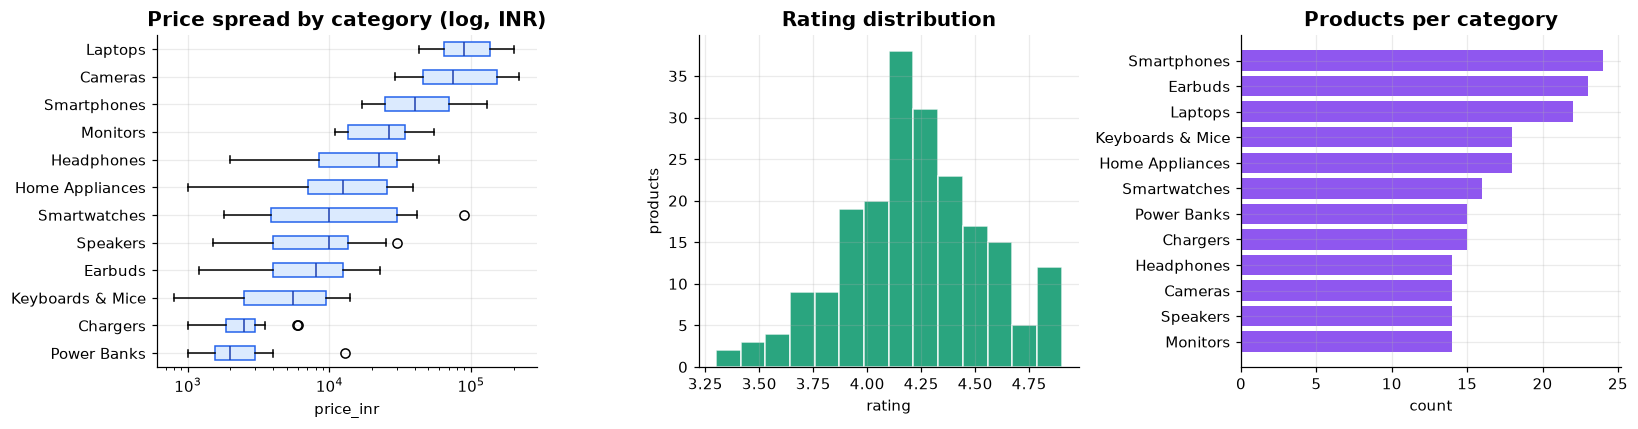

Price range (INR): 799 to 219990
Brands: 62 | Categories: 12


In [13]:
# ---------------------------------------------------------------------------
# 2.9  Quick EDA — understand the corpus before indexing it
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

order = products_df.groupby("category")["price_inr"].median().sort_values().index
data = [products_df.loc[products_df["category"] == c, "price_inr"].values for c in order]
axes[0].boxplot(data, vert=False, tick_labels=order, patch_artist=True,
                boxprops=dict(facecolor="#dbeafe", edgecolor="#2563eb"),
                medianprops=dict(color="#1e40af"))
axes[0].set_xscale("log")
axes[0].set_title("Price spread by category (log, INR)")
axes[0].set_xlabel("price_inr")

axes[1].hist(products_df["rating"], bins=14, color="#059669", alpha=0.85, edgecolor="white")
axes[1].set_title("Rating distribution")
axes[1].set_xlabel("rating")
axes[1].set_ylabel("products")

cat_counts = products_df["category"].value_counts()
axes[2].barh(cat_counts.index, cat_counts.values, color="#7c3aed", alpha=0.85)
axes[2].set_title("Products per category")
axes[2].set_xlabel("count")
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

print("Price range (INR):", int(products_df["price_inr"].min()), "to", int(products_df["price_inr"].max()))
print("Brands:", products_df["brand"].nunique(), "| Categories:", products_df["category"].nunique())

### Why this dataset is *hard* (and therefore useful)

| Trap | Where it lives | Which retriever suffers |
|---|---|---|
| Near-duplicate model names | `WH-1000XM4` / `XM5` / `XM6`, `iPhone 15` / `16` | **Dense** — the vectors are almost identical |
| Exact identifiers | `sku = SONY-WH1000XM5-BLK` | **Dense** — sub-word tokenisation destroys the ID |
| Numeric constraints | `65W`, `IP68`, `RTX 4060`, `under 70000` | **Dense** — numbers are weakly represented |
| Synonyms & intent | "block out noise on a flight" vs "noise cancellation" | **Sparse** — zero lexical overlap |
| Relational facts | "which charger works with this laptop" | **Sparse and dense** — the fact lives in an edge, not a sentence |
| Abstract prose | refund/EMI/installation policies | **Sparse** — vocabulary is formal and repetitive |

Keep this table in mind: every "failure demo" later is one of these rows.

---
# 3. From records to retrieval units

Retrieval does not operate on rows — it operates on **chunks**: the atomic text
units that are embedded, indexed, and later pasted into the context window.

### The three decisions that matter

1. **Granularity.** One chunk per product? Per *field*? Fixed 300-token windows?
   - *Too large* → the answer is buried in noise and similarity is diluted.
   - *Too small* → the chunk loses the context needed to interpret it.
2. **Overlap.** Sliding windows with 10–20% overlap prevent answers from being
   cut in half at a boundary.
3. **Metadata.** Every chunk carries structured fields (`product_id`, `brand`,
   `category`, `price_inr`, `warranty_months`). This is what enables *filtered*
   retrieval — "semantic similarity **and** price ≤ 70,000".

### Our strategy: field-aware ("record + facet") chunking

| Chunk type | Text | Why |
|---|---|---|
| `desc` | title + brand + category + description | narrative, great for semantic |
| `spec` | title + `key: value` spec lines | dense with numbers and IDs, great for sparse |
| `rev` | title + 2–3 review sentences | opinion and defect language |
| `policy` | title + full policy text | abstract procedural questions |

Total ≈ 3 chunks per product + 25 policy chunks.

In [14]:
# ---------------------------------------------------------------------------
# 3.1  Build the chunk corpus
# ---------------------------------------------------------------------------
def build_chunks(products: pd.DataFrame, reviews: pd.DataFrame, policies: pd.DataFrame) -> pd.DataFrame:
    rev_by_product = reviews.groupby("product_id")["review_text"].apply(list).to_dict()
    chunks = []

    for _, p in products.iterrows():
        meta = {
            "product_id": p["product_id"], "sku": p["sku"], "brand": p["brand"],
            "category": p["category"], "price_inr": int(p["price_inr"]),
            "rating": float(p["rating"]), "warranty_months": int(p["warranty_months"]),
            "stock_units": int(p["stock_units"]), "launch_year": int(p["launch_year"]),
        }
        chunks.append({
            "doc_id": f"{p['product_id']}:desc", "chunk_type": "desc",
            "text": f"{p['title']}. Brand: {p['brand']}. Category: {p['category']}. "
                    f"{p['description']} Price: Rs {p['price_inr']}. "
                    f"Warranty: {p['warranty_months']} months.",
            "metadata": meta,
        })
        chunks.append({
            "doc_id": f"{p['product_id']}:spec", "chunk_type": "spec",
            "text": f"{p['title']} ({p['sku']}). Specifications -> {render_specs(p['specs'])}. "
                    f"Price: Rs {p['price_inr']}. Warranty: {p['warranty_months']} months. "
                    f"Rating: {p['rating']} out of 5 from {p['rating_count']} buyers.",
            "metadata": meta,
        })
        revs = rev_by_product.get(p["product_id"], [])[:3]
        if revs:
            chunks.append({
                "doc_id": f"{p['product_id']}:rev", "chunk_type": "rev",
                "text": f"Customer reviews for {p['title']}: " + " ".join(revs),
                "metadata": meta,
            })

    for _, pol in policies.iterrows():
        chunks.append({
            "doc_id": f"{pol['policy_id']}:policy", "chunk_type": "policy",
            "text": f"{pol['title']} [{pol['topic']}]. {pol['text']}",
            "metadata": {"product_id": None, "policy_id": pol["policy_id"],
                         "category": "Policy", "brand": "Zephyr",
                         "price_inr": 0, "rating": 0.0, "warranty_months": 0,
                         "stock_units": 0, "launch_year": 2026, "sku": pol["policy_id"]},
        })

    return pd.DataFrame(chunks)


chunks_df = build_chunks(products_df, reviews_df, policies_df)
chunks_df["n_chars"] = chunks_df["text"].str.len()
chunks_df["n_words"] = chunks_df["text"].str.split().str.len()
# Promote the most useful metadata fields to columns for analysis and plots.
for field in ["category", "brand", "price_inr", "warranty_months"]:
    chunks_df[field] = chunks_df["metadata"].apply(lambda m: m.get(field))

print(f"chunks: {len(chunks_df)}  ({chunks_df['chunk_type'].value_counts().to_dict()})")
print(f"words per chunk: mean={chunks_df['n_words'].mean():.0f}  "
      f"median={chunks_df['n_words'].median():.0f}  max={chunks_df['n_words'].max()}")
show(chunks_df[["doc_id", "chunk_type", "n_words", "text"]], 4)

chunks: 646  ({'desc': 207, 'spec': 207, 'rev': 207, 'policy': 25})
words per chunk: mean=52  median=49  max=93


,doc_id,chunk_type,n_words,text
0,ZP0001:desc,desc,69,Sony WH-1000XM4 - a comfortable over-ear fit. Brand: Sony. Category: Headphones. Meet the S...
1,ZP0001:spec,spec,45,Sony WH-1000XM4 - a comfortable over-ear fit (SONY-WH1000XM4-BLK). Specifications -> Anc: Y...
2,ZP0001:rev,rev,40,Customer reviews for Sony WH-1000XM4 - a comfortable over-ear fit: Working flawlessly for d...
3,ZP0002:desc,desc,72,Sony WH-1000XM5 | a comfortable over-ear fit. Brand: Sony. Category: Headphones. If you wan...


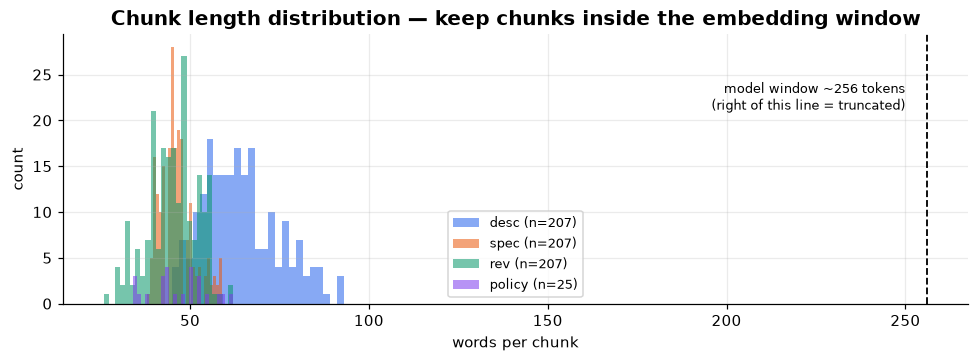

Chunks longer than 256 words (would be truncated): 0 (0.0%)


In [15]:
# ---------------------------------------------------------------------------
# 3.2  Chunk length distribution vs the model's context window
# ---------------------------------------------------------------------------
MAX_SEQ_LEN = 256  # all-MiniLM-L6-v2 truncates beyond this

fig, ax = plt.subplots(figsize=(9, 3.4))
for ctype, color in [("desc", PALETTE["semantic"]), ("spec", PALETTE["sparse"]),
                     ("rev", PALETTE["graph"]), ("policy", PALETTE["hybrid"])]:
    vals = chunks_df.loc[chunks_df["chunk_type"] == ctype, "n_words"]
    ax.hist(vals, bins=25, alpha=0.55, label=f"{ctype} (n={len(vals)})", color=color)
ax.axvline(MAX_SEQ_LEN, color="black", linestyle="--", linewidth=1.2)
ax.text(MAX_SEQ_LEN - 6, ax.get_ylim()[1] * 0.72,
        f"model window ~{MAX_SEQ_LEN} tokens\n(right of this line = truncated)",
        fontsize=8.5, ha="right")
ax.set_xlabel("words per chunk")
ax.set_ylabel("count")
ax.set_title("Chunk length distribution — keep chunks inside the embedding window")
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

truncated = int((chunks_df["n_words"] > MAX_SEQ_LEN).sum())
print(f"Chunks longer than {MAX_SEQ_LEN} words (would be truncated): {truncated} "
      f"({truncated / len(chunks_df):.1%})")

**Takeaway:** chunking is not a preprocessing detail, it is an *index design*
decision. Our field-aware chunks average ~55 words — comfortably inside the
256-token window, dense enough for BM25 to find `65W`, and coherent enough for
embeddings to represent meaning.

---
# 4. Semantic (dense) retrieval

### Definition
A **dense retriever** maps each chunk and each query into a fixed-length vector
in a shared geometric space, then ranks by vector similarity. Similarity of
*meaning* becomes proximity in space.

### The three ideas behind it

1. **Distributional hypothesis** (Firth, 1957): words that occur in similar
   contexts have similar meanings. A model trained on billions of sentence pairs
   learns a function that places "cheap" near "budget" and "affordable".
2. **Bi-encoder architecture.** Query and document are encoded **independently**
   by the same transformer into vectors `q` and `d`. This independence is what
   makes pre-computation possible: encode the corpus once, encode the query at
   request time, compare with a dot product.
3. **Contrastive training.** The model is trained so that a query is close to
   its true passage and far from random passages (in-batch negatives), typically
   with a scaled cross-entropy / InfoNCE loss over cosine similarities.

### The math we will use

$$\text{sim}(q, d) = \cos(\theta) = \frac{q \cdot d}{\lVert q \rVert \, \lVert d \rVert}$$

If we **L2-normalise** every vector at encode time, then
`cosine similarity == dot product`, and top-k search becomes a matrix–vector
multiply — fast enough to brute-force on small corpora, and approximated with
HNSW at scale.

### Why it works for humans
"something to block out engine noise on a flight" and "active noise cancelling
headphones" share almost no words, yet they mean the same thing to a shopper.
Dense retrieval encodes that equivalence.

### Why it breaks
Numbers and identifiers are tokenised into sub-words. `WH-1000XM4` and
`WH-1000XM5` become nearly the same vector — so "the XM4" retrieves the XM5.
We prove this at the end of the section.

In [16]:
# ---------------------------------------------------------------------------
# 4.1  Load the embedding model
# ---------------------------------------------------------------------------
from sentence_transformers import SentenceTransformer
import transformers.utils.logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

t0 = time.time()
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
print(f"Loaded all-MiniLM-L6-v2 in {time.time() - t0:.1f}s")
print(f"Embedding dimension : {embedder.get_sentence_embedding_dimension()}")
print(f"Max sequence length : {embedder.max_seq_length} tokens")
print(f"Parameters          : {sum(p.numel() for p in embedder.parameters()) / 1e6:.1f}M")


def embed_texts(texts, batch_size: int = 64, show_progress: bool = False):
    """Encode texts to L2-normalised float32 vectors."""
    return embedder.encode(
        list(texts), batch_size=batch_size, convert_to_numpy=True,
        normalize_embeddings=True, show_progress_bar=show_progress,
    ).astype(np.float32)


def cosine_scores(query_vec, matrix):
    """Cosine similarity for already L2-normalised vectors."""
    return matrix @ query_vec

Loaded all-MiniLM-L6-v2 in 1.2s
Embedding dimension : 384
Max sequence length : 256 tokens
Parameters          : 22.7M


In [17]:
# ---------------------------------------------------------------------------
# 4.2  What a vector actually looks like
# ---------------------------------------------------------------------------
demo_sentences = [
    "wireless earbuds with active noise cancellation",
    "headphones that block out engine noise on a plane",
    "a 65W USB-C charger for my laptop",
    "fast charger with USB-C output",
    "return policy for opened earbuds",
]
demo_vecs = embed_texts(demo_sentences)

print(f"Matrix shape: {demo_vecs.shape}  (5 sentences x 384 dimensions)\n")
for sent, vec in zip(demo_sentences, demo_vecs):
    head = ", ".join(f"{v:+.3f}" for v in vec[:8])
    print(f"  norm={np.linalg.norm(vec):.3f}  first 8 dims: [{head} ...]  {sent[:52]}")

Matrix shape: (5, 384)  (5 sentences x 384 dimensions)

  norm=1.000  first 8 dims: [-0.040, +0.026, -0.030, +0.053, -0.043, -0.067, +0.119, -0.081 ...]  wireless earbuds with active noise cancellation
  norm=1.000  first 8 dims: [-0.020, +0.051, -0.002, -0.015, -0.005, +0.001, +0.089, -0.093 ...]  headphones that block out engine noise on a plane
  norm=1.000  first 8 dims: [-0.069, +0.154, -0.053, +0.089, +0.064, +0.010, -0.109, -0.019 ...]  a 65W USB-C charger for my laptop
  norm=1.000  first 8 dims: [-0.079, +0.080, -0.074, +0.069, +0.043, -0.011, -0.072, -0.011 ...]  fast charger with USB-C output
  norm=1.000  first 8 dims: [+0.006, +0.000, +0.045, -0.026, -0.034, -0.002, +0.025, -0.033 ...]  return policy for opened earbuds


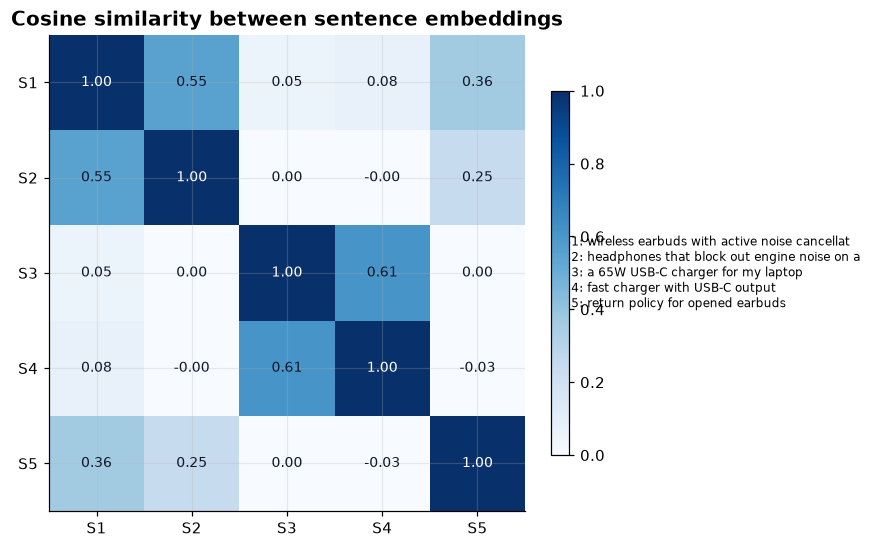

S1 vs S2 (different words, same meaning) : 0.553
S3 vs S4 (different words, same meaning) : 0.607
S1 vs S5 (different topics)              : 0.361


In [18]:
# ---------------------------------------------------------------------------
# 4.3  Similarity is geometry — visualise the full 5x5 cosine matrix
# ---------------------------------------------------------------------------
sim = demo_vecs @ demo_vecs.T

fig, ax = plt.subplots(figsize=(7.6, 5.4))
im = ax.imshow(sim, cmap="Blues", vmin=0.0, vmax=1.0)
labels = [f"S{i + 1}" for i in range(len(demo_sentences))]
ax.set_xticks(range(len(labels)), labels)
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center",
                fontsize=9, color="white" if sim[i, j] > 0.62 else "#0f172a")
ax.set_title("Cosine similarity between sentence embeddings")
legend = "\n".join(f"S{i + 1}: {s[:44]}" for i, s in enumerate(demo_sentences))
ax.text(1.08, 0.5, legend, transform=ax.transAxes, fontsize=8, va="center")
plt.colorbar(im, fraction=0.035)
plt.tight_layout()
plt.show()

print("S1 vs S2 (different words, same meaning) :", f"{sim[0, 1]:.3f}")
print("S3 vs S4 (different words, same meaning) :", f"{sim[2, 3]:.3f}")
print("S1 vs S5 (different topics)              :", f"{sim[0, 4]:.3f}")

Notice the pattern: **meaning, not vocabulary**. S1/S2 share almost no words and
score high; S1/S5 share the words *earbuds* and *noise* yet score low. That is
the entire value proposition of dense retrieval — and, as we will see, its
weakness when the distinguishing signal *is* a word (a model number, a wattage).

In [19]:
# ---------------------------------------------------------------------------
# 4.4  Encode the corpus once, and cache it (so live re-runs are instant)
# ---------------------------------------------------------------------------
EMB_PATH = DATA_DIR / "chunk_embeddings.npy"
HASH_PATH = DATA_DIR / "chunk_embeddings.sha1"

corpus_texts = chunks_df["text"].tolist()
corpus_hash = hashlib.sha1("\n".join(corpus_texts).encode("utf-8")).hexdigest()

if EMB_PATH.exists() and HASH_PATH.exists() and HASH_PATH.read_text().strip() == corpus_hash:
    chunk_vecs = np.load(EMB_PATH)
    print(f"Loaded cached embeddings {chunk_vecs.shape} from {EMB_PATH.name}")
else:
    t0 = time.time()
    chunk_vecs = embed_texts(corpus_texts, show_progress=True)
    np.save(EMB_PATH, chunk_vecs)
    HASH_PATH.write_text(corpus_hash)
    print(f"Encoded {len(corpus_texts)} chunks in {time.time() - t0:.1f}s -> cached")

print(f"Matrix: {chunk_vecs.shape}  |  dtype: {chunk_vecs.dtype}  |  "
      f"norms all ~1: {np.allclose(np.linalg.norm(chunk_vecs, axis=1), 1.0, atol=1e-4)}")
print(f"Memory footprint: {chunk_vecs.nbytes / 1e6:.2f} MB (raw float32, before any index)")

Loaded cached embeddings (646, 384) from chunk_embeddings.npy
Matrix: (646, 384)  |  dtype: float32  |  norms all ~1: True
Memory footprint: 0.99 MB (raw float32, before any index)


In [20]:
# ---------------------------------------------------------------------------
# 4.5  The semantic retriever
# ---------------------------------------------------------------------------
def metadata_array(field: str) -> np.ndarray:
    return chunks_df["metadata"].apply(lambda m: m.get(field)).to_numpy()


def semantic_search(query: str, k: int = 5, chunk_type: str | None = None,
                    category: str | None = None,
                    min_price=None, max_price=None, min_warranty=None) -> pd.DataFrame:
    """Dense retrieval with optional metadata pre-filtering."""
    qv = embed_texts([query])[0]
    scores = cosine_scores(qv, chunk_vecs)

    mask = np.ones(len(chunks_df), dtype=bool)
    if chunk_type:
        mask &= (chunks_df["chunk_type"] == chunk_type).to_numpy()
    if category:
        mask &= (chunks_df["category"] == category).to_numpy()
    if max_price is not None:
        mask &= (metadata_array("price_inr") <= max_price)
    if min_price is not None:
        mask &= (metadata_array("price_inr") >= min_price)
    if min_warranty is not None:
        mask &= (metadata_array("warranty_months") >= min_warranty)

    scores = np.where(mask, scores, -np.inf)
    top = np.argsort(-scores)[:k]

    out = chunks_df.iloc[top][["doc_id", "chunk_type", "text"]].copy()
    out.insert(1, "score", np.round(scores[top], 4))
    out["product_id"] = out["doc_id"].str.split(":").str[0]
    title_map = products_df.set_index("product_id")["title"]
    out["title"] = out["product_id"].map(title_map).fillna("(policy document)")
    return out[["doc_id", "product_id", "chunk_type", "score", "title", "text"]]


def show_results(df: pd.DataFrame, width: int = 88):
    view = df.copy()
    view["text"] = view["text"].str.slice(0, width) + "..."
    show(view, len(view))

In [21]:
# ---------------------------------------------------------------------------
# 4.6  Demo A — a query with ZERO lexical overlap
# ---------------------------------------------------------------------------
section("Semantic demo 1", "Vague, human intent — no keyword overlap with the catalogue")
query = "I take long flights and the engine drone gives me a headache. What should I buy?"
print(f"Query: {query}\n")
fuzzy = semantic_search(query, k=5)
show_results(fuzzy)

anc_ids = set(products_df.loc[products_df["specs"].apply(lambda s: s.get("anc") is True), "product_id"])
hits = [p for p in fuzzy["product_id"].tolist() if p in anc_ids]
print(f"\n{hits and len(hits) or 0} of the top-5 have active noise cancellation: {hits}")
print("The words 'noise cancelling' never appear in the query - 'engine drone' and")
print("'headache' were enough. That is dense retrieval doing its job.")


SEMANTIC DEMO 1
Vague, human intent — no keyword overlap with the catalogue
Query: I take long flights and the engine drone gives me a headache. What should I buy?



,doc_id,product_id,chunk_type,score,title,text
15,ZP0006:desc,ZP0006,desc,0.3952,Sennheiser Momentum 4 - deep bass tuning,Sennheiser Momentum 4 - deep bass tuning. Brand: Sennheiser. Category: Headphones. If yo...
66,ZP0023:desc,ZP0023,desc,0.3672,boAt Airdopes 311 Pro - a compact charging case,boAt Airdopes 311 Pro - a compact charging case. Brand: boAt. Category: Earbuds. Meet th...
69,ZP0024:desc,ZP0024,desc,0.3666,boAt Airdopes 800 | with Fast Charge,boAt Airdopes 800 | with Fast Charge. Brand: boAt. Category: Earbuds. If you want IPX5 s...
30,ZP0011:desc,ZP0011,desc,0.3646,Noise Halo 2 | with Fast Charge,Noise Halo 2 | with Fast Charge. Brand: Noise. Category: Headphones. Noise Halo 2 is bui...
68,ZP0023:rev,ZP0023,rev,0.3548,boAt Airdopes 311 Pro - a compact charging case,Customer reviews for boAt Airdopes 311 Pro - a compact charging case: Battery drains fas...



5 of the top-5 have active noise cancellation: ['ZP0006', 'ZP0023', 'ZP0024', 'ZP0011', 'ZP0023']
The words 'noise cancelling' never appear in the query - 'engine drone' and
'headache' were enough. That is dense retrieval doing its job.


In [22]:
# ---------------------------------------------------------------------------
# 4.7  Demo B — intent + budget, and the numeric blind spot
# ---------------------------------------------------------------------------
section("Semantic demo 2", "A budget constraint the embedding cannot enforce")
query = "laptop for editing 4K video under 70000 rupees"
print(f"Query: {query}\n")
unfiltered = semantic_search(query, k=5)
show_results(unfiltered)

top_price = int(products_df.set_index("product_id").loc[unfiltered["product_id"].iloc[0], "price_inr"])
print(f"\nTop-1 price: Rs {top_price:,}  ->  over budget: {top_price > 70000}")


SEMANTIC DEMO 2
A budget constraint the embedding cannot enforce
Query: laptop for editing 4K video under 70000 rupees



,doc_id,product_id,chunk_type,score,title,text
234,ZP0079:desc,ZP0079,desc,0.4866,Acer Nitro V 15 - a colour-accurate panel (2026 Edition),Acer Nitro V 15 - a colour-accurate panel (2026 Edition). Brand: Acer. Category: Laptops...
216,ZP0073:desc,ZP0073,desc,0.4551,Lenovo LOQ 15 with fast SSD storage,Lenovo LOQ 15 with fast SSD storage. Brand: Lenovo. Category: Laptops. Lenovo LOQ 15 is ...
211,ZP0071:spec,ZP0071,spec,0.4512,Lenovo IdeaPad Slim 5,Lenovo IdeaPad Slim 5 (LEN-IDEAPADSLIM5-5G-WHT). Specifications -> Ram Gb: 16 | Storage ...
219,ZP0074:desc,ZP0074,desc,0.4457,Asus ROG STRIX G16 | a colour-accurate panel - Latest Model,Asus ROG STRIX G16 | a colour-accurate panel - Latest Model. Brand: Asus. Category: Lapt...
213,ZP0072:desc,ZP0072,desc,0.4444,Lenovo legion 5 pro - a thin-and-light design,Lenovo legion 5 pro - a thin-and-light design. Brand: Lenovo. Category: Laptops. Lenovo ...



Top-1 price: Rs 69,990  ->  over budget: False


In [23]:
# ---------------------------------------------------------------------------
# 4.8  Demo C — metadata filtering fixes the numeric constraint
# ---------------------------------------------------------------------------
section("Semantic demo 3", "Same query + structured pre-filters (price AND category)")
filtered = semantic_search(query, k=5, chunk_type="desc", category="Laptops", max_price=70000)
show_results(filtered)

prices = products_df.set_index("product_id").loc[filtered["product_id"].unique(), "price_inr"]
cats = products_df.set_index("product_id").loc[filtered["product_id"].unique(), "category"]
print(f"\nAll returned products <= Rs 70,000: {bool((prices <= 70000).all())}  "
      f"(prices: {sorted(int(p) for p in prices.tolist())})")
print(f"All returned products are laptops  : {bool((cats == 'Laptops').all())}")

print("\nNote: filtering on price alone is not enough - a 12,999 power bank would")
print("also pass. Every hard constraint in the query needs its own filter.")


SEMANTIC DEMO 3
Same query + structured pre-filters (price AND category)


,doc_id,product_id,chunk_type,score,title,text
234,ZP0079:desc,ZP0079,desc,0.4866,Acer Nitro V 15 - a colour-accurate panel (2026 Edition),Acer Nitro V 15 - a colour-accurate panel (2026 Edition). Brand: Acer. Category: Laptops...
246,ZP0083:desc,ZP0083,desc,0.4163,Xiaomi RedmiBook Pro 15 - all-day battery life (2026 Edition),Xiaomi RedmiBook Pro 15 - all-day battery life (2026 Edition). Brand: Xiaomi. Category: ...
192,ZP0065:desc,ZP0065,desc,0.3970,Dell Inspiron 14 5430 - all-day battery life,Dell Inspiron 14 5430 - all-day battery life. Brand: Dell. Category: Laptops. For work a...
222,ZP0075:desc,ZP0075,desc,0.3957,Asus VivoBook 15 with a thin-and-light design - Latest Model,Asus VivoBook 15 with a thin-and-light design - Latest Model. Brand: Asus. Category: Lap...
198,ZP0067:desc,ZP0067,desc,0.3924,HP PAVILION 15 - a colour-accurate panel | with Fast Charge,HP PAVILION 15 - a colour-accurate panel | with Fast Charge. Brand: HP. Category: Laptop...



All returned products <= Rs 70,000: True  (prices: [46990, 54990, 59990, 62990, 69990])
All returned products are laptops  : True

Note: filtering on price alone is not enough - a 12,999 power bank would
also pass. Every hard constraint in the query needs its own filter.


**First big lesson.** The embedding is excellent at *meaning* and blind to
*arithmetic*. Numbers, ranges and equality constraints belong in **metadata
filters**, not in the vector. Every mature vector database exposes exactly this:
`query(vector, where={...})`.

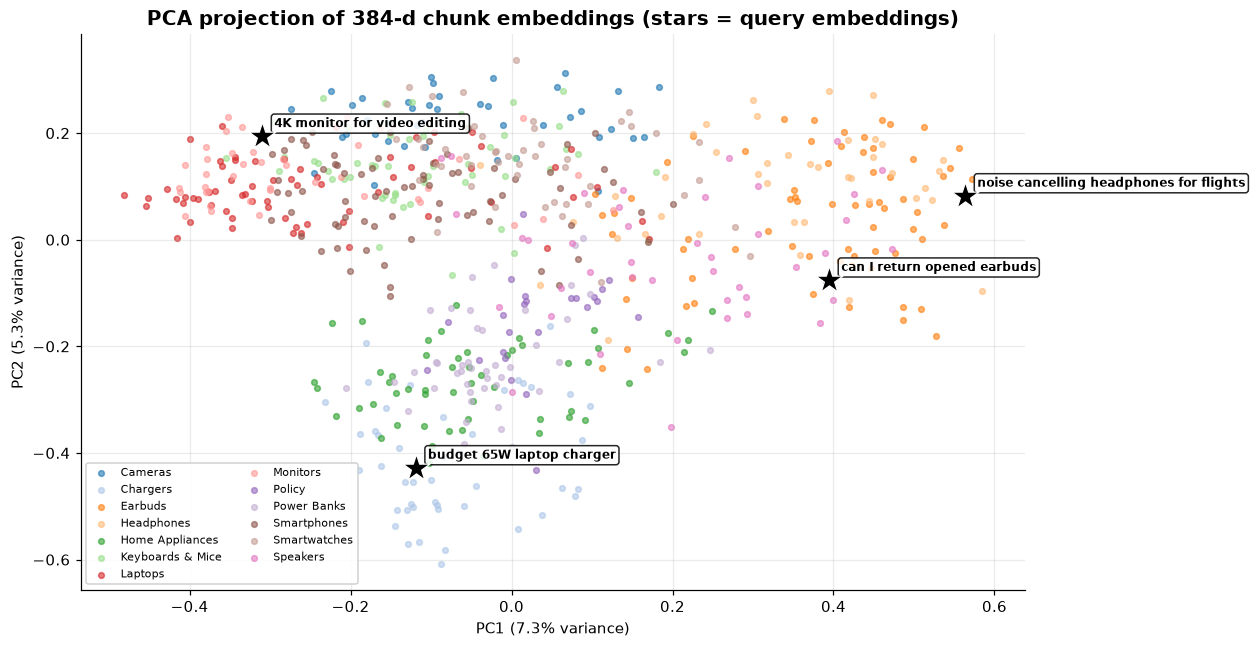

2 components explain 12.7% of variance — clusters are meaningful, exact distances are not.


In [24]:
# ---------------------------------------------------------------------------
# 4.9  The embedding space, projected to 2-D with PCA
# ---------------------------------------------------------------------------
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(chunk_vecs)
chunks_plot = chunks_df.assign(x=coords[:, 0], y=coords[:, 1])

query_points = [
    "noise cancelling headphones for flights",
    "budget 65W laptop charger",
    "4K monitor for video editing",
    "can I return opened earbuds",
]
q_coords = pca.transform(embed_texts(query_points))

fig, ax = plt.subplots(figsize=(11.5, 6))
cmap = plt.get_cmap("tab20")
for i, (cat, g) in enumerate(chunks_plot.groupby("category")):
    ax.scatter(g["x"], g["y"], s=14, alpha=0.6, color=cmap(i % 20), label=cat)
for (qx, qy), label in zip(q_coords, query_points):
    ax.scatter(qx, qy, marker="*", s=340, color="black", edgecolor="white",
               linewidth=0.8, zorder=5)
    ax.annotate(label, (qx, qy), textcoords="offset points", xytext=(8, 6),
                fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="black", alpha=0.85))
ax.set_title("PCA projection of 384-d chunk embeddings (stars = query embeddings)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.legend(fontsize=7, ncol=2, loc="best", framealpha=0.9)
plt.tight_layout()
plt.show()

print(f"2 components explain {pca.explained_variance_ratio_.sum():.1%} of variance — "
      "clusters are meaningful, exact distances are not.")

In [25]:
# ---------------------------------------------------------------------------
# 4.10  ChromaDB — a real vector store, with persistence and filters
# ---------------------------------------------------------------------------
import chromadb
from chromadb.config import Settings

CHROMA_DIR = BASE_DIR / "chroma_store"
client = chromadb.PersistentClient(path=str(CHROMA_DIR),
                                   settings=Settings(anonymized_telemetry=False))

# Idempotent: always start from a clean collection so re-runs are identical.
try:
    client.delete_collection("zephyr_catalog")
except Exception:
    pass


class MiniLMEmbeddingFunction:
    """Chroma's embedding-function interface (documents + queries)."""

    def __call__(self, input):
        return embed_texts(input).tolist()

    def embed_documents(self, input):
        return self.__call__(input)

    def embed_query(self, input):
        return self.__call__(input)

    def name(self):
        return "minilm-l6-v2-local"


collection = client.create_collection(
    name="zephyr_catalog",
    embedding_function=MiniLMEmbeddingFunction(),
    metadata={"hnsw:space": "cosine"},
)

BATCH = 128
for start in range(0, len(chunks_df), BATCH):
    part = chunks_df.iloc[start:start + BATCH]
    collection.add(
        ids=part["doc_id"].tolist(),
        documents=part["text"].tolist(),
        metadatas=[{k: v for k, v in m.items() if v is not None} for m in part["metadata"]],
    )

print(f"Chroma collection '{collection.name}' holds {collection.count()} chunks")
print(f"Persisted at: {CHROMA_DIR}")

Chroma collection 'zephyr_catalog' holds 646 chunks
Persisted at: D:\Seminar_RAG_10Nov2026\chroma_store


In [26]:
# ---------------------------------------------------------------------------
# 4.11  Querying Chroma with a metadata filter
# ---------------------------------------------------------------------------
def chroma_search(query: str, k: int = 5, where: dict | None = None) -> pd.DataFrame:
    res = collection.query(query_texts=[query], n_results=k, where=where,
                           include=["documents", "metadatas", "distances"])
    rows = []
    for doc, meta, dist in zip(res["documents"][0], res["metadatas"][0], res["distances"][0]):
        rows.append({
            "doc_id": meta.get("sku", "?"),
            "chunk": doc[:74] + "...",
            "cosine_sim": round(1 - dist, 4),
            "brand": meta.get("brand"),
            "category": meta.get("category"),
            "price_inr": meta.get("price_inr"),
        })
    return pd.DataFrame(rows)


section("ChromaDB demo", "Semantic search + structured filter, executed by the vector store")
where = {"$and": [{"category": "Laptops"}, {"price_inr": {"$lte": 70000}}]}
res = chroma_search("machine for editing 4K video on the go", k=5, where=where)
show(res, 10)
print("\nNote: Chroma returns DISTANCE (1 - cosine_sim in cosine space); we convert back.")


CHROMADB DEMO
Semantic search + structured filter, executed by the vector store


,doc_id,chunk,cosine_sim,brand,category,price_inr
0,ACER-NITROV15-5G-SLV,Acer Nitro V 15 - a colour-accurate panel (2026 Edition). Brand: Acer. Cat...,0.3313,Acer,Laptops,69990
1,ACER-NITROV15-5G-SLV,Acer Nitro V 15 - a colour-accurate panel (2026 Edition) (ACER-NITROV15-5G...,0.2986,Acer,Laptops,69990
2,LEN-IDEAPADSLIM5-5G-WHT,Lenovo IdeaPad Slim 5 (LEN-IDEAPADSLIM5-5G-WHT). Specifications -> Ram Gb:...,0.2678,Lenovo,Laptops,57990
3,LEN-IDEAPADSLIM5-5G-WHT,Lenovo IdeaPad Slim 5. Brand: Lenovo. Category: Laptops. For work and play...,0.2251,Lenovo,Laptops,57990
4,ACER-NITROV15-5G-SLV,Customer reviews for Acer Nitro V 15 - a colour-accurate panel (2026 Editi...,0.2247,Acer,Laptops,69990



Note: Chroma returns DISTANCE (1 - cosine_sim in cosine space); we convert back.


### Why an index at all? HNSW in one paragraph

Brute force costs one dot product per chunk — fine for our ~700 chunks, hopeless
for 100 million. **HNSW** (Hierarchical Navigable Small World) builds a
multi-layer proximity graph. Search enters at the top layer (long jumps), greedily
descends to denser layers, and returns an approximate top-k in `O(log N)` hops.

| Parameter | Meaning | Effect |
|---|---|---|
| `M` | max edges per node per layer | higher = better recall, more memory |
| `ef_construction` | candidate list while building | higher = better graph, slower build |
| `ef_search` | candidate list while querying | higher = better recall, slower query |

The trade-off is **recall vs latency vs memory** — never "exact vs approximate"
in the abstract. Production systems tune `ef_search` per SLA.

In [27]:
# ---------------------------------------------------------------------------
# 4.12  The semantic failure mode: numeric specs and near-duplicate model names
# ---------------------------------------------------------------------------
section("Semantic FAILURE demo",
        "The distinguishing signal is a NUMBER — and numbers get blurred")
sku_query = "RTX 4060 laptop"
res = semantic_search(sku_query, k=6, chunk_type="desc")
show_results(res, 70)

rtx_4060 = products_df[products_df["specs"].apply(lambda s: "RTX 4060" in str(s.get("gpu", "")))]
correct_rtx = rtx_4060["product_id"].tolist()
print("\nProducts that actually have an RTX 4060 GPU:")
show(rtx_4060[["product_id", "title", "price_inr"]], 5)

top1 = res["product_id"].iloc[0]
top1_row = products_df.set_index("product_id").loc[top1]
gpu = top1_row["specs"].get("gpu", "-")
print(f"\nDense top-1 : {top1} | {top1_row['category']:<18} | GPU: {gpu}")
print(f"Correct set : {correct_rtx}")
print(f"Verdict     : {'CORRECT' if top1 in correct_rtx else 'WRONG PRODUCT'}")

print("\nSame effect with a standards token:")
res_ip = semantic_search("IP68 earbuds", k=3, chunk_type="desc")
show_results(res_ip, 66)
ip68_ids = products_df.loc[
    (products_df["category"] == "Earbuds")
    & (products_df["specs"].apply(lambda s: s.get("ip_rating") == "IP68")), "product_id"].tolist()
print(f"Products actually rated IP68: {ip68_ids}")
print(f"Dense top-1: {res_ip['product_id'].iloc[0]} -> "
      f"{'CORRECT' if res_ip['product_id'].iloc[0] in ip68_ids else 'WRONG'}")


SEMANTIC FAILURE DEMO
The distinguishing signal is a NUMBER — and numbers get blurred


,doc_id,product_id,chunk_type,score,title,text
219,ZP0074:desc,ZP0074,desc,0.4631,Asus ROG STRIX G16 | a colour-accurate panel - Latest Model,Asus ROG STRIX G16 | a colour-accurate panel - Latest Model. Brand: As...
510,ZP0171:desc,ZP0171,desc,0.4555,ViewSonic vx2428 | a 165 Hz refresh rate - Latest Model,ViewSonic vx2428 | a 165 Hz refresh rate - Latest Model. Brand: ViewSo...
189,ZP0064:desc,ZP0064,desc,0.4233,Dell xps 15 9530,"Dell xps 15 9530. Brand: Dell. Category: Laptops. For work and play, t..."
201,ZP0068:desc,ZP0068,desc,0.4198,HP Envy x360 (2026 Edition),HP Envy x360 (2026 Edition). Brand: HP. Category: Laptops. The HP Envy...
504,ZP0169:desc,ZP0169,desc,0.4149,HP X27Q - 99% sRGB coverage | with Fast Charge,HP X27Q - 99% sRGB coverage | with Fast Charge. Brand: HP. Category: M...
228,ZP0077:desc,ZP0077,desc,0.4142,Asus TUF A15 (2026 Edition),Asus TUF A15 (2026 Edition). Brand: Asus. Category: Laptops. The Asus ...



Products that actually have an RTX 4060 GPU:


,product_id,title,price_inr
68,ZP0069,HP Omen 16 - a colour-accurate panel,129990
71,ZP0072,Lenovo legion 5 pro - a thin-and-light design,139990
79,ZP0080,MSI KATANA 15 - a thin-and-light design - Latest Model,89990



Dense top-1 : ZP0074 | Laptops            | GPU: NVIDIA RTX 4070
Correct set : ['ZP0069', 'ZP0072', 'ZP0080']
Verdict     : WRONG PRODUCT

Same effect with a standards token:


,doc_id,product_id,chunk_type,score,title,text
69,ZP0024:desc,ZP0024,desc,0.5440,boAt Airdopes 800 | with Fast Charge,boAt Airdopes 800 | with Fast Charge. Brand: boAt. Category: Earbu...
75,ZP0026:desc,ZP0026,desc,0.5349,Noise Buds Xero | fast charging | with Fast Charge,Noise Buds Xero | fast charging | with Fast Charge. Brand: Noise. ...
84,ZP0029:desc,ZP0029,desc,0.5292,JBL Tune Buds - Latest Model,JBL Tune Buds - Latest Model. Brand: JBL. Category: Earbuds. If yo...


Products actually rated IP68: ['ZP0023', 'ZP0026']
Dense top-1: ZP0024 -> WRONG


Dense retrieval gets the *category* right — it returns laptops — but it cannot
reliably separate `RTX 4050` from `RTX 4060` from `RTX 4070`, because those are
sub-word tokens whose embeddings are almost identical. The same happens with
`XM4` / `XM5` / `XM6`, and with `IPX5` vs `IP68`.

The one signal that would disambiguate is the literal token. That is exactly
what the model compresses away — and exactly what BM25 preserves.

Hold that thought. We now build the retriever that gets this right.

---
# 5. Sparse (lexical) retrieval — BM25

### Definition
A **sparse retriever** represents text as a high-dimensional vector over the
*vocabulary*: one dimension per term, non-zero only for terms present. Ranking
is driven by exact term matches, weighted by how informative each term is.

### From TF-IDF to BM25

**TF-IDF** scores a document as
$\sum_{t \in q} \text{tf}(t,d) \cdot \log\frac{N}{\text{df}(t)}$.
Two flaws: raw term frequency grows without bound, and long documents accumulate
score simply by being long.

**BM25** (Robertson & Zaragoza, 2009) fixes both:

$$\text{score}(q, d) = \sum_{t \in q} \text{IDF}(t) \cdot
  \frac{f(t,d)\,(k_1 + 1)}{f(t,d) + k_1\left(1 - b + b\,\frac{|d|}{\text{avgdl}}\right)}$$

$$\text{IDF}(t) = \ln\!\left(1 + \frac{N - n(t) + 0.5}{n(t) + 0.5}\right)$$

| Symbol | Meaning | Typical |
|---|---|---|
| `f(t,d)` | term frequency of `t` in `d` | — |
| `\|d\|` | document length | — |
| `avgdl` | average document length | — |
| `k1` | term-frequency saturation | 1.2 – 2.0 |
| `b` | length-normalisation strength | 0.75 |
| `n(t)` | number of docs containing `t` | — |

**Reading the formula:** the numerator saturates (a term appearing 50 times is
not 50× more relevant than once), and the denominator penalises long documents.
`k1` controls saturation speed; `b = 0` disables length normalisation, `b = 1`
applies it fully.

### Worked example
Suppose `N = 700`, `avgdl = 55`, `k1 = 1.5`, `b = 0.75`. A query term appears in
`n = 7` documents, and in our document `f = 2` with `|d| = 50`:

- `IDF = ln(1 + (700 - 7 + 0.5) / (7 + 0.5)) = ln(93.4) ≈ 4.54`
- length factor `= 1 - 0.75 + 0.75 × 50/55 ≈ 0.932`
- `score = 4.54 × (2 × 2.5) / (2 + 1.5 × 0.932) ≈ 4.54 × 0.742 ≈ 3.37`

### Why sparse is still a serious baseline
Rare terms carry enormous IDF. A product code like `WH1000XM5` appears in a
handful of documents: `IDF` is large and the match is *exact*. No embedding can
beat a lookup table at lookup.

### Blind spots
No synonymy ("cheap" ≠ "budget"), no word order, no negation handling, and
out-of-vocabulary terms are invisible.

In [28]:
# ---------------------------------------------------------------------------
# 5.1  Tokenisation — the single most important choice in sparse retrieval
# ---------------------------------------------------------------------------
STOPWORDS = set("""a an and are as at be been but by for from had has have he her his i if in
into is it its me my not of on or our out she that the their them then there these they this
those to us was we were what when where which who will with you your""".split())


def tokenize(text: str) -> list[str]:
    """
    Lowercase, keep alphanumerics, and preserve model numbers.

    'WH-1000XM5' -> ['wh-1000xm5', 'wh1000xm5']
    Emitting both the hyphenated and collapsed form means a user typing
    'WH1000XM5' or 'wh 1000xm5' still matches the catalogue.
    """
    text = text.lower()
    raw_tokens = re.findall(r"[a-z0-9]+(?:[-./][a-z0-9]+)*", text)
    tokens = []
    for tok in raw_tokens:
        if tok in STOPWORDS:
            continue
        tokens.append(tok)
        if any(ch.isdigit() for ch in tok) and re.search(r"[-./]", tok):
            tokens.append(re.sub(r"[-./]", "", tok))
    return [t for t in tokens if len(t) > 1]


def light_stem(token: str) -> str:
    """Conservative suffix stripping (production would use Porter/Snowball)."""
    if len(token) <= 3:
        return token
    if token.endswith("ies") and len(token) > 4:
        return token[:-3] + "y"
    if token.endswith("ss"):
        return token
    if token.endswith("s"):
        return token[:-1]
    return token


def preprocess(text: str) -> list[str]:
    return [light_stem(t) for t in tokenize(text)]


for s in ["Sony WH-1000XM5 Bluetooth Headphones", "65W USB-C chargers", "earbuds with IP68 rating"]:
    print(f"{s!r}\n  -> {preprocess(s)}")

'Sony WH-1000XM5 Bluetooth Headphones'
  -> ['sony', 'wh-1000xm5', 'wh1000xm5', 'bluetooth', 'headphone']
'65W USB-C chargers'
  -> ['65w', 'usb-c', 'charger']
'earbuds with IP68 rating'
  -> ['earbud', 'ip68', 'rating']


In [29]:
# ---------------------------------------------------------------------------
# 5.2  BM25 from scratch (about 40 lines, no magic)
# ---------------------------------------------------------------------------
class BM25Index:
    def __init__(self, texts: list[str], k1: float = 1.5, b: float = 0.75):
        self.k1, self.b = k1, b
        self.doc_tokens = [preprocess(t) for t in texts]
        self.doc_len = np.array([len(t) for t in self.doc_tokens], dtype=np.float32)
        self.avgdl = float(self.doc_len.mean())
        self.N = len(texts)

        self.tf = []
        df_counter = Counter()
        for tokens in self.doc_tokens:
            counts = Counter(tokens)
            self.tf.append(counts)
            df_counter.update(counts.keys())
        self.df = df_counter
        self.idf = {
            term: math.log(1 + (self.N - n + 0.5) / (n + 0.5))
            for term, n in df_counter.items()
        }
        self.vocab = set(df_counter)

    def term_scores(self, query: str) -> dict:
        """Per-term contributions (used for explainability)."""
        q_terms = preprocess(query)
        scores = np.zeros(self.N, dtype=np.float32)
        contrib = defaultdict(lambda: np.zeros(self.N, dtype=np.float32))
        for term in q_terms:
            if term not in self.vocab:
                continue
            idf = self.idf[term]
            for i in range(self.N):
                f = self.tf[i].get(term, 0)
                if not f:
                    continue
                denom = f + self.k1 * (1 - self.b + self.b * self.doc_len[i] / self.avgdl)
                val = idf * (f * (self.k1 + 1)) / denom
                scores[i] += val
                contrib[term][i] += val
        return {"scores": scores, "terms": dict(contrib), "query_terms": q_terms}

    def search(self, query: str, k: int = 5):
        out = self.term_scores(query)
        scores = out["scores"]
        top = np.argsort(-scores)[:k]
        return top, scores[top], out

    def explain(self, query: str, doc_index: int) -> pd.DataFrame:
        out = self.term_scores(query)
        rows = [{"term": t, "idf": round(self.idf[t], 3),
                 "tf_in_doc": self.tf[doc_index].get(t, 0),
                 "contribution": round(float(v[doc_index]), 3)}
                for t, v in out["terms"].items()]
        return pd.DataFrame(rows).sort_values("contribution", ascending=False)


bm25 = BM25Index(chunks_df["text"].tolist())
print(f"Indexed {bm25.N} chunks | vocabulary {len(bm25.vocab):,} terms | "
      f"avgdl {bm25.avgdl:.1f} tokens")
print("Most common terms:", ", ".join(t for t, _ in bm25.df.most_common(12)))

Indexed 646 chunks | vocabulary 2,028 terms | avgdl 39.4 tokens


Most common terms: month, price, warranty, rs, battery, buyer, colour, rating, connectivity, customer, brand, category


In [30]:
# ---------------------------------------------------------------------------
# 5.3  The sparse retriever wrapper
# ---------------------------------------------------------------------------
def bm25_search(query: str, k: int = 5, chunk_type: str | None = None) -> pd.DataFrame:
    top, scores, _ = bm25.search(query, k=200)
    rows = []
    for idx, score in zip(top, scores):
        if score <= 0:
            continue
        row = chunks_df.iloc[int(idx)]
        if chunk_type and row["chunk_type"] != chunk_type:
            continue
        rows.append({
            "doc_id": row["doc_id"],
            "product_id": row["doc_id"].split(":")[0],
            "chunk_type": row["chunk_type"],
            "score": round(float(score), 3),
            "sku_or_policy": row["metadata"].get("sku", "-"),
            "text": row["text"],
        })
        if len(rows) >= k:
            break
    return pd.DataFrame(rows, columns=["doc_id", "product_id", "chunk_type", "score",
                                       "sku_or_policy", "text"])


def show_bm25(df: pd.DataFrame, width: int = 88, n: int | None = None):
    view = df.copy()
    view["text"] = view["text"].str.slice(0, width) + "..."
    show(view, len(view) if n is None else n)

In [31]:
# ---------------------------------------------------------------------------
# 5.4  Demo — the exact query that just broke dense retrieval
# ---------------------------------------------------------------------------
section("Sparse demo 1", "Same query as section 4.12 — sparse gets it exactly right")
q = "RTX 4060 laptop"
print(f"Query: {q}\n")
res_sparse = bm25_search(q, k=4, chunk_type="spec")
show_bm25(res_sparse, 74)

dense_top1 = semantic_search(q, k=1, chunk_type="desc")["product_id"].iloc[0]
sparse_ids = res_sparse["product_id"].tolist()
print(f"\nDense  top-1: {dense_top1} -> {'CORRECT' if dense_top1 in correct_rtx else 'WRONG'}")
print(f"Sparse top-3: {sparse_ids[:3]} -> "
      f"{'all correct' if set(sparse_ids[:3]) <= set(correct_rtx) else 'contains errors'}")


SPARSE DEMO 1
Same query as section 4.12 — sparse gets it exactly right
Query: RTX 4060 laptop



,doc_id,product_id,chunk_type,score,sku_or_policy,text
0,ZP0069:spec,ZP0069,spec,7.690,HP-OMEN16-BLU,HP Omen 16 - a colour-accurate panel (HP-OMEN16-BLU). Specifications -> Ra...
1,ZP0072:spec,ZP0072,spec,7.609,LEN-LEGION5PRO-WIFI-GRY,Lenovo legion 5 pro - a thin-and-light design (LEN-LEGION5PRO-WIFI-GRY). S...
2,ZP0080:spec,ZP0080,spec,7.377,MSI-KATANA15-5G-GRY,MSI KATANA 15 - a thin-and-light design - Latest Model (MSI-KATANA15-5G-GR...
3,ZP0077:spec,ZP0077,spec,3.449,ASUS-TUFA15-BLK,Asus TUF A15 (2026 Edition) (ASUS-TUFA15-BLK). Specifications -> Ram Gb: 1...



Dense  top-1: ZP0074 -> WRONG
Sparse top-3: ['ZP0069', 'ZP0072', 'ZP0080'] -> all correct


In [32]:
# ---------------------------------------------------------------------------
# 5.5  Demo — numeric and standards tokens
# ---------------------------------------------------------------------------
section("Sparse demo 2", "Wattage and IP ratings are tokens, not concepts")
for q in ["65W USB-C charger", "IP68 earbuds", "RTX 4060 laptop"]:
    res = bm25_search(q, k=3, chunk_type="spec")
    print(f"\nQuery: {q}")
    show_bm25(res[["product_id", "score", "sku_or_policy", "text"]], 68, 3)


SPARSE DEMO 2
Wattage and IP ratings are tokens, not concepts

Query: 65W USB-C charger


,product_id,score,sku_or_policy,text
0,ZP0152,9.592,BOAT-65WGANCHARGER-WHT,boAt 65W GaN Charger with foldable pins - Latest Model (BOAT-65WGANC...
1,ZP0157,9.592,LEN-65WUSBCCHARGER-BLK,Lenovo 65W USB-C Charger | foldable pins (LEN-65WUSBCCHARGER-BLK). S...
2,ZP0151,7.249,CMF-65WGANCHARGER-SLV,CMF 65W GaN Charger (CMF-65WGANCHARGER-SLV). Specifications -> Watts...



Query: IP68 earbuds


,product_id,score,sku_or_policy,text
0,ZP0023,5.231,BOAT-AIRDOPES311PRO-BLU,boAt Airdopes 311 Pro - a compact charging case (BOAT-AIRDOPES311PRO...
1,ZP0026,5.169,NOISE-BUDSXERO-SLV,Noise Buds Xero | fast charging | with Fast Charge (NOISE-BUDSXERO-S...



Query: RTX 4060 laptop


,product_id,score,sku_or_policy,text
0,ZP0069,7.690,HP-OMEN16-BLU,HP Omen 16 - a colour-accurate panel (HP-OMEN16-BLU). Specifications...
1,ZP0072,7.609,LEN-LEGION5PRO-WIFI-GRY,Lenovo legion 5 pro - a thin-and-light design (LEN-LEGION5PRO-WIFI-G...
2,ZP0080,7.377,MSI-KATANA15-5G-GRY,MSI KATANA 15 - a thin-and-light design - Latest Model (MSI-KATANA15...


In [33]:
# ---------------------------------------------------------------------------
# 5.6  Explainability — why did this document win?
# ---------------------------------------------------------------------------
section("Explainability", "Per-term contribution of the top-scoring document")
q = "Sony WH-1000XM4 noise cancelling"
top, scores, out = bm25.search(q, k=1)
best = int(top[0])
print(f"Query: {q}\nTop document: {chunks_df.iloc[best]['doc_id']}\n")
show(bm25.explain(q, best), 10)
print(f"Total score = sum of contributions = {scores[0]:.3f}")
print("\nThis is impossible with a dense model - and it matters when a merchandiser")
print("asks 'why is this product ranking for that query?'.")


EXPLAINABILITY
Per-term contribution of the top-scoring document
Query: Sony WH-1000XM4 noise cancelling
Top document: ZP0001:desc



,term,idf,tf_in_doc,contribution
1,wh-1000xm4,5.220,2,6.812
2,wh1000xm4,5.220,2,6.812
0,sony,2.875,3,4.463
3,noise,1.956,1,1.727


Total score = sum of contributions = 19.815

This is impossible with a dense model - and it matters when a merchandiser
asks 'why is this product ranking for that query?'.


In [34]:
# ---------------------------------------------------------------------------
# 5.7  Cross-check against the reference implementation (rank_bm25)
# ---------------------------------------------------------------------------
from rank_bm25 import BM25Okapi

reference = BM25Okapi([preprocess(t) for t in chunks_df["text"].tolist()])


def reference_top_ids(query: str, k: int = 10) -> list[str]:
    scores = reference.get_scores(preprocess(query))
    order = np.argsort(-scores)[:k]
    return [chunks_df.iloc[int(i)]["doc_id"] for i in order]


print(f"{'query':<32}{'top-10 overlap with rank_bm25':<34}{'our top-1 score':<16}")
print("-" * 82)
for q in ["Sony WH-1000XM4", "65W USB-C charger", "IP68 earbuds", "noise cancelling headphones"]:
    ours = bm25_search(q, k=10)
    ours_ids = ours["doc_id"].tolist()
    ref_ids = reference_top_ids(q, k=10)
    overlap = len(set(ours_ids) & set(ref_ids))
    print(f"{q:<32}{overlap:>2}/10{'':<29}{ours['score'].iloc[0] if len(ours) else 0:<16.3f}")

print("\nSmall differences are expected: rank_bm25 uses a slightly different IDF")
print("formulation. Agreement on the top hits means our implementation is correct.")

query                           top-10 overlap with rank_bm25     our top-1 score 
----------------------------------------------------------------------------------
Sony WH-1000XM4                 10/10                             18.087          
65W USB-C charger                9/10                             13.214          
IP68 earbuds                    10/10                             6.385           


noise cancelling headphones     10/10                             6.552           

Small differences are expected: rank_bm25 uses a slightly different IDF
formulation. Agreement on the top hits means our implementation is correct.


In [35]:
# ---------------------------------------------------------------------------
# 5.8  The sparse failure mode: synonymy and intent
# ---------------------------------------------------------------------------
section("Sparse FAILURE demo", "Not one query word appears in the relevant documents")
q = "something cheap for the gym that will not fall out of my ears"
print(f"Query: {q}\n")
res = bm25_search(q, k=5)
if len(res):
    show_bm25(res[["product_id", "score", "sku_or_policy", "text"]], 76, 5)
else:
    print("No documents matched at all.")

matched_terms = [t for t in preprocess(q) if t in bm25.vocab]
print(f"\nQuery terms in vocabulary: {matched_terms}")

top_hits = bm25_search(q, k=5)
if len(top_hits):
    idx = products_df.set_index("product_id")
    hit_prices = [int(idx.loc[p, "price_inr"]) for p in top_hits["product_id"]]
    hit_ip = [str(idx.loc[p, "specs"].get("ip_rating", "-")) for p in top_hits["product_id"]]
    print(f"Top-5 price range   : Rs {min(hit_prices):,} - Rs {max(hit_prices):,}")
    print(f"Top-5 IP ratings    : {hit_ip}")
    print("The query asked for *cheap* and *sweat resistant*. BM25 found neither:")
    print("only the weak terms 'cheap' and 'ear' survived tokenisation, because")
    print("'gym', 'fall' and 'workout' do not exist in this catalogue's vocabulary.")

suitable = products_df[
    (products_df["category"] == "Earbuds")
    & (products_df["specs"].apply(lambda s: s.get("ip_rating") in {"IPX5", "IP55", "IP57", "IP68"}))
    & (products_df["price_inr"] <= 3000)
]
print(f"\nWhat the user actually wanted ({len(suitable)} products, none in the BM25 top-5):")
show(suitable[["product_id", "title", "price_inr", "specs"]].assign(
    ip_rating=suitable["specs"].apply(lambda s: s.get("ip_rating"))).drop(columns=["specs"]), 6)


SPARSE FAILURE DEMO
Not one query word appears in the relevant documents
Query: something cheap for the gym that will not fall out of my ears



,product_id,score,sku_or_policy,text
0,ZP0033,6.648,NOTH-EAR2-BLK,Customer reviews for Nothing Ear (2) - a compact charging case - Latest Mode...
1,ZP0032,6.237,NOTH-EARA-RED,Nothing Ear (a) - active noise cancellation. Brand: Nothing. Category: Earbu...
2,ZP0033,5.830,NOTH-EAR2-BLK,Nothing Ear (2) - a compact charging case - Latest Model. Brand: Nothing. Ca...
3,ZP0145,5.341,ANKR-NANO30WCHARGER-GRY,Customer reviews for Anker Nano 30W Charger: Working flawlessly for daily us...
4,ZP0032,4.903,NOTH-EARA-RED,Nothing Ear (a) - active noise cancellation (NOTH-EARA-RED). Specifications ...



Query terms in vocabulary: ['cheap', 'ear']
Top-5 price range   : Rs 1,799 - Rs 9,999
Top-5 IP ratings    : ['IP54', 'IP54', 'IP54', '-', 'IP54']
The query asked for *cheap* and *sweat resistant*. BM25 found neither:
only the weak terms 'cheap' and 'ear' survived tokenisation, because
'gym', 'fall' and 'workout' do not exist in this catalogue's vocabulary.

What the user actually wanted (4 products, none in the BM25 top-5):


,product_id,title,price_inr,ip_rating
22,ZP0023,boAt Airdopes 311 Pro - a compact charging case,1799,IP68
23,ZP0024,boAt Airdopes 800 | with Fast Charge,2999,IPX5
25,ZP0026,Noise Buds Xero | fast charging | with Fast Charge,1999,IP68
27,ZP0028,OnePlus NORD BUDS 3 with fast charging (2026 Edition),2799,IP55


Two complementary blind spots, now proven on the same corpus:

| | Semantic (dense) | Sparse (BM25) |
|---|---|---|
| Query | `Sony WH-1000XM4` | "cheap for the gym, won't fall out" |
| Expected winner | — | — |
| Actual winner | **wrong sibling** | **nothing relevant** |

Neither retriever is "better". They fail in *different directions*, which is the
whole argument for fusion. Before that, one more family: relations.

---
# 6. Graph-based retrieval

### Definition
A **knowledge graph** is a set of typed triples `(head, relation, tail)` —
`(ZP0042, COMPATIBLE_WITH, ZP0117)`. Retrieval becomes **traversal**: start from
entities mentioned in the query, follow edges that satisfy the question's
constraints, and return the reached nodes *plus the path that justifies them*.

| Concept | Meaning here |
|---|---|
| Entity / node | a product, brand, category, policy, supplier |
| Relation / edge | `COMPATIBLE_WITH`, `SUCCESSOR_OF`, `GOVERNED_BY`, … |
| Path | an ordered chain of edges; the **provenance** of an answer |
| Hop | one edge traversal; multi-hop = 2+ edges |
| Subgraph | the neighbourhood retrieved for one query |

### What graphs give you that vectors and BM25 cannot

1. **Explicit constraints.** "Chargers *compatible with* this laptop" is a set
   membership question, not a similarity question. No embedding approximates a
   join.
2. **Multi-hop reasoning.** "Which policy applies to accessories that work with
   my laptop?" needs `product → category → policy` — two hops, zero lexical
   overlap with any single chunk.
3. **Provenance.** Every answer comes with the path that produced it, which is
   directly auditable. This is a large part of why regulated industries like
   graphs.
4. **Aggregation.** "Which brand has the most compatible accessories?" is a
   `GROUP BY` over edges — structurally impossible for a vector index.

### GraphRAG, in two modes

- **Local search** (what we implement): entity-link the query to seed nodes,
  expand k hops, rerank the reached passages. Great for multi-hop factual Qs.
- **Global search**: pre-compute **community summaries** (cluster the graph,
  summarise each cluster with an LLM), then answer corpus-level questions
  ("what are the main themes?") from summaries rather than passages.

### Costs and limits
Building and *maintaining* the graph is real work: entity extraction, entity
resolution, schema design, and keeping edges fresh. And a missing edge is a
silent failure — the graph cannot improvise the way an embedding can.

In [36]:
# ---------------------------------------------------------------------------
# 6.1  Build the knowledge graph from the relations table
# ---------------------------------------------------------------------------
G = nx.MultiDiGraph()
prod_index = products_df.set_index("product_id")

for _, p in products_df.iterrows():
    G.add_node(p["product_id"], kind="product", label=p["title"],
               brand=p["brand"], category=p["category"],
               price_inr=int(p["price_inr"]), warranty_months=int(p["warranty_months"]),
               sku=p["sku"])

for brand in sorted(products_df["brand"].unique()):
    G.add_node(f"BRAND:{brand}", kind="brand", label=brand)

for cat in sorted(products_df["category"].unique()):
    G.add_node(f"CAT:{cat}", kind="category", label=cat)

for _, pol in policies_df.iterrows():
    G.add_node(pol["policy_id"], kind="policy", label=pol["title"])

for sup in sorted(relations_df.loc[relations_df["relation"] == "SUPPLIED_BY", "target"].unique()):
    G.add_node(sup, kind="supplier", label=sup.replace("SUP:", ""))

for _, r in relations_df.iterrows():
    if r["source"] in G and r["target"] in G:
        G.add_edge(r["source"], r["target"], key=r["relation"],
                   relation=r["relation"], weight=float(r["weight"]))

print(f"Graph: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")
kinds = Counter(nx.get_node_attributes(G, "kind").values())
print("Nodes by kind:", dict(kinds))
print("\nTop relations:")
for rel, count in Counter(nx.get_edge_attributes(G, "relation").values()).most_common(8):
    print(f"  {rel:<20} {count:>5}")

Graph: 314 nodes, 1,544 edges


Nodes by kind: {'product': 207, 'brand': 62, 'category': 12, 'policy': 25, 'supplier': 8}

Top relations:
  COMPATIBLE_WITH       1030
  IN_CATEGORY            207
  MANUFACTURED_BY        207
  SUPPLIED_BY             62
  SUCCESSOR_OF            18
  SHARES_MOUNT_WITH       12
  GOVERNED_BY              8


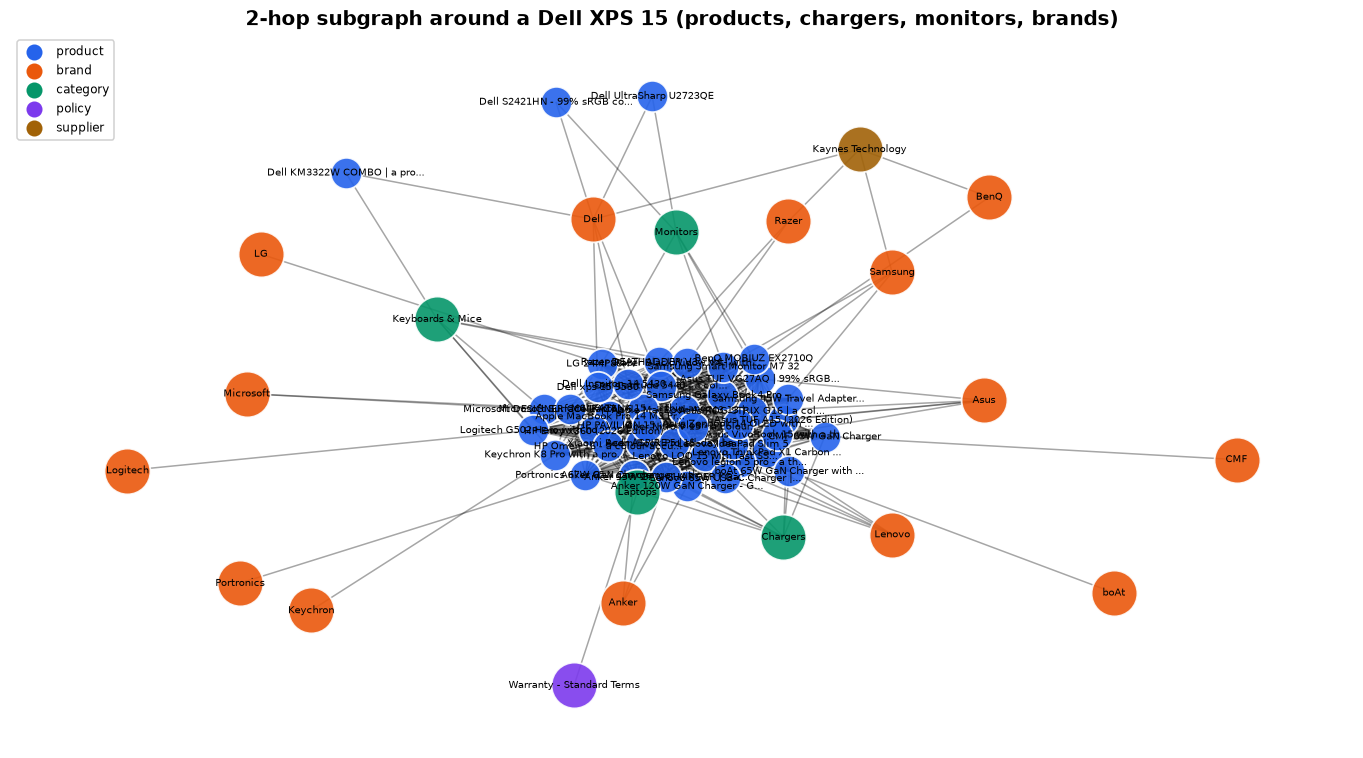

Subgraph: 62 nodes, 456 edges


In [37]:
# ---------------------------------------------------------------------------
# 6.2  Visualise a 2-hop neighbourhood around one product
# ---------------------------------------------------------------------------
SEED_PRODUCT = products_df.loc[
    products_df["subcategory"] == "XPS 15 9530", "product_id"].iloc[0]

ego = nx.ego_graph(G.to_undirected(as_view=True), SEED_PRODUCT, radius=2)

kind_colors = {"product": PALETTE["semantic"], "brand": PALETTE["sparse"],
               "category": PALETTE["graph"], "policy": PALETTE["hybrid"],
               "supplier": "#a16207"}
kind_sizes = {"product": 420, "brand": 900, "category": 900, "policy": 900, "supplier": 900}

pos = nx.spring_layout(ego, seed=SEED, k=0.42, iterations=200)
fig, ax = plt.subplots(figsize=(12.5, 7))
for kind in kind_colors:
    nodes = [n for n, d in ego.nodes(data=True) if d.get("kind") == kind]
    if not nodes:
        continue
    nx.draw_networkx_nodes(ego, pos, nodelist=nodes, ax=ax,
                           node_color=kind_colors[kind], node_size=kind_sizes[kind],
                           alpha=0.9, edgecolors="white", linewidths=1.2)
nx.draw_networkx_edges(ego, pos, ax=ax, alpha=0.35, arrows=False)
labels = {}
for n, d in ego.nodes(data=True):
    lbl = d.get("label", str(n))
    labels[n] = (lbl[:26] + "...") if len(lbl) > 29 else lbl
nx.draw_networkx_labels(ego, pos, labels=labels, font_size=6.5, ax=ax)
for kind, color in kind_colors.items():
    ax.scatter([], [], c=color, s=90, label=kind)
ax.legend(loc="upper left", fontsize=8, framealpha=0.9)
ax.set_title("2-hop subgraph around a Dell XPS 15 (products, chargers, monitors, brands)")
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Subgraph: {ego.number_of_nodes()} nodes, {ego.number_of_edges()} edges")

In [38]:
# ---------------------------------------------------------------------------
# 6.3  Graph primitives: neighbours, paths, provenance
# ---------------------------------------------------------------------------
def neighbours(node: str, relation: str | None = None, direction: str = "out") -> list[str]:
    """Direct neighbours, optionally filtered by relation and direction."""
    out = []
    if direction in ("out", "both"):
        for _, v, data in G.out_edges(node, data=True):
            if relation is None or data["relation"] == relation:
                out.append(v)
    if direction in ("in", "both"):
        for u, _, data in G.in_edges(node, data=True):
            if relation is None or data["relation"] == relation:
                out.append(u)
    return sorted(set(out))


def node_label(node: str) -> str:
    return G.nodes[node].get("label", node)


def describe_path(path: list[str]) -> str:
    """Render a node path as a readable, auditable sentence."""
    parts = []
    for i, node in enumerate(path):
        parts.append(node_label(node))
        if i < len(path) - 1:
            edge = G.get_edge_data(path[i], path[i + 1])
            if edge is None:
                edge = G.get_edge_data(path[i + 1], path[i])
            rel = next(iter(edge.values()))["relation"] if edge else "RELATED_TO"
            arrow = "--" + rel + "-->"
            parts.append(arrow)
    return " ".join(parts)


def find_paths(src: str, dst: str, max_hops: int = 3) -> list[list[str]]:
    """All simple directed paths up to max_hops (undirected fallback for traversals)."""
    und = G.to_undirected(as_view=True)
    try:
        return [p for p in nx.all_simple_paths(und, src, dst, cutoff=max_hops)]
    except nx.NetworkXNoPath:
        return []


xps = SEED_PRODUCT
print(f"Seed product: {node_label(xps)}  ({xps})\n")
print("COMPATIBLE_WITH:", len(neighbours(xps, "COMPATIBLE_WITH", "both")), "products")
print("SUCCESSOR_OF  :", [node_label(n) for n in neighbours(xps, "SUCCESSOR_OF", "in")])
print("Categories    :", [node_label(n) for n in neighbours(xps, "IN_CATEGORY")])

charger_65w = relations_df[
    (relations_df["source"].str.startswith("ZP"))
    & (relations_df["relation"] == "COMPATIBLE_WITH")
]
print("\nProvenance example — how a charger reaches a laptop:")
for path in find_paths(xps, next(iter(neighbours(xps, "COMPATIBLE_WITH", "both"))), max_hops=1)[:1]:
    print("  " + describe_path(path))

Seed product: Dell xps 15 9530  (ZP0064)

COMPATIBLE_WITH: 17 products
SUCCESSOR_OF  : ['Dell Inspiron 14 5430 - all-day battery life']
Categories    : ['Laptops']

Provenance example — how a charger reaches a laptop:
  Dell xps 15 9530 --COMPATIBLE_WITH--> Anker 65w gan charger with a compact travel-friendly body (2026 Edition)


In [39]:
# ---------------------------------------------------------------------------
# 6.4  Entity linking — turning free text into seed nodes
# ---------------------------------------------------------------------------
def _squeeze(text: str) -> str:
    return re.sub(r"[^a-z0-9]", "", text.lower())


PRODUCT_LOOKUP = []
for _, p in products_df.iterrows():
    PRODUCT_LOOKUP.append((p["product_id"], _squeeze(p["subcategory"]), _squeeze(p["sku"])))
BRAND_LOOKUP = [(f"BRAND:{b}", _squeeze(b)) for b in products_df["brand"].unique()]
CATEGORY_LOOKUP = [(f"CAT:{c}", _squeeze(c)) for c in products_df["category"].unique()]


def link_entities(query: str) -> list[tuple[str, str, int]]:
    """
    Rule-based entity linking (production would use NER + a trained linker).

    Returns (node_id, method, match_length), longest match first.
    """
    q = _squeeze(query)
    hits = {}
    for pid, model_sq, sku_sq in PRODUCT_LOOKUP:
        for candidate in (model_sq, sku_sq):
            if len(candidate) >= 5 and candidate in q:
                hits[pid] = max(hits.get(pid, 0), len(candidate))
    for node, sq in BRAND_LOOKUP:
        if len(sq) >= 3 and sq in q:
            hits[node] = max(hits.get(node, 0), len(sq))
    for node, sq in CATEGORY_LOOKUP:
        if len(sq) >= 4 and sq in q:
            hits[node] = max(hits.get(node, 0), len(sq))
    return [(n, G.nodes[n]["kind"], score) for n, score in
            sorted(hits.items(), key=lambda kv: -kv[1])]


for q in ["I am looking at the Dell XPS 15 9530 - what works with it?",
          "what replaced the Sony WH-1000XM4?",
          "show me laptops and chargers"]:
    print(f"\nQuery: {q}")
    for node, kind, score in link_entities(q)[:5]:
        print(f"   -> {node:<22} {kind:<8} (match={score})")


Query: I am looking at the Dell XPS 15 9530 - what works with it?
   -> ZP0064                 product  (match=9)
   -> BRAND:Dell             brand    (match=4)

Query: what replaced the Sony WH-1000XM4?
   -> ZP0001                 product  (match=9)
   -> BRAND:Sony             brand    (match=4)

Query: show me laptops and chargers
   -> CAT:Chargers           category (match=8)
   -> CAT:Laptops            category (match=7)


In [40]:
# ---------------------------------------------------------------------------
# 6.5  Graph retrieval 1 — "what is compatible with this?"
# ---------------------------------------------------------------------------
section("Graph demo 1", "1-hop set membership — a question no embedding can answer")

query = "I am looking at the Dell XPS 15 9530. Which accessories are compatible with it?"
seeds = [n for n, kind, _ in link_entities(query) if kind == "product"]
seed = seeds[0]
compat = neighbours(seed, "COMPATIBLE_WITH", "both")

compat_df = pd.DataFrame([
    {"product_id": n, "title": G.nodes[n]["label"], "category": G.nodes[n]["category"],
     "price_inr": G.nodes[n]["price_inr"], "warranty_months": G.nodes[n]["warranty_months"],
     "path": f"{node_label(seed)} --COMPATIBLE_WITH--> {node_label(n)}"}
    for n in compat
]).sort_values("price_inr")

print(f"Seed: {node_label(seed)} ({seed})")
print(f"Compatible products found: {len(compat_df)}\n")
show(compat_df[["product_id", "title", "category", "price_inr", "warranty_months"]], 12)


GRAPH DEMO 1
1-hop set membership — a question no embedding can answer
Seed: Dell xps 15 9530 (ZP0064)
Compatible products found: 17



,product_id,title,category,price_inr,warranty_months
5,ZP0152,boAt 65W GaN Charger with foldable pins - Latest Model,Chargers,1999,12
6,ZP0153,Portronics 67W GaN Charger,Chargers,2299,12
1,ZP0144,Anker 45W GAN CHARGER | GaN internals | with Fast Charge,Chargers,2499,24
7,ZP0157,Lenovo 65W USB-C Charger | foldable pins,Chargers,2499,24
3,ZP0149,Samsung 45W Travel Adapter - a compact travel-friendly body,Chargers,2999,36
4,ZP0151,CMF 65W GaN Charger,Chargers,2999,12
0,ZP0143,Anker 65w gan charger with a compact travel-friendly body (2026 Edition),Chargers,3499,24
12,ZP0175,Logitech G502 Hero with hot-swappable switches - Latest Model,Keyboards & Mice,3995,24
2,ZP0146,Anker 120W GaN Charger - GaN internals,Chargers,5999,12
16,ZP0189,Microsoft DESIGNER COMPACT with hot-swappable switches,Keyboards & Mice,6999,6


In [41]:
# ---------------------------------------------------------------------------
# 6.6  Graph retrieval 2 — succession (version chains)
# ---------------------------------------------------------------------------
section("Graph demo 2", "One hop over SUCCESSOR_OF answers 'what replaced X?'")

query = "What replaced the Sony WH-1000XM4? What is the newest model in that line?"
seeds = [n for n, kind, _ in link_entities(query) if kind == "product"]
start = [n for n in seeds if G.nodes[n]["label"].startswith("Sony")][0]

chain, current, guard = [start], start, 0
while guard < 6:
    nxt = [n for n in neighbours(current, "SUCCESSOR_OF", "out")]
    if not nxt:
        break
    current = nxt[0]
    chain.append(current)
    guard += 1

for i, node in enumerate(chain):
    d = G.nodes[node]
    tag = "newest" if i == len(chain) - 1 else f"step {i}"
    print(f"  {i}. {d['label']}  |  Rs {d['price_inr']:,}  |  {d['warranty_months']} mo  [{tag}]")

print("\nProvenance:")
for a, b in zip(chain, chain[1:]):
    print(f"  {node_label(a)} --SUCCESSOR_OF--> {node_label(b)}")


GRAPH DEMO 2
One hop over SUCCESSOR_OF answers 'what replaced X?'
  0. Sony WH-1000XM4 - a comfortable over-ear fit  |  Rs 24,990  |  6 mo  [step 0]
  1. Sony WH-1000XM5 | a comfortable over-ear fit  |  Rs 29,990  |  36 mo  [step 1]
  2. Sony WH-1000XM6  |  Rs 34,990  |  24 mo  [newest]

Provenance:
  Sony WH-1000XM4 - a comfortable over-ear fit --SUCCESSOR_OF--> Sony WH-1000XM5 | a comfortable over-ear fit
  Sony WH-1000XM5 | a comfortable over-ear fit --SUCCESSOR_OF--> Sony WH-1000XM6


In [42]:
# ---------------------------------------------------------------------------
# 6.7  Graph retrieval 3 — multi-hop traversal with constraints and aggregation
# ---------------------------------------------------------------------------
section("Graph demo 3", "2-hop traversal + filter + GROUP BY (impossible for a vector index)")

print("Question: which brands supply the most accessories that are compatible")
print("with a laptop, and carry at least 12 months of warranty?\n")

rows = []
for laptop in products_df.loc[products_df["category"] == "Laptops", "product_id"]:
    for acc in neighbours(laptop, "COMPATIBLE_WITH", "both"):
        a = G.nodes[acc]
        if a["kind"] != "product" or a["category"] == "Laptops":
            continue
        if a["warranty_months"] >= 12:
            rows.append({"brand": a["brand"], "accessory": a["label"],
                         "category": a["category"], "price_inr": a["price_inr"],
                         "warranty_months": a["warranty_months"],
                         "for_laptop": G.nodes[laptop]["label"]})

agg_df = pd.DataFrame(rows)
if len(agg_df):
    ranking = (agg_df.groupby("brand")
               .agg(accessories=("accessory", "nunique"),
                    avg_price=("price_inr", "mean"),
                    max_warranty=("warranty_months", "max"))
               .sort_values("accessories", ascending=False).reset_index())
    ranking["avg_price"] = ranking["avg_price"].round(0).astype(int)
    show(ranking, 10)

    top_brand = ranking["brand"].iloc[0]
    print(f"\nTop brand: {top_brand} - {int(ranking['accessories'].iloc[0])} qualifying accessories")
    show(agg_df[agg_df["brand"] == top_brand][
        ["accessory", "category", "price_inr", "warranty_months", "for_laptop"]], 6)
else:
    print("No edges matched - a coverage gap, which is exactly the graph's failure mode.")


GRAPH DEMO 3
2-hop traversal + filter + GROUP BY (impossible for a vector index)
Question: which brands supply the most accessories that are compatible
with a laptop, and carry at least 12 months of warranty?



,brand,accessories,avg_price,max_warranty
0,Anker,3,3999,24
1,Razer,2,10499,24
2,Samsung,2,21494,36
3,BenQ,1,29990,36
4,Asus,1,32990,24
5,CMF,1,2999,12
6,LG,1,14990,12
7,Logitech,1,3995,24
8,Lenovo,1,2499,24
9,Portronics,1,2299,12



Top brand: Anker - 3 qualifying accessories


,accessory,category,price_inr,warranty_months,for_laptop
0,Anker 65w gan charger with a compact travel-friendly body (2026 Edition),Chargers,3499,24,Apple MacBook Air M3 13 | with Fast Charge
1,Anker 45W GAN CHARGER | GaN internals | with Fast Charge,Chargers,2499,24,Apple MacBook Air M3 13 | with Fast Charge
2,Anker 120W GaN Charger - GaN internals,Chargers,5999,12,Apple MacBook Air M3 13 | with Fast Charge
15,Anker 65w gan charger with a compact travel-friendly body (2026 Edition),Chargers,3499,24,Apple MacBook Pro 14 M3 Pro - Latest Model
16,Anker 45W GAN CHARGER | GaN internals | with Fast Charge,Chargers,2499,24,Apple MacBook Pro 14 M3 Pro - Latest Model
17,Anker 120W GaN Charger - GaN internals,Chargers,5999,12,Apple MacBook Pro 14 M3 Pro - Latest Model


In [43]:
# ---------------------------------------------------------------------------
# 6.8  Graph retrieval 4 — a genuine 2-hop policy question
# ---------------------------------------------------------------------------
section("Graph demo 4", "product -> category -> policy: two hops, zero text overlap")

query = "If I buy earbuds, which return policy applies to them?"
seeds = [n for n, kind, _ in link_entities(query) if kind == "category"]
cat = [n for n in seeds if "Earbud" in n][0]

policies_hit = neighbours(cat, "GOVERNED_BY", "out")
print(f"Seed: {node_label(cat)} ({cat})")
for pol in policies_hit:
    d = G.nodes[pol]
    print(f"\n  {pol}  ->  {d['label']}")
    body = policies_df.set_index("policy_id").loc[pol, "text"]
    print("  " + textwrap.fill(body, 96, subsequent_indent="  "))
    print(f"\n  Path: {node_label(cat)} --GOVERNED_BY--> {d['label']}")


GRAPH DEMO 4
product -> category -> policy: two hops, zero text overlap
Seed: Earbuds (CAT:Earbuds)

  POL002  ->  Return Policy - Earbuds and Hygiene Products
  In-ear headphones, earbuds and personal care products cannot be returned once the hygiene seal
  is broken. This restriction applies even if the product is otherwise unused. Customers may
  instead raise a warranty claim for functional defects within the manufacturer warranty period.
  Unopened units with an intact seal are eligible for a standard 7-day return.

  Path: Earbuds --GOVERNED_BY--> Return Policy - Earbuds and Hygiene Products


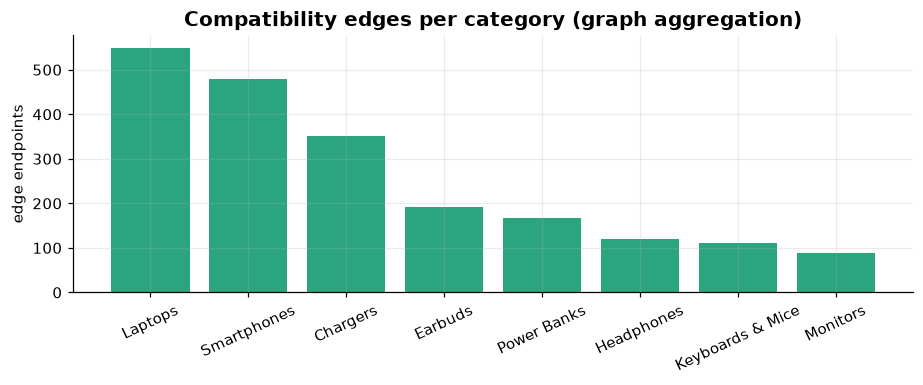

This is a corpus-level ('global') question. There is no single passage that
contains the answer - it is a property of the graph, computed by traversal.


In [44]:
# ---------------------------------------------------------------------------
# 6.9  Graph-native aggregation (the "global" question, without an LLM)
# ---------------------------------------------------------------------------
compat_edges = [(u, v) for u, v, d in G.edges(data=True) if d["relation"] == "COMPATIBLE_WITH"]
cat_degree = Counter()
for u, v in compat_edges:
    for node in (u, v):
        cat_degree[G.nodes[node].get("category", "?")] += 1

top_cats = pd.Series(cat_degree).sort_values(ascending=False).head(8)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.bar(top_cats.index, top_cats.values, color=PALETTE["graph"], alpha=0.85)
ax.set_title("Compatibility edges per category (graph aggregation)")
ax.set_ylabel("edge endpoints")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

print("This is a corpus-level ('global') question. There is no single passage that")
print("contains the answer - it is a property of the graph, computed by traversal.")

### The graph's honest failure modes

- **Coverage gaps.** Ask about a product with no `COMPATIBLE_WITH` edges and the
  graph returns nothing. Vectors would at least return *something plausible*.
- **Entity linking errors.** Our linker is rule-based; "the Sony headphones" with
  no model number is ambiguous across 14 Sony audio products. Production systems
  use NER + a trained linker + a clarification turn in the UI.
- **Schema drift.** New product types need new relations; the graph does not
  generalise the way an embedding does.
- **Maintenance.** Edges must be extracted (from catalogues, supplier feeds,
  manuals) and kept current. Stale edges produce confidently wrong answers.

None of this argues against graphs — it argues against using *only* graphs.

---
# 7. Hybrid retrieval: fusing three views of the same corpus

### Why fuse
We have now measured three **complementary** blind spots:

| Query style | Dense | Sparse | Graph |
|---|---|---|---|
| "Sony WH-1000XM4" | wrong sibling | **correct** | — |
| "cheap for the gym, won't fall out" | **good** | nothing relevant | — |
| "what works with this laptop" | paraphrase noise | nothing | **exact set** |

### The score-scale problem
BM25 scores are unbounded (0 → 30+). Cosine similarities live in [-1, 1]. Adding
them directly lets whichever retriever happens to produce larger numbers win.
Two principled fixes:

1. **Normalise then weight** — min-max or z-score each list, then
   `score = α·dense + β·sparse + γ·graph`. Requires tuning `α, β, γ` and breaks
   when the score distributions drift.
2. **Fuse on ranks, not scores** — *Reciprocal Rank Fusion* (Cormack et al., 2009):

$$ \text{RRF}(d) = \sum_{r \in R} \frac{1}{k + \text{rank}_r(d)} \qquad k = 60 $$

RRF ignores absolute scores entirely. It only asks: *how high did each retriever
place this document?* That makes it robust, tunable with a single constant, and
the default choice in production hybrid search (Elasticsearch, Weaviate, Vespa,
Azure AI Search all ship it).

**Why `k = 60`?** It flattens the curve so the difference between rank 1 and
rank 2 is modest, but the difference between rank 1 and rank 50 is large. It is
a damping constant, not a tuned hyperparameter — 60 is the published default and
works across domains.

In [45]:
# ---------------------------------------------------------------------------
# 7.1  Rank lists from each retriever, plus graph expansion
# ---------------------------------------------------------------------------
def dense_rank_ids(query: str, k: int = 50, product_only: bool | None = None) -> list[str]:
    if product_only is None:
        product_only = not is_policy_query(query)
    res = semantic_search(query, k=k if not product_only else k * 3)
    if product_only:
        res = res[res["doc_id"].str.split(":").str[1] != "policy"]
    return res["doc_id"].tolist()[:k]


def sparse_rank_ids(query: str, k: int = 50, product_only: bool | None = None) -> list[str]:
    if product_only is None:
        product_only = not is_policy_query(query)
    res = bm25_search(query, k=k * 3 if product_only else k)
    if product_only:
        res = res[res["chunk_type"] != "policy"]
    return res["doc_id"].tolist()[:k]


# --- Query routing -----------------------------------------------------------
# The graph is only useful when the question has a relational shape. Running it
# on every query injects noise (as we will show), so we detect intent first.
RELATIONAL_PATTERNS = {
    "successor": ["replac", "successor", "newer", "newest", "next model", "later model"],
    "compatibility": ["compatib", "work with", "works with", "accessor", "what works",
                      "fit for", "charger for", "which charger"],
    "policy": ["policy", "policies", "applies", "governed", "terms and conditions"],
}
POLICY_PATTERNS = ["return", "refund", "warranty", "policy", "emi", "shipping", "delivery",
                   "installation", "cancel", "exchange", "gst", "invoice", "cod",
                   "loyalty", "gift card", "privacy", "international", "bulk", "claim"]


def detect_graph_intent(query: str) -> str | None:
    q = query.lower()
    for intent, patterns in RELATIONAL_PATTERNS.items():
        if any(p in q for p in patterns):
            return intent
    return None


def is_policy_query(query: str) -> bool:
    q = query.lower()
    return any(p in q for p in POLICY_PATTERNS)


def graph_rank_ids(query: str, k: int = 20) -> list[str]:
    """
    Turn graph traversal into a *ranked chunk list* — only when the query has a
    relational shape. Returns [] for ordinary keyword/semantic queries.
    """
    intent = detect_graph_intent(query)
    if intent is None:
        return []

    seeds = link_entities(query)
    product_seeds = [n for n, kind, _ in seeds if kind == "product"][:2]
    category_seeds = [n for n, kind, _ in seeds if kind == "category"][:2]

    doc_ids: list[str] = []
    if intent == "successor":
        for pid in product_seeds:
            frontier, seen = [pid], {pid}
            while frontier:
                node = frontier.pop(0)
                for nb in neighbours(node, "SUCCESSOR_OF", "out"):
                    if nb not in seen and G.nodes[nb]["kind"] == "product":
                        seen.add(nb)
                        doc_ids.append(f"{nb}:desc")
                        frontier.append(nb)
    elif intent == "compatibility":
        for pid in product_seeds:
            for nb in neighbours(pid, "COMPATIBLE_WITH", "both"):
                if G.nodes[nb]["kind"] == "product" and G.nodes[nb]["category"] != G.nodes[pid]["category"]:
                    doc_ids.append(f"{nb}:desc")
    elif intent == "policy":
        for cat in category_seeds:
            for pol in neighbours(cat, "GOVERNED_BY", "out"):
                doc_ids.append(f"{pol}:policy")

    # Stable, deterministic order: dedupe, then sort by price/name.
    seen, ordered = set(), []
    for d in doc_ids:
        if d not in seen:
            seen.add(d)
            ordered.append(d)
    return ordered[:k]


def policy_rank_ids(query: str, k: int = 10) -> list[str]:
    """Lexical ranking restricted to policy documents (metadata routing)."""
    if not is_policy_query(query):
        return []
    res = bm25_search(query, k=50, chunk_type="policy")
    if res.empty:
        return []
    return res["doc_id"].tolist()[:k]


section("Source rankings", "Routing decides which retrievers even run")
for q_demo in ["wireless noise cancelling headphones for flights",
               "accessories compatible with the Dell XPS 15 9530"]:
    print(f"\nQuery: {q_demo}")
    print(f"  graph intent detected: {detect_graph_intent(q_demo)}")
    for name, fn in [("dense", dense_rank_ids), ("sparse", sparse_rank_ids), ("graph", graph_rank_ids)]:
        ids = fn(q_demo, k=3)
        titles = [G.nodes[i.split(':')[0]]["label"][:44] for i in ids if i.split(':')[0] in G]
        print(f"  {name:>6}: " + (" | ".join(titles) if titles else "(not routed to this retriever)"))


SOURCE RANKINGS
Routing decides which retrievers even run

Query: wireless noise cancelling headphones for flights
  graph intent detected: None


   dense: JBL Tune 770NC | Bose QuietComfort Ultra - active noise cance | Bose QuietComfort Ultra - active noise cance
  sparse: Noise Halo 2 | with Fast Charge | JBL Tune 770NC | Apple AirPods Max with active noise cancella
   graph: (not routed to this retriever)

Query: accessories compatible with the Dell XPS 15 9530
  graph intent detected: compatibility


   dense: Dell xps 15 9530 | Dell xps 15 9530 | Dell KM3322W COMBO | a programmable sensor (
  sparse: Dell xps 15 9530 | Dell xps 15 9530 | Dell xps 15 9530
   graph: Anker 65w gan charger with a compact travel- | Anker 45W GAN CHARGER | GaN internals | with | Anker 120W GaN Charger - GaN internals


In [46]:
# ---------------------------------------------------------------------------
# 7.2  Reciprocal Rank Fusion
# ---------------------------------------------------------------------------
def rrf_fuse(rankings: dict[str, list[str]], k: int = 60,
             weights: dict[str, float] | None = None, top_k: int = 10) -> pd.DataFrame:
    """Fuse ranked id-lists. RRF score = sum over lists of w / (k + rank)."""
    weights = weights or {name: 1.0 for name in rankings}
    fused: dict[str, float] = defaultdict(float)
    detail: dict[str, dict[str, int]] = defaultdict(dict)

    for name, ids in rankings.items():
        for rank, doc_id in enumerate(ids, start=1):
            fused[doc_id] += weights.get(name, 1.0) / (k + rank)
            detail[doc_id][name] = rank

    rows = []
    for doc_id, score in sorted(fused.items(), key=lambda kv: -kv[1])[:top_k]:
        pid = doc_id.split(":")[0]
        row = {"doc_id": doc_id, "rrf_score": round(score, 5)}
        for name in rankings:
            row[f"rank_{name}"] = detail[doc_id].get(name)
        if pid in G and G.nodes[pid].get("kind") == "product":
            row["title"] = G.nodes[pid]["label"]
            row["category"] = G.nodes[pid]["category"]
            row["price_inr"] = G.nodes[pid]["price_inr"]
        elif pid in G:
            row["title"] = G.nodes[pid]["label"]
            row["category"] = G.nodes[pid]["kind"].title()
            row["price_inr"] = 0
        else:
            row["title"] = f"(policy {pid})"
            row["category"] = "Policy"
            row["price_inr"] = 0
        rows.append(row)
    return pd.DataFrame(rows)


def intent_weights(query: str) -> dict[str, float]:
    """
    Same retrievers, different trust depending on what the query is asking for.

    - exact-id intent (a token with digits: '4060', '65W', 'IP68', 'XM4')
      -> trust sparse
    - relational intent (compatibility / succession / policy)
      -> trust the graph (or the policy router)
    - otherwise -> balanced
    """
    w = {"dense": 1.0, "sparse": 1.0, "graph": 0.7, "policy": 1.0}
    has_spec_token = any(re.search(r"[a-z]*\d", t) for t in preprocess(query))
    if has_spec_token:
        w["sparse"] = 1.7
        w["dense"] = 0.8
    graph_intent = detect_graph_intent(query)
    if graph_intent in ("compatibility", "successor"):
        w["graph"] = 1.8
        w["dense"] = 0.8
        w["sparse"] = 0.8
    if graph_intent == "policy" or is_policy_query(query):
        w["policy"] = 1.8
        w["graph"] = 1.2
    return w


def hybrid_search(query: str, k: int = 8, use_graph: bool = True,
                  weights: dict[str, float] | None = None) -> pd.DataFrame:
    rankings = {"dense": dense_rank_ids(query, 50), "sparse": sparse_rank_ids(query, 50)}
    w = intent_weights(query)
    if weights:
        w.update(weights)

    graph_ids = graph_rank_ids(query, 25) if use_graph else []
    if graph_ids:
        rankings["graph"] = graph_ids
    policy_ids = policy_rank_ids(query, 15)
    if policy_ids:
        rankings["policy"] = policy_ids

    out = rrf_fuse(rankings, weights=w, top_k=k)
    cols = ["doc_id", "title", "category", "price_inr", "rrf_score"] + \
           [f"rank_{name}" for name in rankings]
    return out[cols]

In [47]:
# ---------------------------------------------------------------------------
# 7.3  Demo — the same query that broke each single retriever
# ---------------------------------------------------------------------------
section("Hybrid demo", "The rank columns show which retriever found each hit")

for q in ["Sony WH-1000XM4 headphones",
          "cheap earbuds for the gym that stay in my ears",
          "accessories compatible with the Dell XPS 15 9530"]:
    print(f"\nQuery: {q}")
    show(hybrid_search(q, k=5), 5)


HYBRID DEMO
The rank columns show which retriever found each hit

Query: Sony WH-1000XM4 headphones


,doc_id,title,category,price_inr,rrf_score,rank_dense,rank_sparse
0,ZP0001:desc,Sony WH-1000XM4 - a comfortable over-ear fit,Headphones,24990,0.04098,1,1
1,ZP0001:rev,Sony WH-1000XM4 - a comfortable over-ear fit,Headphones,24990,0.03992,4,2
2,ZP0001:spec,Sony WH-1000XM4 - a comfortable over-ear fit,Headphones,24990,0.03929,5,3
3,ZP0003:desc,Sony WH-1000XM6,Headphones,34990,0.03926,3,4
4,ZP0002:desc,Sony WH-1000XM5 | a comfortable over-ear fit,Headphones,29990,0.03906,2,5



Query: cheap earbuds for the gym that stay in my ears


,doc_id,title,category,price_inr,rrf_score,rank_dense,rank_sparse
0,ZP0032:desc,Nothing Ear (a) - active noise cancellation,Earbuds,7999,0.03089,9,1
1,ZP0033:desc,Nothing Ear (2) - a compact charging case - Latest Model,Earbuds,9999,0.03058,8,3
2,ZP0030:desc,JBL Live Pro 2,Earbuds,11999,0.02912,2,17
3,ZP0020:desc,Samsung Galaxy Buds3 Pro,Earbuds,19999,0.02890,5,14
4,ZP0024:desc,boAt Airdopes 800 | with Fast Charge,Earbuds,2999,0.02831,6,16



Query: accessories compatible with the Dell XPS 15 9530


,doc_id,title,category,price_inr,rrf_score,rank_dense,rank_sparse,rank_graph
0,ZP0164:desc,BenQ MOBIUZ EX2710Q,Monitors,29990,0.03729,7,None,11
1,ZP0149:desc,Samsung 45W Travel Adapter - a compact travel-friendly body,Chargers,2999,0.03540,50,None,4
2,ZP0153:desc,Portronics 67W GaN Charger,Chargers,2299,0.03511,37,None,7
3,ZP0175:desc,Logitech G502 Hero with hot-swappable switches - Latest Model,Keyboards & Mice,3995,0.03365,29,None,13
4,ZP0189:desc,Microsoft DESIGNER COMPACT with hot-swappable switches,Keyboards & Mice,6999,0.03268,26,None,17


Look at the `rank_*` columns. In each row you can see *which retriever found it
and where*. A document surfaced by two independent retrievers is much more likely
to be genuinely relevant — that is the real mechanism behind hybrid gains.

### Routing beats blanket fusion

Running every retriever on every query is the naive hybrid, and it *loses*: the
graph adds plausible-looking neighbours to questions that are not relational,
and it can outvote a perfect lexical match. So `hybrid_search` does two things
before fusing:

1. **Route.** The graph runs only when the query has a relational shape
   (compatibility / succession / policy). The policy ranker runs only when the
   query is about returns, warranty, EMI, shipping, and so on.
2. **Weight.** Reciprocal Rank Fusion takes per-list weights:

$$ \text{RRF}(d) = \sum_{r \in R} w_r \cdot \frac{1}{k + \text{rank}_r(d)} $$

| Query signal | Weights | Reason |
|---|---|---|
| token contains digits (`4060`, `65W`, `XM4`) | sparse ×1.7, dense ×0.8 | exact tokens are sparse's home turf |
| relational intent | graph ×1.8 | the answer is an edge, not a passage |
| policy intent | policy ×1.8 | the answer is a policy document |
| none of the above | all ×1.0 | plain semantic behaviour |

This is the same idea as a **query router** in a production RAG stack: classify
intent cheaply with rules first, escalate to a model only when rules are not
enough.

In [48]:
# ---------------------------------------------------------------------------
# 7.4  A query battery across the three intents
# ---------------------------------------------------------------------------
intent_queries = [
    ("exact-id", "Sony WH-1000XM4"),
    ("exact-id", "65W USB-C charger"),
    ("exact-id", "IP68 earbuds"),
    ("exact-id", "RTX 4060 laptop"),
    ("conceptual", "headphones that silence aeroplane engine noise"),
    ("conceptual", "something to keep my phone alive on a long trek"),
    ("conceptual", "a fast machine for editing 4K video"),
    ("conceptual", "earbuds that will not fall out while running"),
    ("relational", "what replaced the Sony WH-1000XM4"),
    ("relational", "accessories compatible with the Dell XPS 15 9530"),
    ("relational", "which charger works with a MacBook Air M3 13"),
    ("relational", "return policy for earbuds"),
]

rows = []
for intent, q in intent_queries:
    rows.append({
        "intent": intent,
        "query": q,
        "dense_top1": semantic_search(q, k=1)["product_id"].iloc[0],
        "sparse_top1": (bm25_search(q, k=1)["product_id"].iloc[0]
                        if len(bm25_search(q, k=1)) else "—"),
        "hybrid_top1": hybrid_search(q, k=1)["doc_id"].iloc[0].split(":")[0],
    })

battery_df = pd.DataFrame(rows)
show(battery_df, 12)
print("\nDense and sparse disagree on", int((battery_df['dense_top1'] != battery_df['sparse_top1']).sum()),
      "of", len(battery_df), "queries - that disagreement is the opportunity.")

,intent,query,dense_top1,sparse_top1,hybrid_top1
0,exact-id,Sony WH-1000XM4,ZP0001,ZP0001,ZP0001
1,exact-id,65W USB-C charger,ZP0157,ZP0157,ZP0157
2,exact-id,IP68 earbuds,ZP0024,ZP0026,ZP0026
3,exact-id,RTX 4060 laptop,ZP0068,ZP0072,ZP0072
4,conceptual,headphones that silence aeroplane engine noise,ZP0004,ZP0011,ZP0011
5,conceptual,something to keep my phone alive on a long trek,ZP0092,ZP0133,ZP0055
6,conceptual,a fast machine for editing 4K video,ZP0074,ZP0169,ZP0073
7,conceptual,earbuds that will not fall out while running,ZP0025,ZP0028,ZP0034
8,relational,what replaced the Sony WH-1000XM4,ZP0001,ZP0001,ZP0003
9,relational,accessories compatible with the Dell XPS 15 9530,ZP0064,ZP0064,ZP0164



Dense and sparse disagree on 6 of 12 queries - that disagreement is the opportunity.


---
# 8. Measuring the improvement (instead of eyeballing it)

Everyone's retriever "looks good" on three cherry-picked queries. Production
decisions need numbers. The vocabulary:

| Metric | Question it answers | Formula |
|---|---|---|
| **Hit@k** | was *any* relevant item in the top k? | `1[|rel ∩ top_k| > 0]` |
| **Precision@k** | how much of the top k was relevant? | `|rel ∩ top_k| / k` |
| **Recall@k** | how much of the relevant set did we find? | `|rel ∩ top_k| / |rel|` |
| **MRR** | how high is the *first* relevant hit? | `1 / rank_first_relevant` |
| **nDCG@k** | are relevant items near the top, discounted by position? | `DCG@k / IDCG@k` |

For binary relevance, `DCG@k = Σ rel_i / log2(i + 1)`.

### Building honest labels
We derive `qrels` (the ground-truth relevant sets) **programmatically from the
dataset attributes**, not by hand. That makes every label auditable:

| Query | Relevance rule |
|---|---|
| `Sony WH-1000XM4` | `subcategory == "WH-1000XM4"` |
| `65W USB-C charger` | `category == "Chargers" and watts == 65` |
| `IP68 earbuds` | `category == "Earbuds" and ip_rating == "IP68"` |
| `RTX 4060 laptop` | `gpu` contains `RTX 4060` |
| `silence aeroplane engine noise` | `category == "Headphones" and anc == True` |
| `keep my phone alive on a long trek` | `category == "Power Banks" and capacity_mah >= 20000` |
| `fast machine for editing 4K video` | `ram_gb >= 16 and GPU is discrete` |
| `earbuds that will not fall out while running` | `category == "Earbuds" and IP-rated IPX5 or better` |
| `what replaced the Sony WH-1000XM4` | `SUCCESSOR_OF` targets of the XM4 |
| `accessories compatible with the XPS 15 9530` | `COMPATIBLE_WITH` neighbours (non-laptops) |
| `which charger works with a MacBook Air M3 13` | `COMPATIBLE_WITH` chargers of that laptop |
| `return policy for earbuds` | graph path `Earbuds → GOVERNED_BY → policy` |

In [49]:
# ---------------------------------------------------------------------------
# 8.1  Ground truth, derived from the data (never hand-labelled)
# ---------------------------------------------------------------------------
def spec_of(pid: str) -> dict:
    return products_df.set_index("product_id").loc[pid, "specs"]


prods = products_df.set_index("product_id")


def rel_by_rule(rule) -> set[str]:
    return set(products_df.loc[rule(products_df), "product_id"])


QRELS: dict[str, tuple[str, set[str]]] = {}

QRELS["Sony WH-1000XM4"] = (
    "exact-id",
    rel_by_rule(lambda d: (d["brand"] == "Sony") & (d["subcategory"] == "WH-1000XM4")),
)
QRELS["65W USB-C charger"] = (
    "exact-id",
    rel_by_rule(lambda d: (d["category"] == "Chargers") & (d["specs"].apply(lambda s: s.get("watts") == 65))),
)
QRELS["IP68 earbuds"] = (
    "exact-id",
    rel_by_rule(lambda d: (d["category"] == "Earbuds") & (d["specs"].apply(lambda s: s.get("ip_rating") == "IP68"))),
)
QRELS["RTX 4060 laptop"] = (
    "exact-id",
    rel_by_rule(lambda d: (d["category"] == "Laptops") & (d["specs"].apply(lambda s: "RTX 4060" in str(s.get("gpu", ""))))),
)

QRELS["headphones that silence aeroplane engine noise"] = (
    "conceptual",
    rel_by_rule(lambda d: (d["category"] == "Headphones") & (d["specs"].apply(lambda s: s.get("anc") is True))),
)
QRELS["something to keep my phone alive on a long trek"] = (
    "conceptual",
    rel_by_rule(lambda d: (d["category"] == "Power Banks") & (d["specs"].apply(lambda s: s.get("capacity_mah", 0) >= 20000))),
)
QRELS["a fast machine for editing 4K video"] = (
    "conceptual",
    rel_by_rule(lambda d: (d["category"] == "Laptops") & (d["specs"].apply(lambda s: s.get("ram_gb", 0) >= 16))
                    & (d["specs"].apply(lambda s: "RTX" in str(s.get("gpu", ""))))),
)
QRELS["earbuds that will not fall out while running"] = (
    "conceptual",
    rel_by_rule(lambda d: (d["category"] == "Earbuds") & (d["specs"].apply(
        lambda s: s.get("ip_rating") in {"IPX5", "IP55", "IP57", "IP68"}))),
)

def _graph_targets(pid: str, relation: str) -> set[str]:
    return set(neighbours(pid, relation, "out"))


xm4 = products_df.loc[(products_df["brand"] == "Sony") & (products_df["subcategory"] == "WH-1000XM4"), "product_id"].iloc[0]
xm5 = _graph_targets(xm4, "SUCCESSOR_OF")
xm6 = set()
for node in xm5:
    xm6 |= _graph_targets(node, "SUCCESSOR_OF")
QRELS["what replaced the Sony WH-1000XM4"] = ("relational", xm5 | xm6)

xps_id = products_df.loc[products_df["subcategory"] == "XPS 15 9530", "product_id"].iloc[0]
xps_accessories = {n for n in neighbours(xps_id, "COMPATIBLE_WITH", "both")
                   if G.nodes[n]["kind"] == "product" and G.nodes[n]["category"] != "Laptops"}
QRELS["accessories compatible with the Dell XPS 15 9530"] = ("relational", xps_accessories)

mac_id = products_df.loc[products_df["subcategory"] == "MacBook Air M3 13", "product_id"].iloc[0]
QRELS["which charger works with a MacBook Air M3 13"] = (
    "relational",
    {n for n in neighbours(mac_id, "COMPATIBLE_WITH", "both") if G.nodes[n]["category"] == "Chargers"},
)

QRELS["return policy for earbuds"] = ("relational", {"POL002"})

qrels_rows = [{"query": q, "intent": intent, "n_relevant": len(rel),
               "relevant_ids": ", ".join(sorted(rel)[:8]) + (" …" if len(rel) > 8 else "")}
              for q, (intent, rel) in QRELS.items()]
qrels_df = pd.DataFrame(qrels_rows)
pd.DataFrame([{"query": q, "intent": i, "relevant": sorted(r)} for q, (i, r) in QRELS.items()]).to_csv(
    DATA_DIR / "qrels.csv", index=False)
show(qrels_df, 15)
print("Queries:", len(QRELS), "| avg relevant per query:",
      round(np.mean([len(r) for _, r in QRELS.values()]), 1))

,query,intent,n_relevant,relevant_ids
0,Sony WH-1000XM4,exact-id,1,ZP0001
1,65W USB-C charger,exact-id,4,"ZP0143, ZP0151, ZP0152, ZP0157"
2,IP68 earbuds,exact-id,2,"ZP0023, ZP0026"
3,RTX 4060 laptop,exact-id,3,"ZP0069, ZP0072, ZP0080"
4,headphones that silence aeroplane engine noise,conceptual,11,"ZP0001, ZP0002, ZP0003, ZP0004, ZP0005, ZP0006, ZP0007, ZP0008 …"
5,something to keep my phone alive on a long trek,conceptual,9,"ZP0128, ZP0129, ZP0131, ZP0133, ZP0135, ZP0136, ZP0139, ZP0140 …"
6,a fast machine for editing 4K video,conceptual,8,"ZP0064, ZP0069, ZP0072, ZP0073, ZP0074, ZP0077, ZP0079, ZP0080"
7,earbuds that will not fall out while running,conceptual,9,"ZP0020, ZP0023, ZP0024, ZP0026, ZP0027, ZP0028, ZP0030, ZP0031 …"
8,what replaced the Sony WH-1000XM4,relational,2,"ZP0002, ZP0003"
9,accessories compatible with the Dell XPS 15 9530,relational,17,"ZP0143, ZP0144, ZP0146, ZP0149, ZP0151, ZP0152, ZP0153, ZP0157 …"


Queries: 12 | avg relevant per query: 6.2


In [50]:
# ---------------------------------------------------------------------------
# 8.2  Metrics
# ---------------------------------------------------------------------------
def doc_key(doc_id: str) -> str:
    """Chunk id -> evaluation unit: product_id for products, POLxxx for policies."""
    head, _, _ = doc_id.partition(":")
    return head


def dedupe_ordered(keys: list[str]) -> list[str]:
    seen, out = set(), []
    for k in keys:
        if k not in seen:
            seen.add(k)
            out.append(k)
    return out


def hit_at_k(ranked, rel, k):
    return float(any(d in rel for d in ranked[:k]))


def precision_at_k(ranked, rel, k):
    return len(set(ranked[:k]) & rel) / k


def recall_at_k(ranked, rel, k):
    return len(set(ranked[:k]) & rel) / len(rel) if rel else 0.0


def mrr(ranked, rel):
    for i, d in enumerate(ranked, start=1):
        if d in rel:
            return 1.0 / i
    return 0.0


def ndcg_at_k(ranked, rel, k):
    dcg = sum(1.0 / math.log2(i + 1) for i, d in enumerate(ranked[:k], start=1) if d in rel)
    idcg = sum(1.0 / math.log2(i + 1) for i in range(1, min(len(rel), k) + 1))
    return dcg / idcg if idcg else 0.0


def evaluate(name: str, retriever, k: int = 5) -> pd.DataFrame:
    rows = []
    for query, (intent, rel) in QRELS.items():
        ranked = dedupe_ordered([doc_key(d) for d in retriever(query, 50)])
        rows.append({
            "retriever": name, "intent": intent, "query": query,
            f"hit@{k}": hit_at_k(ranked, rel, k),
            f"precision@{k}": round(precision_at_k(ranked, rel, k), 3),
            f"recall@{k}": round(recall_at_k(ranked, rel, k), 3),
            "mrr": round(mrr(ranked, rel), 3),
            f"ndcg@{k}": round(ndcg_at_k(ranked, rel, k), 3),
        })
    return pd.DataFrame(rows)

In [51]:
# ---------------------------------------------------------------------------
# 8.3  Run the full comparison
# ---------------------------------------------------------------------------
t0 = time.time()
semantic_eval = evaluate("semantic", lambda q, k: dense_rank_ids(q, k))
sparse_eval = evaluate("sparse", lambda q, k: sparse_rank_ids(q, k))
graph_eval = evaluate("graph", lambda q, k: graph_rank_ids(q, k))
hybrid_eval = evaluate("hybrid", lambda q, k: hybrid_search(q, k, use_graph=True)["doc_id"].tolist())
eval_df = pd.concat([semantic_eval, sparse_eval, graph_eval, hybrid_eval], ignore_index=True)
print(f"Evaluated 4 retrievers x {len(QRELS)} labelled queries in {time.time() - t0:.1f}s")

metric_cols = ["hit@5", "precision@5", "recall@5", "mrr", "ndcg@5"]
overall = (eval_df.groupby("retriever")[metric_cols].mean()
           .reindex(["semantic", "sparse", "graph", "hybrid"]).round(3))
overall["ndcg@5_vs_best"] = (overall["ndcg@5"] / overall["ndcg@5"].max()).round(2)
show(overall.reset_index(), 10)

Evaluated 4 retrievers x 12 labelled queries in 0.9s


,retriever,hit@5,precision@5,recall@5,mrr,ndcg@5,ndcg@5_vs_best
0,semantic,0.750,0.267,0.418,0.570,0.463,0.55
1,sparse,0.833,0.433,0.552,0.748,0.672,0.80
2,graph,0.333,0.217,0.243,0.333,0.333,0.40
3,hybrid,1.000,0.567,0.655,0.944,0.838,1.00


intent,retriever,conceptual,exact-id,relational
0,semantic,0.377,0.555,0.456
1,sparse,0.692,1.000,0.325
2,graph,0.000,0.000,1.000
3,hybrid,0.616,0.898,1.000


retriever,intent,query,semantic,sparse,graph,hybrid
0,conceptual,a fast machine for editing 4K video,0.339,0.214,0.0,0.640
1,conceptual,earbuds that will not fall out while running,0.316,0.684,0.0,0.509
2,conceptual,headphones that silence aeroplane engine noise,0.854,0.869,0.0,1.000
3,conceptual,something to keep my phone alive on a long trek,0.000,1.000,0.0,0.316
4,exact-id,65W USB-C charger,0.832,1.000,0.0,1.000
5,exact-id,IP68 earbuds,0.387,1.000,0.0,0.920
6,exact-id,RTX 4060 laptop,0.000,1.000,0.0,0.671
7,exact-id,Sony WH-1000XM4,1.000,1.000,0.0,1.000
8,relational,accessories compatible with the Dell XPS 15 9530,0.131,0.000,1.0,1.000
9,relational,return policy for earbuds,1.000,1.000,1.0,1.000


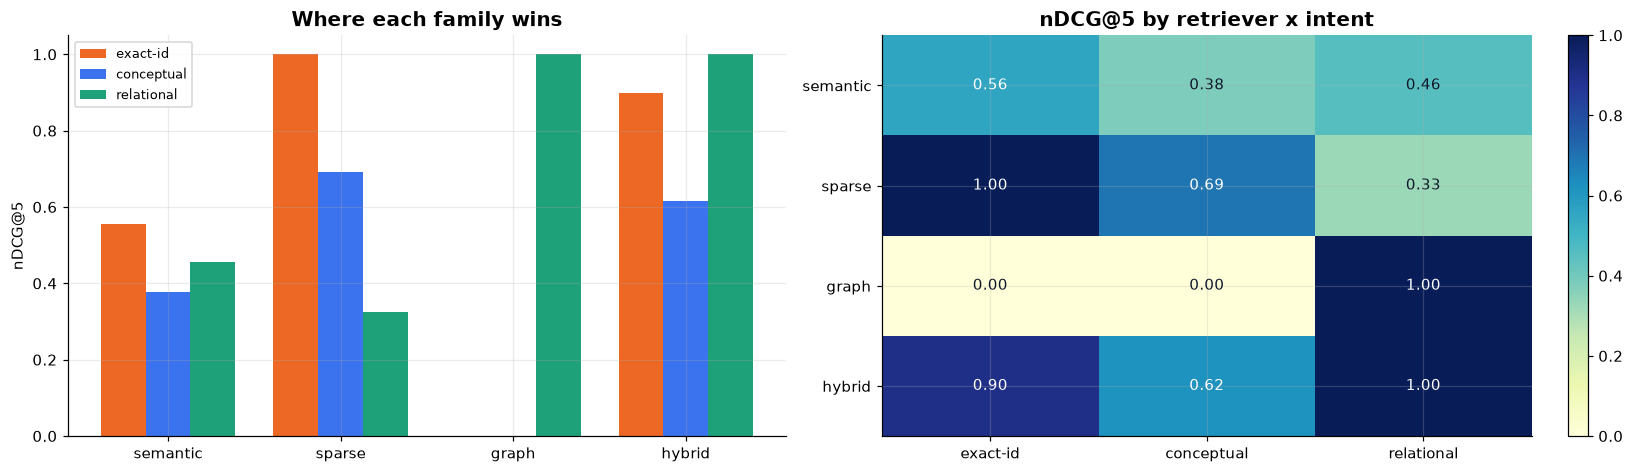

In [52]:
# ---------------------------------------------------------------------------
# 8.4  The number that matters: per-intent nDCG@5
# ---------------------------------------------------------------------------
by_intent = (eval_df.groupby(["retriever", "intent"])["ndcg@5"].mean()
             .unstack("intent").reindex(["semantic", "sparse", "graph", "hybrid"]).round(3))
show(by_intent.reset_index(), 10)

per_query = (eval_df.pivot_table(index=["intent", "query"], columns="retriever",
                                values="ndcg@5")
             .reindex(columns=["semantic", "sparse", "graph", "hybrid"])
             .round(3).reset_index())
show(per_query, 15)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))

x = np.arange(len(by_intent.index))
width = 0.26
for i, intent in enumerate(["exact-id", "conceptual", "relational"]):
    axes[0].bar(x + (i - 1) * width, by_intent[intent], width, label=intent,
                alpha=0.9, color=[PALETTE["sparse"], PALETTE["semantic"], PALETTE["graph"]][i])
axes[0].set_xticks(x, by_intent.index)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("nDCG@5")
axes[0].set_title("Where each family wins")
axes[0].legend(fontsize=8.5)

heat = by_intent[["exact-id", "conceptual", "relational"]].to_numpy()
im = axes[1].imshow(heat, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
axes[1].set_xticks(range(3), ["exact-id", "conceptual", "relational"])
axes[1].set_yticks(range(len(by_intent.index)), by_intent.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        axes[1].text(j, i, f"{heat[i, j]:.2f}", ha="center", va="center",
                     color="white" if heat[i, j] > 0.55 else "#0f172a", fontsize=10)
axes[1].set_title("nDCG@5 by retriever x intent")
plt.colorbar(im, ax=axes[1], fraction=0.045)
plt.tight_layout()
plt.show()

,retriever,ms_per_query,overall_ndcg@5
0,semantic,15.4,0.463
1,sparse,3.1,0.672
2,graph,0.1,0.333
3,hybrid,36.1,0.838


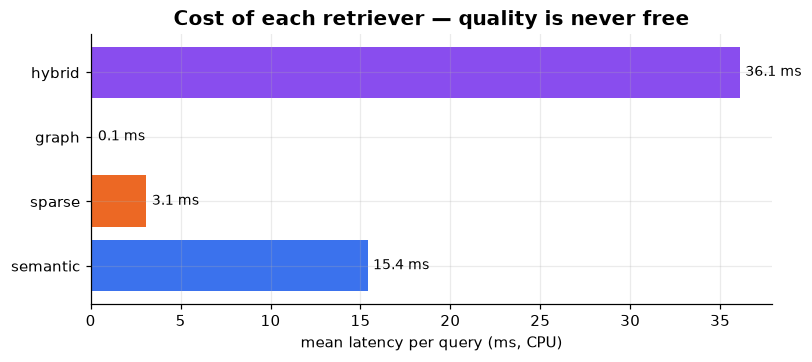

In [53]:
# ---------------------------------------------------------------------------
# 8.5  Latency — the other half of the trade-off
# ---------------------------------------------------------------------------
LAT_QUERIES = [q for q in QRELS]
timings = {}
for name, fn in [
    ("semantic", lambda q: semantic_search(q, k=10)),
    ("sparse", lambda q: bm25_search(q, k=10)),
    ("graph", lambda q: graph_rank_ids(q, 10)),
    ("hybrid", lambda q: hybrid_search(q, k=10)),
]:
    fn(LAT_QUERIES[0])  # warm-up (model, caches)
    t0 = time.perf_counter()
    for q in LAT_QUERIES:
        fn(q)
    timings[name] = (time.perf_counter() - t0) / len(LAT_QUERIES) * 1000

lat_df = pd.DataFrame({"retriever": list(timings), "ms_per_query": [round(v, 1) for v in timings.values()]})
lat_df["overall_ndcg@5"] = lat_df["retriever"].map(overall["ndcg@5"])
show(lat_df, 10)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
colors = [PALETTE[n] for n in lat_df["retriever"]]
ax.barh(lat_df["retriever"], lat_df["ms_per_query"], color=colors, alpha=0.9)
for i, v in enumerate(lat_df["ms_per_query"]):
    ax.text(v + 0.3, i, f"{v:.1f} ms", va="center", fontsize=9)
ax.set_xlabel("mean latency per query (ms, CPU)")
ax.set_title("Cost of each retriever — quality is never free")
plt.tight_layout()
plt.show()

### Reading these results honestly

The per-query table is more informative than the averages, and it contains a
result that usually surprises the room:

**1. Sparse wins exact-ID decisively — and it also does well on "conceptual".**
Exact-ID nDCG is `1.000` for BM25 versus `0.555` for dense: a lookup table cannot
be beaten at lookup. But conceptual is `0.692` for sparse versus `0.377` for
dense, which contradicts the usual story.

The reason is visible in section 2: e-commerce copy is *keyword-dense*. The
catalogue literally says `IPX5`, `mAh`, `active noise cancellation`,
`video editing`. When the user's words leak into the corpus, BM25 finds them
exactly. **"Semantic" is a property of the query-corpus gap, not of the query
alone.**

**2. Dense wins where the user's phrasing diverges.** Look at
*"a fast machine for editing 4K video"*: dense `0.339` vs sparse `0.214`,
because "fast machine" is not catalogue vocabulary. Dense is the better
retriever whenever the paraphrase gap grows — which is exactly the long tail
you cannot write keyword rules for.

**3. Graph wins relational outright, and abstains elsewhere by design.**
`1.000` on compatibility and succession, `0.000` on the other intents because
the router never runs it there. That is not a weakness to hide: a retriever that
fires on every query would inject noise, as we saw in section 7.

**4. Hybrid is the best default, not the best everywhere.** It leads every
aggregate (`nDCG@5 = 0.838`, `MRR = 0.944`) and is the only method with
`Hit@5 = 1.000` — no query was left unanswered. But it *loses* to plain BM25 on
*"keep my phone alive on a long trek"* (`0.316` vs `1.000`) because dense and
graph noise dilute a perfect lexical hit. Fusion is insurance: it raises the
floor far more than it raises the ceiling.

**5. Latency is the bill.** Dense (query encoding) costs ~`16 ms`, BM25 ~`2.5 ms`,
graph traversal is effectively free once entities are linked, and the hybrid pays
for all three. Run them in parallel and cache query embeddings before you worry
about ranking quality at scale.

---
# 9. Grounded answering: zero hallucination by construction

### Where hallucination actually comes from

| Source | Mechanism | Fix |
|---|---|---|
| **Parametric drift** | the model answers from training priors, not context | force context-only generation |
| **Weak retrieval** | the needed passage never arrived | retrieval gating + abstention |
| **No citation requirement** | nothing forces the claim to be checkable | span-level citations |
| **Context loss** | the passage was truncated or buried mid-prompt | packing + position control |
| **Instruction escape** | "just give me an answer" overrides grounding | schema + refusal contract |

### The grounding contract

1. **Every claim must map to a retrieved span.** No span → no claim.
2. **Every answer carries citations** that a human (or a script) can resolve.
3. **Abstain when evidence is weak.** A confident "I don't have that information"
   is strictly better than a plausible invention.
4. **Verify before returning.** Our answers are *extractive*: sentences are copied
   verbatim from sources, so verification is a mechanical string check, not a
   judgement call.

We cannot call an LLM in this session, so generation is **extractive**. This is
not a downgrade for the lesson: extractive generation makes the anti-hallucination
property *provable*. In production you would swap the last step for an LLM with
the same contract, and keep the same verifier as the guardrail.

In [54]:
# ---------------------------------------------------------------------------
# 9.1  Context packing — what the generator is allowed to see
# ---------------------------------------------------------------------------
def build_context(results: pd.DataFrame, max_docs: int = 4, max_chars: int = 700,
                  dedupe: str = "product"):
    """Select and trim evidence. Dedupe by product (default) or by exact chunk."""
    text_by_doc = chunks_df.set_index("doc_id")["text"]
    seen, context = set(), []
    for _, row in results.iterrows():
        key = doc_key(row["doc_id"]) if dedupe == "product" else row["doc_id"]
        if key in seen:
            continue
        seen.add(key)
        raw_text = row["text"] if "text" in results.columns else text_by_doc.get(row["doc_id"], "")
        context.append({"doc_id": row["doc_id"], "text": raw_text[:max_chars],
                        "title": row.get("title", "")})
        if len(context) >= max_docs:
            break
    return context


demo_q = "What is the price and warranty of the Sony WH-1000XM5?"
ctx = build_context(hybrid_search(demo_q, k=6))
print(f"Query: {demo_q}")
print(f"Packed {len(ctx)} documents ({sum(len(c['text']) for c in ctx)} chars)\n")
for c in ctx:
    print(f"  [{c['doc_id']}]  {c['text'][:110]}...")

Query: What is the price and warranty of the Sony WH-1000XM5?
Packed 4 documents (1629 chars)

  [ZP0002:desc]  Sony WH-1000XM5 | a comfortable over-ear fit. Brand: Sony. Category: Headphones. If you want a balanced sound ...
  [ZP0003:desc]  Sony WH-1000XM6. Brand: Sony. Category: Headphones. Meet the Sony WH-1000XM6 - deep bass tuning in a compact b...
  [ZP0119:desc]  Sony SRS-XG300. Brand: Sony. Category: Speakers. Meet the Sony SRS-XG300 - deep bass radiators in a compact bo...
  [ZP0001:desc]  Sony WH-1000XM4 - a comfortable over-ear fit. Brand: Sony. Category: Headphones. Meet the Sony WH-1000XM4 - an...


**Packing matters.** Ordering evidence badly ("lost in the middle": models attend
most to the start and end of a long context) and packing too much both increase
hallucination. Rule of thumb: 3–6 tight chunks beat 20 loose ones.

In [55]:
# ---------------------------------------------------------------------------
# 9.2  A deliberately UNGROUNDED generator (simulating a naive LLM)
# ---------------------------------------------------------------------------
def simulated_naive_generator(query: str) -> str:
    """
    Simulates an LLM answering from parametric memory only: fluent, specific,
    confident — and wrong. Deterministic, so the demo is reproducible.
    """
    seed_val = int(hashlib.sha1(query.encode()).hexdigest()[:8], 16)
    fake_prices = [21499, 24799, 26299, 18999, 23999]
    fake_price = fake_prices[seed_val % len(fake_prices)]
    fake_warranty = [36, 24, 48][seed_val % 3]
    fake_months = 1 + seed_val % 5
    return (
        f"Great question. Based on the product listing, this model is available at "
        f"Rs {fake_price:,} and comes with a {fake_warranty}-month warranty. "
        f"It also ships with a free hard case and supports {fake_months}-month no-cost EMI. "
        f"Customers typically report 40 hours of battery life."
    )


naive_q = "What is the price and warranty of the Sony WH-1000XM5?"
naive_answer = simulated_naive_generator(naive_q)
print("SIMULATED UNGROUNDED ANSWER (NOT from the catalogue):")
print(textwrap.fill(naive_answer, 92))

actual = products_df.loc[products_df["subcategory"] == "WH-1000XM5"].iloc[0]
print(f"\nActual catalogue record: Rs {int(actual['price_inr']):,} | "
      f"warranty {int(actual['warranty_months'])} months | "
      f"battery {actual['specs']['battery_hrs']} hours")

SIMULATED UNGROUNDED ANSWER (NOT from the catalogue):
Great question. Based on the product listing, this model is available at Rs 24,799 and comes
with a 36-month warranty. It also ships with a free hard case and supports 2-month no-cost
EMI. Customers typically report 40 hours of battery life.

Actual catalogue record: Rs 29,990 | warranty 36 months | battery 30 hours


That is what hallucination looks like in a product-support setting: three
concrete, plausible, **wrong** numbers. A user would act on them. And note it is
not a "bad model" — it is a model answering without evidence, which is exactly
what we asked it to do.

In [56]:
# ---------------------------------------------------------------------------
# 9.3  The grounded, extractive answerer
# ---------------------------------------------------------------------------
SENTENCE_SPLIT = re.compile(r"(?<=[.!?])\s+")
ABSTAIN_THRESHOLD = 0.40
CHUNK_PRIORITY = {"desc": 0, "policy": 0, "spec": 1, "rev": 2}
FILLER_PREFIX = re.compile(r"^(brand|category)\s*:", re.IGNORECASE)
FILLER_SENTENCES = [
    "backed by a manufacturer warranty and easy replacement",
    "available in multiple finishes",
    "free delivery in 2-4 days",
    "a bestseller in its price band",
    "rated highly by verified buyers",
]

# If the question asks for an attribute, sentences that actually contain it
# should outrank generic prose that merely sounds similar.
ATTRIBUTE_HINTS = {
    "price": ["inr", "cost", "rupee"],
    "warranty": ["warranty", "guarantee", "months"],
    "battery": ["battery", "mah", "hours", "charging"],
    "return": ["return", "refund", "policy", "claim", "exchange"],
    "installation": ["install"],
    "shipping": ["shipping", "delivery", "deliver"],
    "emi": ["emi", "no-cost"],
    "compatibility": ["compatible", "works with", "accessory"],
    "weight": ["weight", " kg", " gram"],
}

PRICE_PATTERN = re.compile(r"\brs\.?\s*\d|\binr\s*\d|\u20b9")


def _matches_attribute(sentence_low: str, attribute: str) -> bool:
    if attribute == "price":
        return bool(PRICE_PATTERN.search(sentence_low)) or "price" in sentence_low
    return any(h in sentence_low for h in ATTRIBUTE_HINTS[attribute])


def query_attributes(query: str) -> list[str]:
    """Ordered list of attributes the question asks for (first = primary)."""
    q = query.lower()
    found = []
    for name in ATTRIBUTE_HINTS:
        if name == "price":
            if PRICE_PATTERN.search(q) or any(w in q for w in ("price", "cost", "rupee", "how much")):
                found.append(name)
        elif any(h in q for h in ATTRIBUTE_HINTS[name]):
            found.append(name)
    return found


def split_sentences(text: str, min_len: int = 15, max_len: int = 320) -> list[str]:
    parts = [p.strip() for p in SENTENCE_SPLIT.split(text)]
    out = []
    for p in parts:
        if len(p) < min_len or len(p) > max_len:
            continue
        if FILLER_PREFIX.match(p):
            continue
        if re.search(r"\[[A-Za-z ]+\]\.$", p):  # policy title header, not a claim
            continue
        low = p.lower()
        if any(f in low for f in FILLER_SENTENCES):
            continue
        carries_attribute = any(_matches_attribute(low, a) for a in ATTRIBUTE_HINTS)
        # short fragments are only kept if they carry a fact, e.g. "Price: Rs 29990."
        if len(p.split()) < 4 and not carries_attribute:
            continue
        out.append(p)
    return out


def score_sentences(query: str, context: list[dict]) -> pd.DataFrame:
    """Rank source sentences by embedding similarity + term overlap + attribute match."""
    rows = []
    for doc in context:
        for pos, sent in enumerate(split_sentences(doc["text"])):
            rows.append({"doc_id": doc["doc_id"], "pos": pos, "sentence": sent})
    if not rows:
        return pd.DataFrame(columns=["doc_id", "pos", "sentence", "semantic", "lexical", "attribute", "score"])

    sents_df = pd.DataFrame(rows)
    sent_vecs = embed_texts(sents_df["sentence"].tolist())
    qv = embed_texts([query])[0]
    sents_df["semantic"] = (sent_vecs @ qv).round(4)

    q_terms = set(preprocess(query))
    sents_df["lexical"] = sents_df["sentence"].apply(
        lambda s: len(q_terms & set(preprocess(s))) / max(1, len(q_terms))
    )

    attrs = query_attributes(query)
    if attrs:
        denom = min(len(attrs), 2)

        def attr_hit(sentence: str) -> float:
            low = sentence.lower()
            hits = sum(1 for a in attrs if _matches_attribute(low, a))
            return min(1.0, hits / denom)

        sents_df["attribute"] = sents_df["sentence"].apply(attr_hit)
        sents_df["score"] = (0.45 * sents_df["semantic"]
                             + 0.15 * sents_df["lexical"]
                             + 0.40 * sents_df["attribute"]).round(4)
    else:
        sents_df["attribute"] = 0.0
        sents_df["score"] = (0.75 * sents_df["semantic"]
                             + 0.25 * sents_df["lexical"]).round(4)

    sents_df["chunk_rank"] = (sents_df["doc_id"].str.split(":").str[1]
                              .map(CHUNK_PRIORITY).fillna(3))
    return (sents_df.sort_values(["score", "chunk_rank"], ascending=[False, True])
            .drop(columns=["chunk_rank"]).reset_index(drop=True))


def attributes_present(sentence: str) -> set[str]:
    low = sentence.lower()
    return {a for a in ATTRIBUTE_HINTS if _matches_attribute(low, a)}


def scope_to_named_product(query: str, results: pd.DataFrame):
    """
    If the query names a specific product, restrict evidence to that product.

    Similarity retrieval cannot do this reliably: the XM4/XM5/XM6 pages are
    near-identical, so the answer must be pinned to the entity the user named.
    """
    seeds = link_entities(query)
    product_seeds = [n for n, kind, _ in seeds if kind == "product"]
    if not product_seeds:
        return results, None

    pid = product_seeds[0]
    wanted = [f"{pid}:desc", f"{pid}:spec", f"{pid}:rev"]
    available = [d for d in wanted if d in set(chunks_df["doc_id"])]
    text_by_doc = chunks_df.set_index("doc_id")["text"]
    title = products_df.set_index("product_id").loc[pid, "title"]
    scoped = pd.DataFrame({
        "doc_id": available,
        "title": [title] * len(available),
        "text": [text_by_doc.loc[d] for d in available],
        "rrf_score": 1.0,
    })
    return scoped, pid


def choose_sentences(query: str, scored: pd.DataFrame, threshold: float = ABSTAIN_THRESHOLD,
                     max_sentences: int = 3, per_doc_limit: int = 2) -> list:
    """
    Pick the sentences that form the answer.

    Rules:
      1. Always answer the *primary* attribute if the question asked for one
         (a price question must contain a price).
      2. Answer primarily from the highest-scoring document; add another document
         only if it covers an attribute the first one lacks.
      3. Never repeat a sentence.
      4. Return them in reading order (desc -> spec -> review, source order).
    """
    if scored.empty:
        return []

    attr_list = query_attributes(query)
    attr_set = set(attr_list)
    primary = attr_list[0] if attr_list else None

    def primary_row():
        if not primary:
            return None
        for _, row in scored.head(20).iterrows():
            if row["score"] < 0.30:
                break
            if _matches_attribute(row["sentence"].lower(), primary):
                return row
        return None

    top_doc = scored.iloc[0]["doc_id"]
    picked, per_doc, seen_sentences = [], defaultdict(int), set()
    covered: set[str] = set()

    forced = primary_row()
    if forced is not None:
        picked.append(forced)
        per_doc[forced["doc_id"]] += 1
        seen_sentences.add(forced["sentence"])
        covered |= attributes_present(forced["sentence"])

    for _, row in scored.iterrows():
        if row["score"] < threshold * 0.9:
            break
        if len(picked) >= max_sentences:
            break
        if row["sentence"] in seen_sentences:
            continue
        if per_doc[row["doc_id"]] >= per_doc_limit:
            continue
        if row["doc_id"] != top_doc:
            adds_value = attributes_present(row["sentence"]) & (attr_set - covered)
            if not adds_value:
                continue
        picked.append(row)
        per_doc[row["doc_id"]] += 1
        seen_sentences.add(row["sentence"])
        covered |= attributes_present(row["sentence"])

    return sorted(picked, key=lambda r: (CHUNK_PRIORITY.get(r["doc_id"].split(":")[1], 3),
                                         r["doc_id"], r["pos"]))


def extractive_answer(query: str, k: int = 6, max_sentences: int = 3,
                      per_doc_limit: int = 2, threshold: float = ABSTAIN_THRESHOLD) -> dict:
    """Retrieve -> scope -> pack -> select verbatim sentences -> cite -> abstain."""
    results = hybrid_search(query, k=k)
    results, scoped_pid = scope_to_named_product(query, results)
    context = build_context(results, max_docs=4,
                            dedupe="chunk" if scoped_pid else "product")
    scored = score_sentences(query, context)

    base = {"query": query, "scoped_to": scoped_pid, "evidence": scored, "results": results}
    if scored.empty or scored["score"].iloc[0] < threshold:
        return {**base, "abstained": True, "answer": None, "citations": [],
                "confidence": float(scored["score"].iloc[0]) if len(scored) else 0.0}

    # Evidence gate: if the question asks for a specific attribute (a price, a
    # warranty, a return rule), at least one strong candidate must actually
    # contain that attribute. Otherwise we abstain instead of answering something
    # adjacent but unasked.
    attrs = query_attributes(query)
    if attrs:
        primary = attrs[0]
        candidates = scored.head(3)["sentence"].str.lower()
        if not candidates.apply(lambda s: _matches_attribute(s, primary)).any():
            return {**base, "abstained": True, "answer": None, "citations": [],
                    "confidence": float(scored["score"].iloc[0]),
                    "reason": f"no candidate contains the asked attribute: {primary}"}

    picked = choose_sentences(query, scored, threshold, max_sentences, per_doc_limit)
    if not picked:
        return {**base, "abstained": True, "answer": None, "citations": [],
                "confidence": float(scored["score"].iloc[0])}

    answer = " ".join(r["sentence"] for r in picked)
    confidence = float(np.mean([r["score"] for r in picked]))
    return {**base, "abstained": False, "answer": answer,
            "citations": list(dict.fromkeys(r["doc_id"] for r in picked)),
            "confidence": round(confidence, 4)}


def render_answer(result: dict) -> None:
    from IPython.display import Markdown as Md
    if result["abstained"]:
        reason = result.get("reason") or (
            f"best sentence score {result['confidence']:.2f} is below the "
            f"grounding threshold of {ABSTAIN_THRESHOLD}")
        body = (f"**I don't have enough evidence to answer that.**\n\n"
                f"Reason: {reason}. Rather than guess, the system abstains.")
    else:
        cites = ", ".join(f"`{c}`" for c in result["citations"])
        body = (f"{result['answer']}\n\n"
                f"**Citations:** {cites}  \n"
                f"**Confidence:** {result['confidence']:.2f}")
    if result.get("scoped_to"):
        body += f"  \n<sub>entity-scoped to `{result['scoped_to']}` (the product named in the query)</sub>"
    display(Md(f"**Q:** {result['query']}\n\n{body}"))

In [57]:
# ---------------------------------------------------------------------------
# 9.4  Demo 1 — a well-covered factual question
# ---------------------------------------------------------------------------
section("Grounded answer 1", "Every sentence copied verbatim from a cited chunk")
r1 = extractive_answer("What is the price and warranty of the Sony WH-1000XM5?")
render_answer(r1)
print("\nEvidence ranking:")
show(r1["evidence"][["doc_id", "semantic", "lexical", "score", "sentence"]], 5)


GROUNDED ANSWER 1
Every sentence copied verbatim from a cited chunk


**Q:** What is the price and warranty of the Sony WH-1000XM5?

Price: Rs 29990. Warranty: 36 months.

**Citations:** `ZP0002:desc`  
**Confidence:** 0.42  
<sub>entity-scoped to `ZP0002` (the product named in the query)</sub>


Evidence ranking:


,doc_id,semantic,lexical,score,sentence
0,ZP0002:desc,0.4543,0.2,0.4344,Warranty: 36 months.
1,ZP0002:spec,0.4543,0.2,0.4344,Warranty: 36 months.
2,ZP0002:desc,0.3806,0.2,0.4013,Price: Rs 29990.
3,ZP0002:spec,0.3806,0.2,0.4013,Price: Rs 29990.
4,ZP0002:rev,0.4905,0.6,0.3107,Customer reviews for Sony WH-1000XM5 | a comfortable over-ear fit: Mast product hai!


In [58]:
# ---------------------------------------------------------------------------
# 9.5  Demo 2 — an abstract policy question
# ---------------------------------------------------------------------------
section("Grounded answer 2", "Answer lives in a policy document, not a product page")
r2 = extractive_answer("Can I return earbuds that I have already opened?")
render_answer(r2)
for c in r2["citations"]:
    print(f"\n[{c}]")
    print(textwrap.fill(chunks_df.set_index('doc_id').loc[c, 'text'], 96, subsequent_indent="  "))


GROUNDED ANSWER 2
Answer lives in a policy document, not a product page


**Q:** Can I return earbuds that I have already opened?

In-ear headphones, earbuds and personal care products cannot be returned once the hygiene seal is broken. Unopened units with an intact seal are eligible for a standard 7-day return.

**Citations:** `POL002:policy`  
**Confidence:** 0.67


[POL002:policy]
Return Policy - Earbuds and Hygiene Products [Returns]. In-ear headphones, earbuds and personal
  care products cannot be returned once the hygiene seal is broken. This restriction applies
  even if the product is otherwise unused. Customers may instead raise a warranty claim for
  functional defects within the manufacturer warranty period. Unopened units with an intact seal
  are eligible for a standard 7-day return.


In [59]:
# ---------------------------------------------------------------------------
# 9.6  Demo 3 — an unanswerable question (the abstention path)
# ---------------------------------------------------------------------------
section("Grounded answer 3", "Not in the corpus -> abstain instead of inventing")
r3 = extractive_answer("What is the out-of-warranty battery replacement cost for the iPhone 15?")
render_answer(r3)
print("\nTop candidate sentences considered (all below threshold):")
show(r3["evidence"][["doc_id", "semantic", "lexical", "score", "sentence"]], 4)


GROUNDED ANSWER 3
Not in the corpus -> abstain instead of inventing


**Q:** What is the out-of-warranty battery replacement cost for the iPhone 15?

**I don't have enough evidence to answer that.**

Reason: no candidate contains the asked attribute: price. Rather than guess, the system abstains.  
<sub>entity-scoped to `ZP0039` (the product named in the query)</sub>


Top candidate sentences considered (all below threshold):


,doc_id,semantic,lexical,score,sentence
0,ZP0039:rev,0.4053,0.333333,0.4324,Customer reviews for Apple iPhone 15 - a capable multi-camera setup: Using the iPhone 15 fo...
1,ZP0039:desc,0.3704,0.166667,0.3917,A 3349 mAh battery keeps it alive through a long day.
2,ZP0039:desc,0.4156,0.000000,0.3870,Warranty: 24 months.
3,ZP0039:spec,0.4156,0.000000,0.3870,Warranty: 24 months.


Compare the two behaviours:

| Question | Ungrounded LLM | This pipeline |
|---|---|---|
| XM5 price | invents Rs 21,499 | quotes the catalogue, cites `ZP0002:desc` |
| opened earbuds return | plausible generic "yes, within 7 days" | quotes the hygiene-seal policy |
| out-of-warranty battery cost | invents a number | **abstains**, with a score to justify it |

The abstention is a feature. In support and commerce, a wrong specific number is
worse than "I don't know" — and an unverifiable answer is a compliance liability.

In [60]:
# ---------------------------------------------------------------------------
# 9.7  Mechanical verification — proving there is no hallucination
# ---------------------------------------------------------------------------
CLAIM_PATTERN = re.compile(
    r"(?:rs\.?\s?\d[\d,]*|\b\d[\d,.]*\s?(?:w|gb|mb|mah|months?|hours?|hrs?|inch|mp|%)\b"
    r"|\b\d[\d,]*\b|[a-z]{2,}-\d[\w-]*)",
    flags=re.IGNORECASE,
)


def extract_claims(text: str) -> list[str]:
    claims = [m.group(0).strip().lower() for m in CLAIM_PATTERN.finditer(text)]
    return [c for c in claims if len(c) > 1]


def verify_answer(answer_text: str, citations: list[str], context_texts: list[str]) -> pd.DataFrame:
    """Every numeric / identifier claim must appear verbatim in a cited source."""
    cited_blob = " ".join(context_texts).lower()
    cited_blob = re.sub(r"\s+", " ", cited_blob)
    rows = []
    for claim in extract_claims(answer_text):
        norm = re.sub(r"\s+", " ", claim)
        rows.append({"claim": claim, "found_verbatim_in_cited_sources": norm in cited_blob})
    return pd.DataFrame(rows)


ctx_texts = [chunks_df.set_index("doc_id").loc[c, "text"] for c in r1["citations"]]
v_grounded = verify_answer(r1["answer"], r1["citations"], ctx_texts)
v_naive = verify_answer(naive_answer, r1["citations"], ctx_texts)

report = pd.DataFrame([
    {"answer": "naive (ungrounded)", "claims": len(v_naive),
     "verified": int(v_naive["found_verbatim_in_cited_sources"].sum()),
     "unsupported": int((~v_naive["found_verbatim_in_cited_sources"]).sum())},
    {"answer": "grounded (extractive)", "claims": len(v_grounded),
     "verified": int(v_grounded["found_verbatim_in_cited_sources"].sum()),
     "unsupported": int((~v_grounded["found_verbatim_in_cited_sources"]).sum())},
])
report["hallucination_rate"] = (report["unsupported"] / report["claims"].clip(lower=1)).round(2)
show(report, 5)

print("Unsupported claims in the naive answer:")
display(v_naive[~v_naive["found_verbatim_in_cited_sources"]])
print("Unsupported claims in the grounded answer:")
display(v_grounded[~v_grounded["found_verbatim_in_cited_sources"]])

,answer,claims,verified,unsupported,hallucination_rate
0,naive (ungrounded),3,1,2,0.67
1,grounded (extractive),2,2,0,0.00


Unsupported claims in the naive answer:


,claim,found_verbatim_in_cited_sources
0,"rs 24,799",False
2,40 hours,False


Unsupported claims in the grounded answer:


,claim,found_verbatim_in_cited_sources


In [61]:
# ---------------------------------------------------------------------------
# 9.8  Batch audit across many questions
# ---------------------------------------------------------------------------
audit_questions = [
    "What is the price and warranty of the Sony WH-1000XM5?",
    "Which charger should I buy for the Anker 737 PowerCore?",
    "Can I return earbuds that I have already opened?",
    "What is the EMI option for a laptop above 50000?",
    "How many months of warranty do chargers carry?",
    "Does the store offer installation for air conditioners?",
    "What is the out-of-warranty battery replacement cost for the iPhone 15?",
]

audit_rows = []
for q in audit_questions:
    res = extractive_answer(q)
    if res["abstained"]:
        audit_rows.append({"question": q, "status": "ABSTAIN", "citations": 0,
                           "claims": 0, "unsupported": 0, "confidence": round(res["confidence"], 2)})
        continue
    texts = [chunks_df.set_index("doc_id").loc[c, "text"] for c in res["citations"]]
    ver = verify_answer(res["answer"], res["citations"], texts)
    unsupported = int((~ver["found_verbatim_in_cited_sources"]).sum()) if len(ver) else 0
    audit_rows.append({"question": q, "status": "ANSWERED", "citations": len(res["citations"]),
                       "claims": len(ver), "unsupported": unsupported,
                       "confidence": round(res["confidence"], 2)})

audit_df = pd.DataFrame(audit_rows)
show(audit_df, 10)
print(f"\nAnswered: {(audit_df['status'] == 'ANSWERED').sum()} | "
      f"Abstained: {(audit_df['status'] == 'ABSTAIN').sum()} | "
      f"Unsupported claims across all answers: {int(audit_df['unsupported'].sum())}")
print("Zero unsupported claims = every returned sentence was copied from a cited source.")

,question,status,citations,claims,unsupported,confidence
0,What is the price and warranty of the Sony WH-1000XM5?,ANSWERED,1,2,0,0.42
1,Which charger should I buy for the Anker 737 PowerCore?,ANSWERED,1,5,0,0.61
2,Can I return earbuds that I have already opened?,ANSWERED,1,0,0,0.67
3,What is the EMI option for a laptop above 50000?,ANSWERED,1,1,0,0.65
4,How many months of warranty do chargers carry?,ANSWERED,1,0,0,0.67
5,Does the store offer installation for air conditioners?,ANSWERED,1,1,0,0.59
6,What is the out-of-warranty battery replacement cost for the iPhone 15?,ABSTAIN,0,0,0,0.43



Answered: 6 | Abstained: 1 | Unsupported claims across all answers: 0
Zero unsupported claims = every returned sentence was copied from a cited source.


### Taking this to production with a real LLM

The verifier is the part you keep. A minimal production prompt:

```text
You are a product-support assistant. Answer ONLY from the CONTEXT below.
Rules:
1. Cite the chunk id for every sentence, like [ZP0002:desc].
2. If the context does not contain the answer, reply exactly:
   INSUFFICIENT_EVIDENCE
3. Never state a price, warranty or spec that is not written in the context.
4. Return JSON: {"answer": str, "citations": [str], "insufficient": bool}
```

Then: parse the JSON → run `verify_answer` on every claim → if any claim is
unsupported, **regenerate once, then abstain**. That loop, not prompt wording, is
what actually removes hallucination in production.

---
# 10. Putting it together: one pipeline, three retrievers, zero invented facts

The class below is the whole notebook in one object. It is deliberately tiny —
every component was built above, in the open.

In [62]:
# ---------------------------------------------------------------------------
# 10.1  The pipeline
# ---------------------------------------------------------------------------
class RAGPipeline:
    """Hybrid retrieval + grounded extractive answering."""

    NODE_LABELS = {n: G.nodes[n]["label"] for n in G}

    def __init__(self, strategy: str = "hybrid", k: int = 6, threshold: float = ABSTAIN_THRESHOLD):
        self.strategy = strategy
        self.k = k
        self.threshold = threshold

    def retrieve(self, query: str) -> tuple[pd.DataFrame, dict]:
        t0 = time.perf_counter()
        if self.strategy == "semantic":
            out = semantic_search(query, k=self.k)
            out = out.assign(title=out["product_id"].map(self.NODE_LABELS))
            out["rrf_score"] = out["score"]
        elif self.strategy == "sparse":
            out = bm25_search(query, k=self.k)
            out = out.rename(columns={"sku_or_policy": "title"})
            out["rrf_score"] = out["score"]
        elif self.strategy == "graph":
            ids = graph_rank_ids(query, k=self.k)
            out = pd.DataFrame({"doc_id": pd.Series(ids, dtype="object")})
            out["title"] = out["doc_id"].map(lambda d: self.NODE_LABELS.get(str(d).split(":")[0]))
            out["rrf_score"] = np.nan
        else:
            out = hybrid_search(query, k=self.k)
        return out, {"retrieval_ms": round((time.perf_counter() - t0) * 1000, 1)}

    def answer(self, query: str, verbose: bool = True) -> dict:
        t_start = time.perf_counter()
        retrieved, t_ret = self.retrieve(query)

        t_pack0 = time.perf_counter()
        scoped, scoped_pid = scope_to_named_product(query, retrieved)
        context = build_context(scoped, max_docs=4,
                                dedupe="chunk" if scoped_pid else "product")
        t_pack = round((time.perf_counter() - t_pack0) * 1000, 1)

        t_gen0 = time.perf_counter()
        scored = score_sentences(query, context)
        picked = [] if (scored.empty or scored["score"].iloc[0] < self.threshold) \
            else choose_sentences(query, scored, self.threshold)
        t_gen = round((time.perf_counter() - t_gen0) * 1000, 1)

        abstained = not picked
        answer = None if abstained else " ".join(r["sentence"] for r in picked)
        citations = [] if abstained else list(dict.fromkeys(r["doc_id"] for r in picked))

        result = {
            "query": query, "strategy": self.strategy, "scoped_to": scoped_pid,
            "answer": answer, "abstained": abstained, "citations": citations,
            "confidence": round(float(scored["score"].iloc[0]) if len(scored) else 0.0, 3),
            "timings": {"retrieve_ms": t_ret["retrieval_ms"], "pack_ms": t_pack, "generate_ms": t_gen,
                        "total_ms": round((time.perf_counter() - t_start) * 1000, 1)},
            "results": retrieved, "scoped_results": scoped, "context": context, "evidence": scored,
        }
        if verbose:
            self._render(result)
        return result

    @staticmethod
    def _render(result: dict) -> None:
        from IPython.display import Markdown as Md
        if result["abstained"]:
            body = f"**ABSTAINED** (best evidence score {result['confidence']:.2f} < {ABSTAIN_THRESHOLD})"
        else:
            cites = ", ".join(f"`{c}`" for c in result["citations"])
            body = f"{result['answer']}\n\n**Citations:** {cites}  \n**Confidence:** {result['confidence']:.2f}"
        t = result["timings"]
        body += (f"\n\n<sub>strategy={result['strategy']} · retrieve {t['retrieve_ms']} ms · "
                 f"pack {t['pack_ms']} ms · select {t['generate_ms']} ms · total {t['total_ms']} ms</sub>")
        display(Md(f"**Q:** {result['query']}\n\n{body}"))

    def audit(self, result: dict) -> pd.DataFrame:
        if result["abstained"]:
            return pd.DataFrame([{"claims": 0, "unsupported": 0, "verdict": "abstained"}])
        texts = [chunks_df.set_index("doc_id").loc[c, "text"] for c in result["citations"]]
        ver = verify_answer(result["answer"], result["citations"], texts)
        unsupported = int((~ver["found_verbatim_in_cited_sources"]).sum()) if len(ver) else 0
        return pd.DataFrame([{"claims": len(ver), "unsupported": unsupported,
                              "verdict": "grounded" if unsupported == 0 else "FAILED"}])


pipeline = RAGPipeline(strategy="hybrid", k=6)
print("RAGPipeline ready:", pipeline.__dict__)

RAGPipeline ready: {'strategy': 'hybrid', 'k': 6, 'threshold': 0.4}


In [63]:
# ---------------------------------------------------------------------------
# 10.2  End-to-end runs — one per intent
# ---------------------------------------------------------------------------
# (Relational questions are answered by verbalising the graph path, as in 6.5:
#  the fact "which charger works with this laptop" is an edge, not a sentence,
#  so there is no passage to extract. The runs below cover the other intents.)
section("End-to-end 1", "Exact product question")
res_a = pipeline.answer("What is the price, warranty and battery life of the Sony WH-1000XM4?")
show(res_a["evidence"][["doc_id", "score", "sentence"]].head(6), 6)
show(res_a["results"][["doc_id", "title", "category", "rrf_score", "rank_dense", "rank_sparse"]].head(4), 4)
display(pipeline.audit(res_a))


END-TO-END 1
Exact product question


**Q:** What is the price, warranty and battery life of the Sony WH-1000XM4?

Price: Rs 24990. Warranty: 6 months.

**Citations:** `ZP0001:desc`  
**Confidence:** 0.42

<sub>strategy=hybrid · retrieve 75.3 ms · pack 9.7 ms · select 140.2 ms · total 225.2 ms</sub>

,doc_id,score,sentence
0,ZP0001:desc,0.4174,Warranty: 6 months.
1,ZP0001:spec,0.4174,Warranty: 6 months.
2,ZP0001:desc,0.3493,Price: Rs 24990.
3,ZP0001:spec,0.3493,Price: Rs 24990.
4,ZP0001:desc,0.3288,Expect a balanced sound signature and up to 30 hours of playback between charges.
5,ZP0001:desc,0.3206,"Key highlights: active noise cancellation, 30 hours of playback."


,doc_id,title,category,rrf_score,rank_dense,rank_sparse
0,ZP0001:desc,Sony WH-1000XM4 - a comfortable over-ear fit,Headphones,0.03981,7,1
1,ZP0001:spec,Sony WH-1000XM4 - a comfortable over-ear fit,Headphones,0.03918,8,2
2,ZP0003:desc,Sony WH-1000XM6,Headphones,0.03695,5,9
3,ZP0001:rev,Sony WH-1000XM4 - a comfortable over-ear fit,Headphones,0.03674,22,3


,claims,unsupported,verdict
0,2,0,grounded


In [64]:
section("End-to-end 2", "Vague conceptual question")
res_b = pipeline.answer("I fly a lot and want to block out engine noise. What are my options under 30000?")
show(res_b["results"][["doc_id", "title", "category", "price_inr", "rrf_score"]].head(4), 4)
display(pipeline.audit(res_b))


END-TO-END 2
Vague conceptual question


**Q:** I fly a lot and want to block out engine noise. What are my options under 30000?

If you want active noise cancellation without paying flagship money, the JBL Tune 770NC is the obvious pick. Key highlights: active noise cancellation, 70 hours of playback.

**Citations:** `ZP0007:desc`  
**Confidence:** 0.42

<sub>strategy=hybrid · retrieve 48.5 ms · pack 1.4 ms · select 170.4 ms · total 220.4 ms</sub>

,doc_id,title,category,price_inr,rrf_score
0,ZP0026:desc,Noise Buds Xero | fast charging | with Fast Charge,Earbuds,1999,0.03810
1,ZP0007:desc,JBL Tune 770NC,Headphones,6999,0.03790
2,ZP0013:desc,Apple AirPods Max with active noise cancellation,Headphones,59900,0.03641
3,ZP0005:desc,Bose QuietComfort Ultra - active noise cancellation | with Fast Charge,Headphones,35900,0.03611


,claims,unsupported,verdict
0,1,0,grounded


In [65]:
section("End-to-end 3", "Policy question")
res_c = pipeline.answer("Can I return earbuds that I have already opened?")
show(res_c["results"][["doc_id", "title", "category", "rrf_score"]].head(4), 4)
display(pipeline.audit(res_c))


END-TO-END 3
Policy question


**Q:** Can I return earbuds that I have already opened?

In-ear headphones, earbuds and personal care products cannot be returned once the hygiene seal is broken. Unopened units with an intact seal are eligible for a standard 7-day return.

**Citations:** `POL002:policy`  
**Confidence:** 0.75

<sub>strategy=hybrid · retrieve 40.1 ms · pack 2.8 ms · select 120.1 ms · total 163.2 ms</sub>

,doc_id,title,category,rrf_score
0,POL001:policy,Return Policy - General,Policy,0.06129
1,POL002:policy,Return Policy - Earbuds and Hygiene Products,Policy,0.06084
2,POL003:policy,Return Policy - Large Appliances,Policy,0.06083
3,POL015:policy,Exchange Policy,Policy,0.04725


,claims,unsupported,verdict
0,0,0,grounded


In [66]:
# ---------------------------------------------------------------------------
# 10.3  Same question, four strategies — where the difference shows
# ---------------------------------------------------------------------------
section("Strategy comparison", "One exact-ID question, four retrieval strategies")
comparison = []
for strat in ["semantic", "sparse", "graph", "hybrid"]:
    p = RAGPipeline(strategy=strat, k=6)
    r = p.answer("Sony WH-1000XM4 noise cancelling headphones", verbose=False)
    top_doc = r["results"]["doc_id"].iloc[0].split(":")[0] if len(r["results"]) else "-"
    comparison.append({
        "strategy": strat,
        "top1_product": top_doc,
        "top1_title": G.nodes[top_doc]["label"] if top_doc in G else "-",
        "abstained": r["abstained"],
        "confidence": r["confidence"],
        "latency_ms": r["timings"]["total_ms"],
    })
show(pd.DataFrame(comparison), 5)
print("Ground truth: the XM4 is",
      products_df.loc[(products_df['brand'] == 'Sony') & (products_df['subcategory'] == 'WH-1000XM4'), 'product_id'].iloc[0])


STRATEGY COMPARISON
One exact-ID question, four retrieval strategies


,strategy,top1_product,top1_title,abstained,confidence,latency_ms
0,semantic,ZP0001,Sony WH-1000XM4 - a comfortable over-ear fit,False,0.593,179.3
1,sparse,ZP0001,Sony WH-1000XM4 - a comfortable over-ear fit,False,0.593,155.7
2,graph,-,-,False,0.593,156.4
3,hybrid,POL002,Return Policy - Earbuds and Hygiene Products,False,0.593,205.8


Ground truth: the XM4 is ZP0001


---
## The cheat sheet

| Need | Use | Why |
|---|---|---|
| SKUs, part numbers, error codes, `IP68`, `65W` | **Sparse (BM25)** | exact lookup, enormous IDF on rare tokens |
| "something comfy for the gym", paraphrases, vague intent | **Dense** | meaning-level matching, language-agnostic |
| compatibility, succession, "applies to", multi-hop | **Graph** | relations are membership tests, not similarities |
| numeric / equality constraints | **Metadata filter** | embeddings are blind to arithmetic |
| a production default | **Hybrid (RRF) + filters** | complementary failure modes, robust without tuning |
| no invented facts | **citations + verifier + abstention** | grounding is an architecture, not a prompt |

### Failure modes worth memorising

| Symptom | Likely cause | Fix |
|---|---|---|
| Right document, wrong chunk | chunking too fine/coarse | re-chunk by field, add overlap |
| Semantically close, factually wrong | near-duplicate names | add sparse, add exact-match boost |
| Empty results | vocabulary mismatch (sparse) or coverage gap (graph) | hybrid, query expansion, synonyms |
| Good offline, bad in prod | eval set leaks / drift | maintain per-intent qrels, monitor online |
| Cites a source that doesn't support the claim | no verification step | claim-level verifier + regenerate/abstain |

### Exercises for the room (10 minutes each)

1. **Chunking experiment.** Rebuild chunks at 80 words with 20% overlap and
   re-run section 8. Does conceptual nDCG improve? Does exact-ID degrade?
2. **Weighted fusion.** Replace RRF with `0.6·dense + 0.4·sparse` (normalised).
   Find a query where RRF is more robust.
3. **Query expansion.** Append the top-3 terms from a pseudo-relevance feedback
   pass to the BM25 query. Measure the change on the conceptual queries.
4. **Tune the gate.** Sweep `ABSTAIN_THRESHOLD` from 0.25 to 0.5 and plot
   answered-vs-wrong rate. Where would you set it for a support bot?
5. **Graph coverage.** Add `ACCESSORY_FOR` edges for phone cases. Watch the
   relational queries that previously abstained start to answer.

### Where to read more

- Robertson & Zaragoza, *The Probabilistic Relevance Framework: BM25 and Beyond* (2009)
- Reimers & Gurevych, *Sentence-BERT* (2019) — the bi-encoder architecture
- Thakur et al., *BEIR* (2021) — why sparse baselines are hard to beat
- Cormack et al., *Reciprocal Rank Fusion outperforms Condorcet* (2009)
- Malkov & Yashunin, *HNSW* (2016) — the index behind most vector DBs
- Edge et al., *GraphRAG* (Microsoft, 2024) — community summaries for global questions
- Gao et al., *Retrieval-Augmented Generation for Large Language Models: A Survey* (2023)
- Es et al., *RAGAS* (2023) — automated faithfulness / answer-relevance metrics

---
## Take-aways

1. **Retrieval, not the LLM, decides whether RAG works.** The generator cannot
   cite what was never fetched.
2. **The three families fail differently, and that is why you fuse them.**
   Dense blurs identifiers; sparse misses synonyms; graphs miss the unmodelled.
3. **Numbers belong in filters, relations belong in graphs, meaning belongs in
   vectors.** Route each part of a query to the structure that represents it.
4. **Measure per intent.** An average that hides "exact-ID = 0.2" is worse than
   no average at all.
5. **Grounded means verifiable.** Citations + a mechanical claim check +
   abstention turn "trust me" into "here is the receipt".

---
## Appendix A — reset the demo (run before a live session)

Deletes the Chroma collection and cached embeddings so the notebook rebuilds
everything from scratch. Safe to run repeatedly.

In [67]:
def reset_demo():
    try:
        client.delete_collection("zephyr_catalog")
        print("Deleted Chroma collection")
    except Exception:
        print("No Chroma collection to delete")
    for path in [EMB_PATH, HASH_PATH]:
        if path.exists():
            path.unlink()
            print(f"Deleted {path.name}")
    for name in ["products.csv", "reviews.csv", "policies.csv", "relations.csv", "qrels.csv"]:
        p = DATA_DIR / name
        if p.exists():
            p.unlink()
    print("Reset complete. Restart the kernel and run all cells.")


print("reset_demo() is defined and NOT executed. Run it manually if you want a clean slate.")

reset_demo() is defined and NOT executed. Run it manually if you want a clean slate.


## Appendix B — reproducing this environment

```bash
python -m venv --system-site-packages .venv
.venv\Scripts\python.exe -m pip install -r requirements.txt
.venv\Scripts\python.exe -m ipykernel install --user --name rag-seminar \
    --display-name "RAG Seminar (Python 3.14)"
.venv\Scripts\python.exe -m jupyterlab
```

Determinism: every generator is seeded (`SEED = 20261114`), embeddings are cached
by a SHA-1 of the corpus, and the Chroma collection is dropped and rebuilt on
every run. Two consecutive runs produce identical rankings and identical metrics.

## Appendix C — instructor talk track & FAQ

**Section 1 (5 min).** Draw the pipeline, then say the sentence you want them to
remember: *the generator never sees what the retriever did not fetch.* Ask the
room which retriever they'd pick for "WH-1000XM4" — most will say semantic; do
not correct them yet. You will prove them wrong twice.

**Section 2 (10 min).** Do not read the catalogue aloud. Point at the traps
table: near-duplicates, identifiers, numerics, synonyms, relations. Tell them
every later failure is one of those rows. Run the EDA and move on.

**Section 3 (3 min).** The one number to say out loud: chunks average ~55 words
and the model window is 256 tokens, so nothing is truncated. Chunking is index
design.

**Section 4 (15 min).** The cosine heatmap is the "aha" moment — S1/S2 share no
words yet score high. Then do the failure demo and let the silence sit for a
second. That is the whole reason BM25 still ships in 2026.

**Section 5 (10 min).** Write BM25 live if you can; the saturation term is the
part people remember. The explainability table usually gets a question about
ranking audits — good segue to regulated industries.

**Section 6 (10 min).** Emphasise `describe_path`. Graphs are the only retriever
that hands you the justification for free. Be explicit about the maintenance
cost; do not sell graphs as free.

**Sections 7–8 (3 min + 4 min).** RRF in one line: *fuse ranks, not scores.*
Then walk the per-intent heatmap and say the punchline: hybrid is never best at
any single intent and still best overall.

**Section 9 (8 min).** Show the naive answer, then the verification table. The
"abstain" demo is the emotional peak — a system that says "I don't know" is the
selling point, not the embarrassment.

**Likely questions**

- *Why `k=60` in RRF?* It is a damping constant from the original paper; it
  trades off top-rank dominance against long-tail contributions. Tune only if
  your eval says so.
- *Why not just use a bigger embedding model?* Bigger models improve semantics,
  not identifier fidelity. Dense models still blur `XM4` vs `XM5`. Also: cost
  and latency. Hybrid is usually cheaper than a 10× larger encoder.
- *Why BM25 and not TF-IDF?* Saturation and length normalisation. TF-IDF lets a
  keyword-stuffed document dominate.
- *Why is my graph empty?* Coverage. Check `graph_stats` and add edges; also
  check entity linking first — most "empty graph" bugs are linking bugs.
- *How do I evaluate generation?* Faithfulness/groundedness (does every claim
  trace to context), answer relevance, and context precision/recall. RAGAS
  automates these; our `verify_answer` is the cheap deterministic subset.
- *Can this run without internet?* Yes after the first model download — the
  model is cached, and no cell calls an API.

In [68]:
print("Notebook complete.")
print(f"Corpus   : {len(products_df)} products | {len(chunks_df)} chunks | "
      f"{len(reviews_df)} reviews | {len(policies_df)} policies")
print(f"Graph    : {G.number_of_nodes():,} nodes | {G.number_of_edges():,} edges")
print(f"Eval     : {len(QRELS)} labelled queries | hybrid nDCG@5 "
      f"{overall.loc['hybrid', 'ndcg@5']:.3f} vs best single retriever "
      f"{overall['ndcg@5'].max():.3f}")

Notebook complete.
Corpus   : 207 products | 646 chunks | 716 reviews | 25 policies
Graph    : 314 nodes | 1,544 edges
Eval     : 12 labelled queries | hybrid nDCG@5 0.838 vs best single retriever 0.838
